# Appendix E: ResNet50V2 Tests 1

In [5]:
!nvidia-smi

Fri Mar 14 12:14:15 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             48W /  400W |   16833MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [6]:
#!pip install tensorflow
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Import libraries

In [7]:
import tensorflow as tf # Access to models, datasets and training
from tensorflow.keras.datasets import cifar100 # Access to CIFAR-100
from tensorflow.keras.applications import ResNet50 # Access to pre-trained model
from tensorflow.keras import layers, models, optimizers # Access to building blocks of a model
from tensorflow import keras # Access to stuff for model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, TensorBoard, CSVLogger
from sklearn.model_selection import train_test_split # To help split dataset up
from sklearn.metrics import confusion_matrix, classification_report # Analysis of model train, val & test
import numpy as np # Manipulate data
import pandas as pd # Statistical analysis of data
import seaborn as sns
import matplotlib.pyplot as plt # Plot data

# With 32x32

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[16992].shape: (1,)
imgs[16992].shape: (32, 32, 3)


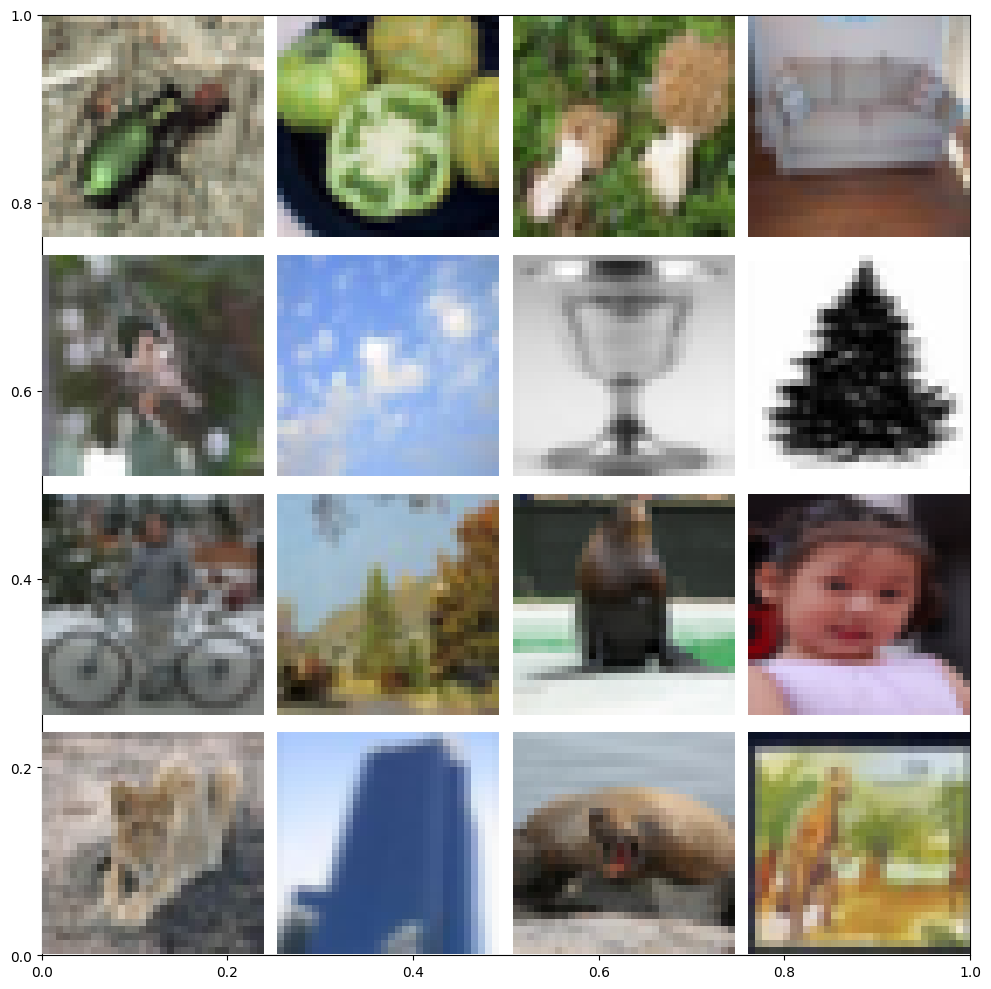

labels[34659].shape: (1,)
imgs[34659].shape: (32, 32, 3)


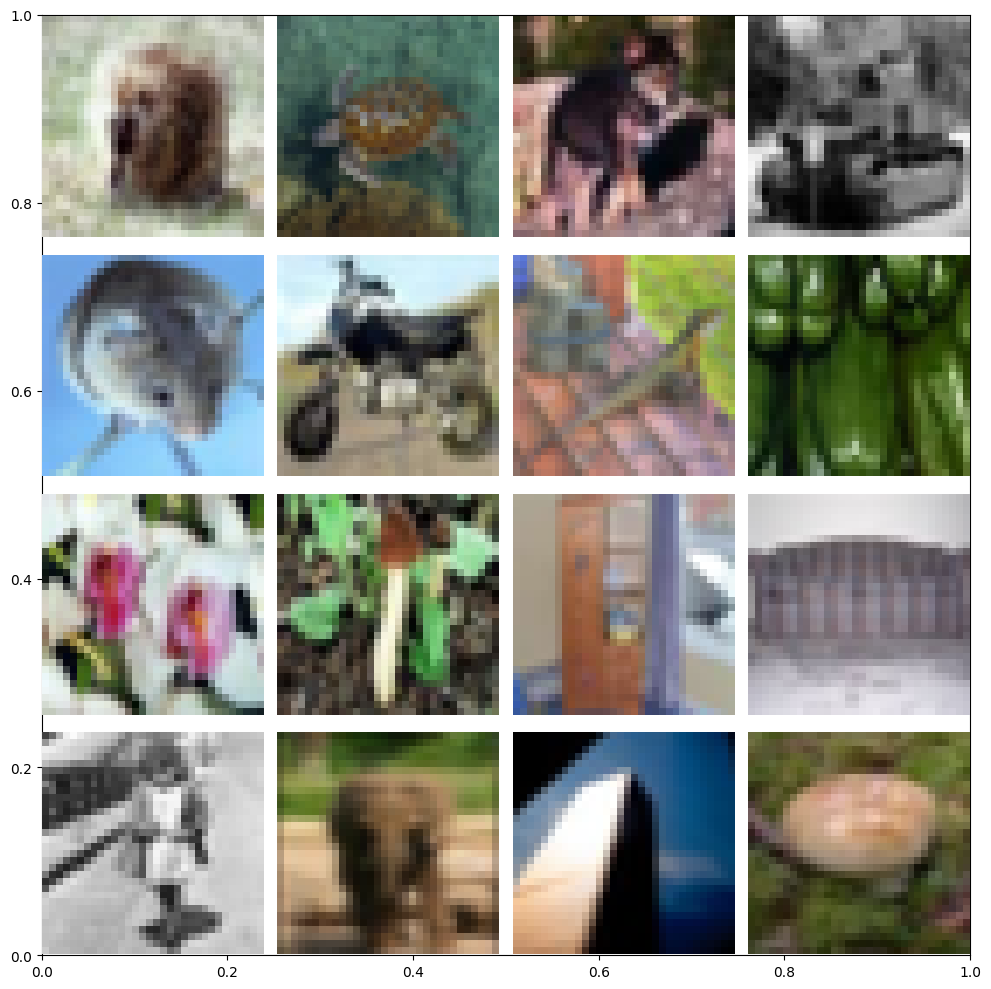

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


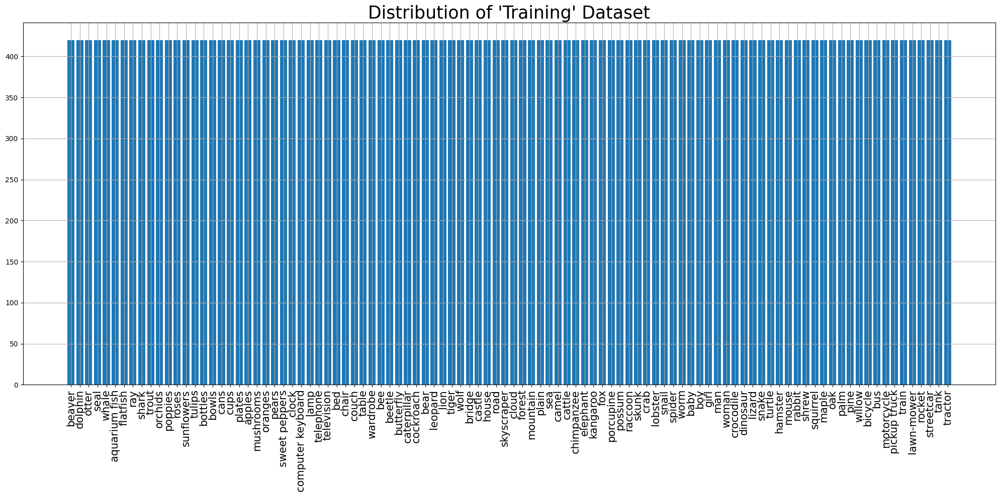

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


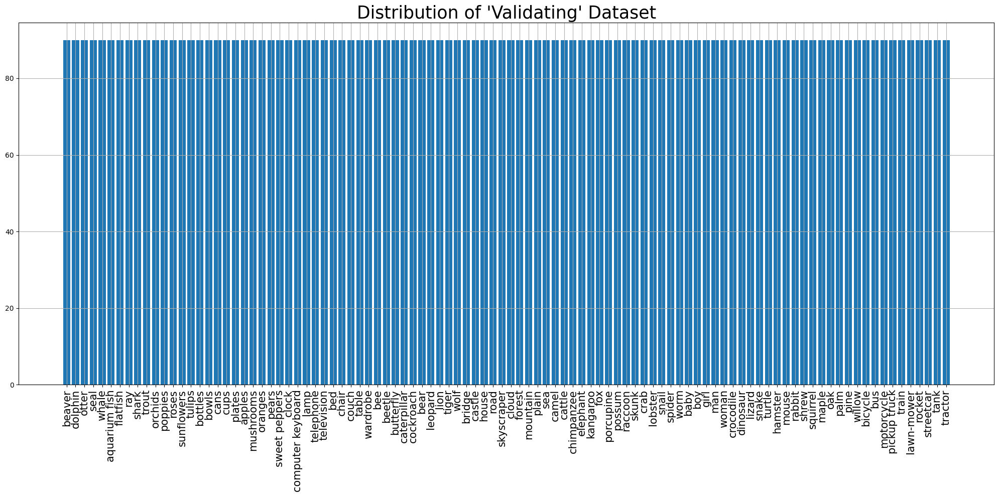

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


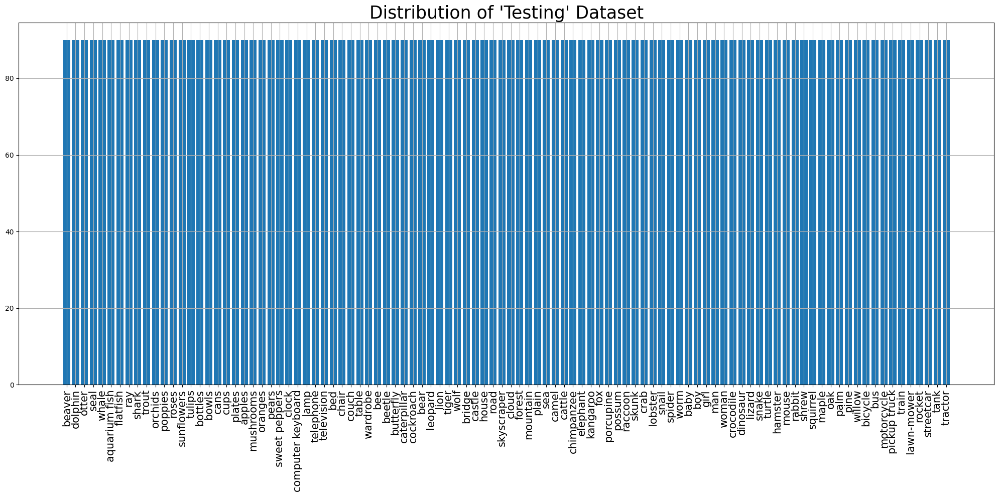

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 32, 32, 3)
(64, 100)
Model input shape: (None, 32, 32, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 32, 32, 3) (64, 100)




Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 1, 1, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 25s 23ms/step - accuracy: 0.0749 - f1_score: 0.0621 - loss: 4.2987 - precision: 0.4699 - val_accuracy: 0.1408 - val_f1_score: 0.1230 - val_loss: 3.7978 - val_precision: 0.6384
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1581 - f1_score: 0.1436 - loss: 3.6788 - precision: 0.6359 - val_accuracy: 0.1554 - val_f1_score: 0.1400 - val_loss: 3.6740 - val_precision: 0.6552
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1943 - f1_score: 0.1822 - loss: 3.4354 - precision: 0.7050 - val_accuracy: 0.1629 - val_f1_score: 0.1489 - val_loss: 3.6369 - val_precision: 0.6185
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2239 - f1_score: 0.2138 - loss: 3.2610 - precision: 0.7482 - val_accuracy: 0.1624 - val_f1_score: 0.1494 - val_loss: 3.6286 - val_precision: 0.5961
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2480 - f1_score: 0.2391 - loss: 3.1222 - precision: 0.7702 - val_accuracy: 0

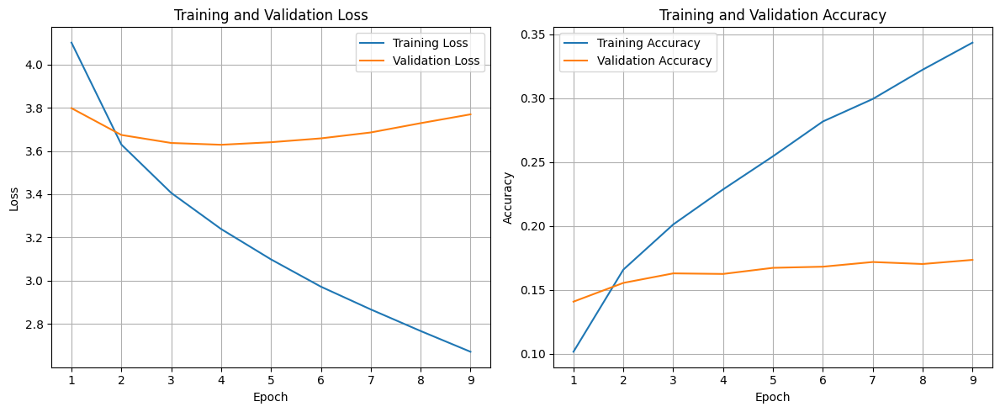

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1676 - f1_score: 0.1507 - loss: 3.6457 - precision: 0.5236
Test Accuracy: 16.58%
Test Loss: 363.47%
Test Precision: 54.89%
Test F1 Scores (Per Class): [40.71856   14.49275    4.347822   2.1739125  4.6511593  6.3694224
  7.499995  18.473892  16.788317  31.92488   17.68707    6.8965464
 10.08403   13.970584   8.917193   4.291841  28.571424  21.395344
  3.260865   3.0075147 28.959269  14.906828  34.95145   22.619043
 31.249994  14.912277   7.633584  11.320749  16.91542   12.5714245
 17.872335   4.8543644 12.121208  16.201115   7.5313764  0.
 11.612898   0.         0.        36.17021    9.090906  30.45267
  9.374996  15.789469   4.30107    5.504585   6.6666617 22.758615
 13.253008  19.166664   3.5294068 14.906828  25.592411  45.9893
 20.242912   0.        24.647882  14.358971   6.097556  13.636359
 37.037033  45.197735  29.23976    9.708734   3.738315   0.
  7.6190457 12.949636  17.82178   19.108276  18.543041  29.482063
  9.655169  19

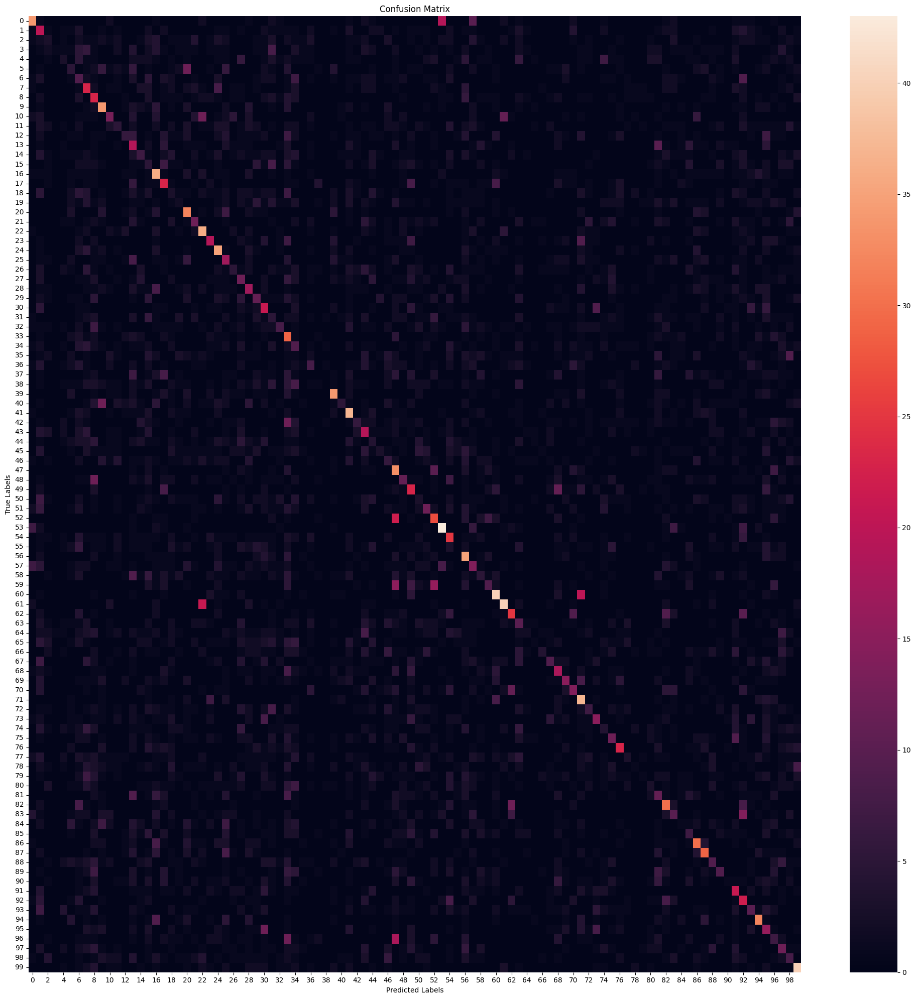

                   precision    recall  f1-score   support

           beaver       0.44      0.38      0.41        90
          dolphin       0.11      0.22      0.14        90
            otter       0.06      0.03      0.04        90
             seal       0.50      0.01      0.02        90
            whale       0.07      0.03      0.05        90
    aquarium fish       0.07      0.06      0.06        90
         flatfish       0.06      0.10      0.08        90
              ray       0.14      0.26      0.18        90
            shark       0.12      0.26      0.17        90
            trout       0.28      0.38      0.32        90
          orchids       0.23      0.14      0.18        90
          poppies       0.09      0.06      0.07        90
            roses       0.21      0.07      0.10        90
       sunflowers       0.10      0.21      0.14        90
           tulips       0.10      0.08      0.09        90
          bottles       0.04      0.06      0.04       

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 1, 1, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - accuracy: 0.0795 - f1_score: 0.0724 - loss: 7.5436 - precision: 0.1257 - val_accuracy: 0.0911 - val_f1_score: 0.0869 - val_loss: 5.3536 - val_precision: 0.2133
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1059 - f1_score: 0.1023 - loss: 4.8355 - precision: 0.2506 - val_accuracy: 0.1044 - val_f1_score: 0.1004 - val_loss: 4.6005 - val_precision: 0.3012
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1254 - f1_score: 0.1209 - loss: 4.2061 - precision: 0.3730 - val_accuracy: 0.1166 - val_f1_score: 0.1118 - val_loss: 4.3082 - val_precision: 0.3688
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1453 - f1_score: 0.1397 - loss: 3.9132 - precision: 0.4802 - val_accuracy: 0.1233 - val_f1_score: 0.1173 - val_loss: 4.1743 - val_precision: 0.4066
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1659 - f1_score: 0.1585 - loss: 3.7115 - precision: 0.5408 - val_accuracy: 0

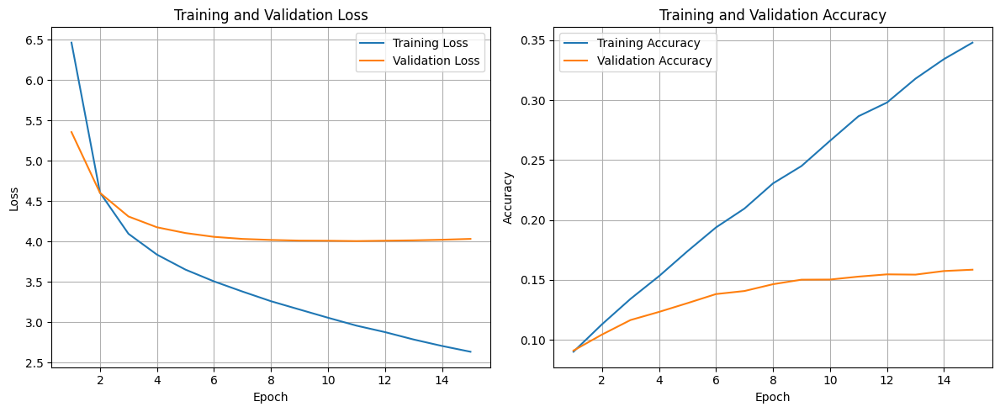

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1478 - f1_score: 0.1371 - loss: 3.9661 - precision: 0.4282
Test Accuracy: 15.26%
Test Loss: 398.12%
Test Precision: 43.46%
Test F1 Scores (Per Class): [46.073296  12.20657    4.1958     3.124996   4.411761  11.904757
  7.9207873 10.891084  12.93532   27.751192  24.86486    5.3691225
 13.636361  13.793098   2.1276546  3.8461492 27.322403  22.707418
  6.1224446  1.3985968 30.107521  13.664591  34.090904  12.682922
 29.53586   10.869559   1.4925328  9.909905  16.080397   6.382974
  7.734802   5.714281   5.7142816 15.311001   4.999995   2.7586157
  7.643307  10.73825    5.3333287 32.352936   5.3333287 36.53846
  7.407403   7.373267   4.733723   5.594401   5.2980084 13.333329
 13.829782  20.512815   1.4814769  6.2499948 37.837833  33.333324
 16.748764   3.1007712 22.707418  18.784527   7.407403   9.876538
 41.53005   42.708324  28.846148   6.172835   6.4516077  2.7397213
  5.7142816 12.871284  12.972969  17.964067  21.39037   27.802685


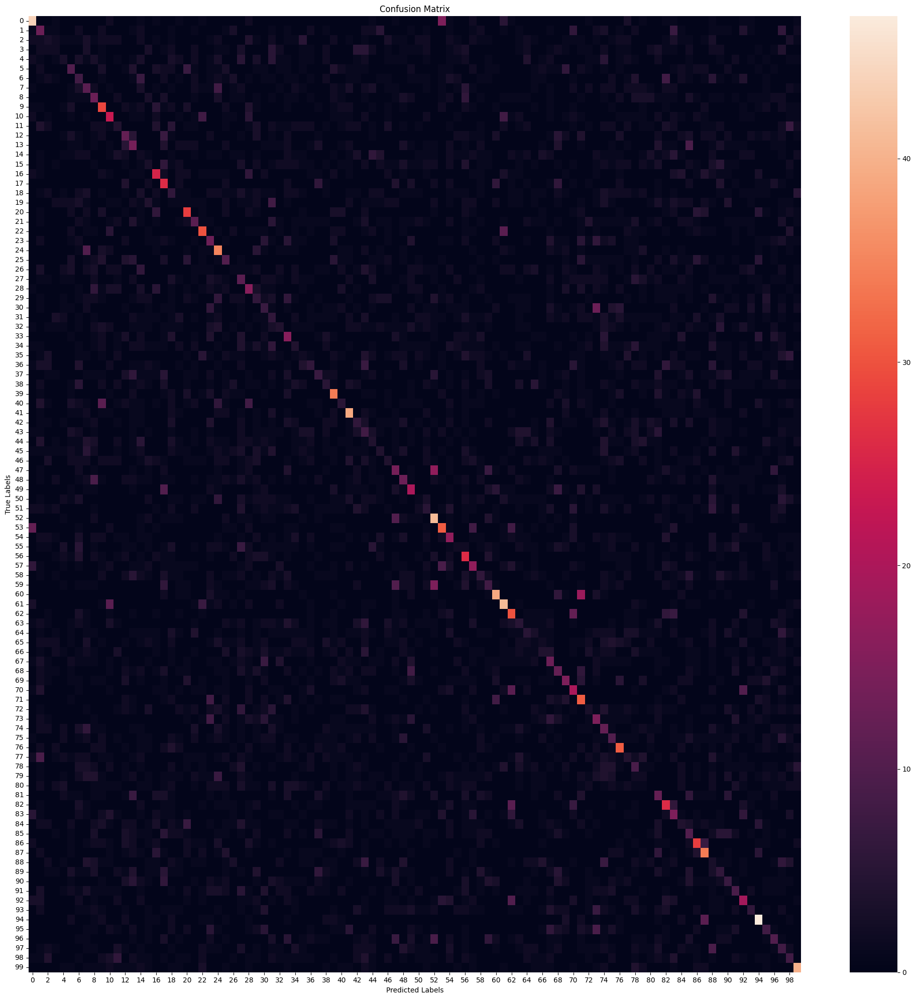

                   precision    recall  f1-score   support

           beaver       0.44      0.49      0.46        90
          dolphin       0.11      0.14      0.12        90
            otter       0.06      0.03      0.04        90
             seal       0.05      0.02      0.03        90
            whale       0.07      0.03      0.04        90
    aquarium fish       0.13      0.11      0.12        90
         flatfish       0.07      0.09      0.08        90
              ray       0.10      0.12      0.11        90
            shark       0.12      0.14      0.13        90
            trout       0.25      0.32      0.28        90
          orchids       0.24      0.26      0.25        90
          poppies       0.07      0.04      0.05        90
            roses       0.14      0.13      0.14        90
       sunflowers       0.12      0.16      0.14        90
           tulips       0.02      0.02      0.02        90
          bottles       0.05      0.03      0.04       

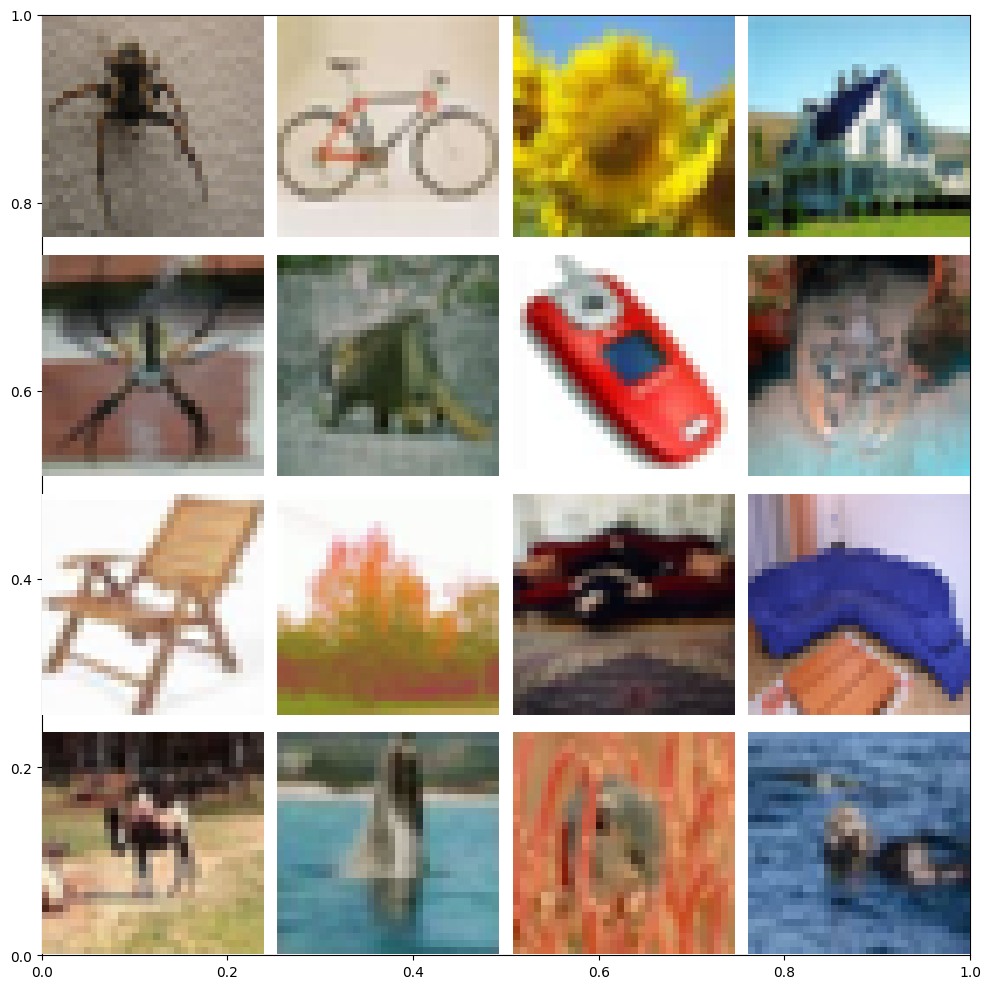

labels[25086].shape: (1,)
imgs[25086].shape: (32, 32, 3)


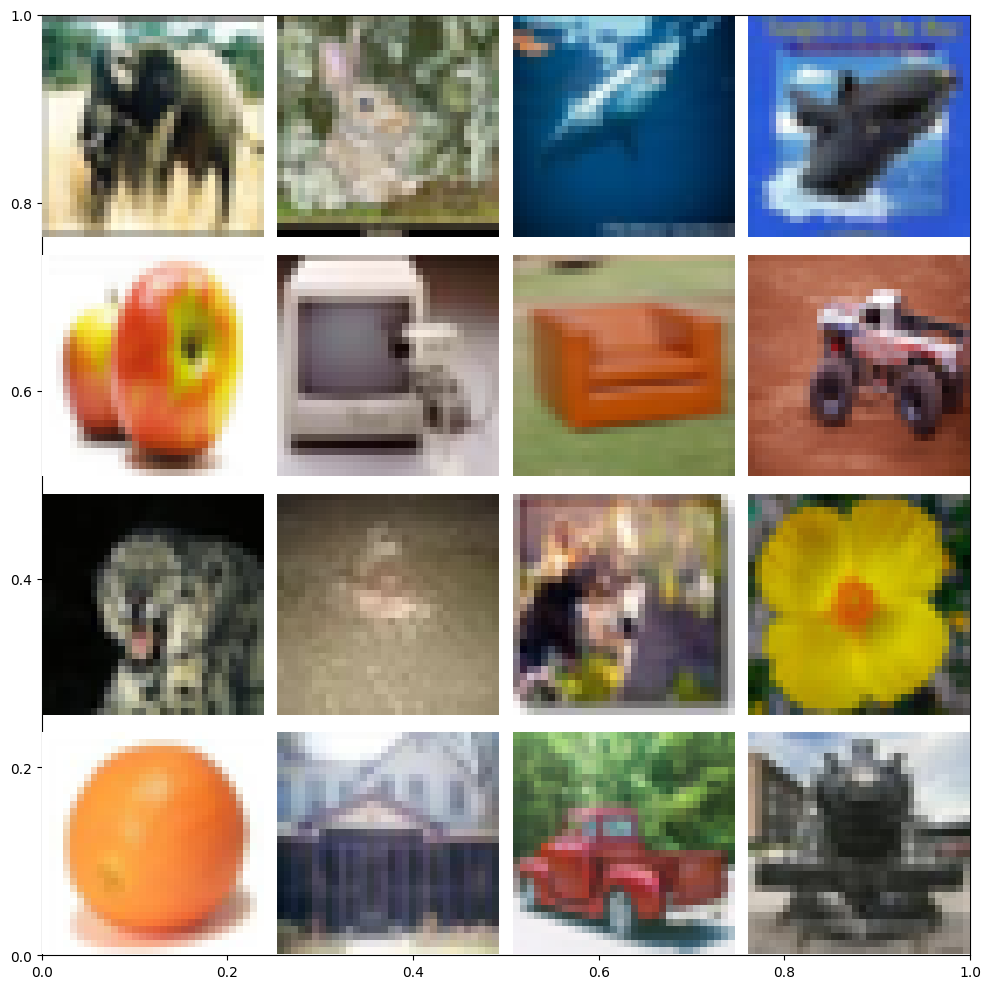

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


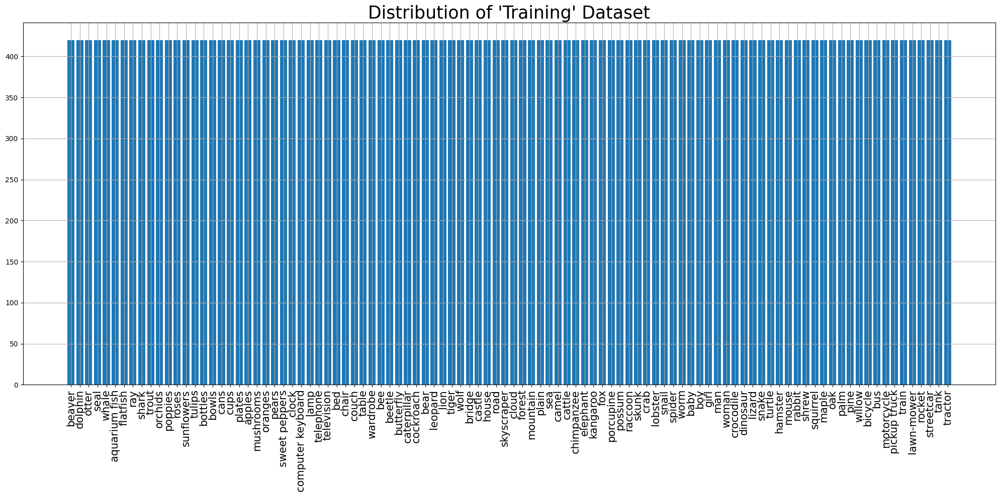

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


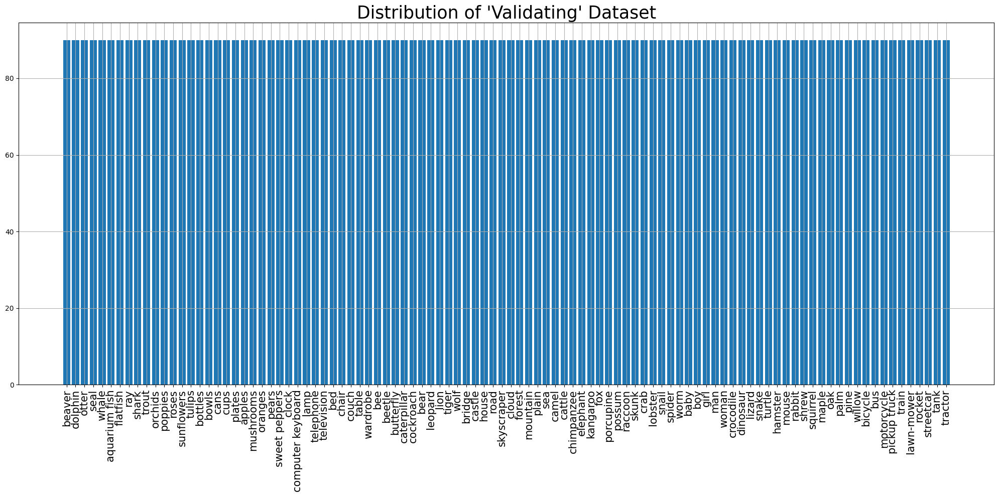

<ipython-input-8-622aedf1e0ac>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


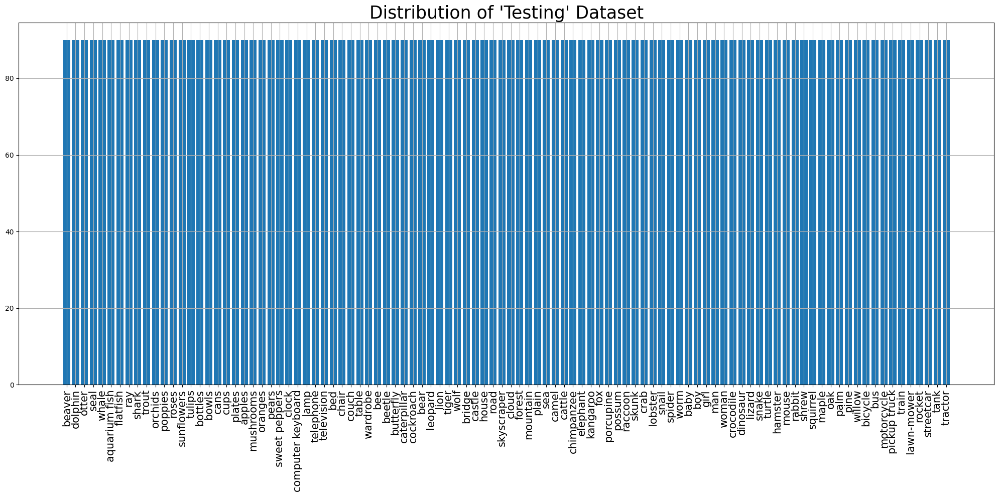

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 32, 32, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 32, 32, 3)
(64, 100)
Model input shape: (None, 32, 32, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 32, 32, 3) (64, 100)




Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 1, 1, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 26s 23ms/step - accuracy: 0.0727 - f1_score: 0.0613 - loss: 4.3075 - precision: 0.4817 - val_accuracy: 0.1409 - val_f1_score: 0.1229 - val_loss: 3.7931 - val_precision: 0.6776
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1569 - f1_score: 0.1436 - loss: 3.6719 - precision: 0.6481 - val_accuracy: 0.1574 - val_f1_score: 0.1422 - val_loss: 3.6705 - val_precision: 0.6284
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1918 - f1_score: 0.1810 - loss: 3.4345 - precision: 0.6875 - val_accuracy: 0.1630 - val_f1_score: 0.1494 - val_loss: 3.6233 - val_precision: 0.5975
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2238 - f1_score: 0.2142 - loss: 3.2612 - precision: 0.7505 - val_accuracy: 0.1683 - val_f1_score: 0.1552 - val_loss: 3.6162 - val_precision: 0.5761
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2544 - f1_score: 0.2453 - loss: 3.1152 - precision: 0.7849 - val_accuracy: 0

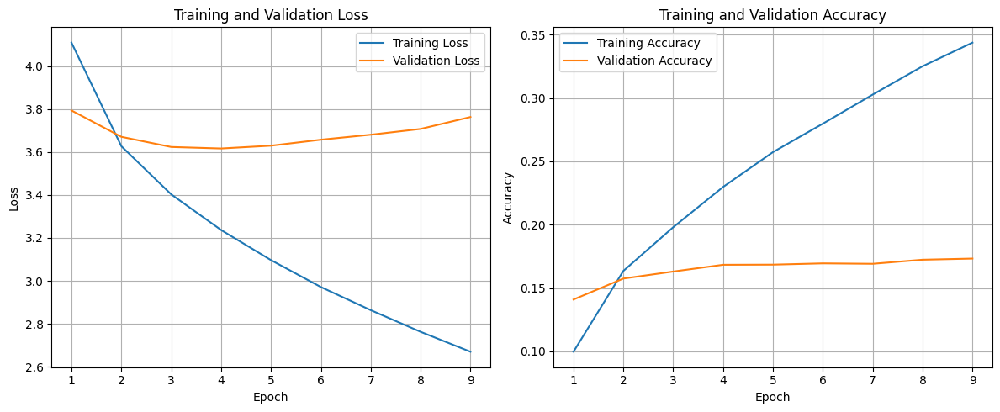

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1699 - f1_score: 0.1524 - loss: 3.6392 - precision: 0.5289
Test Accuracy: 16.91%
Test Loss: 362.40%
Test Precision: 56.05%
Test F1 Scores (Per Class): [48.3146    13.698626   7.3619576  0.         5.755391   4.6242723
  7.2916617 19.45525   19.771858  32.03883   22.377619   5.7970967
 11.320753  14.414412   7.0175385  5.769226  33.63636   21.296293
  5.617973   3.4187999 27.799221  15.789472  34.408596  22.346365
 33.75527   13.145536   6.0150337 10.256405  18.410038  15.05376
 11.822655   5.8479486 10.169488  16.167664   6.106866   0.
  5.988019   0.         0.        35.802464   5.7692285 29.959509
  6.299208  16.450212   4.060909   5.17241    7.2916617 21.27659
 14.634141  20.4918     7.3529363 11.764702  31.481478  45.783127
 16.600786   0.        25.68093   17.441854   9.459455  13.223137
 42.00913   47.0046    36.47058    8.41121    7.0422487  1.9230747
  5.2173877 13.422815  16.888884  18.181814  19.540224  26.905827
  6.622

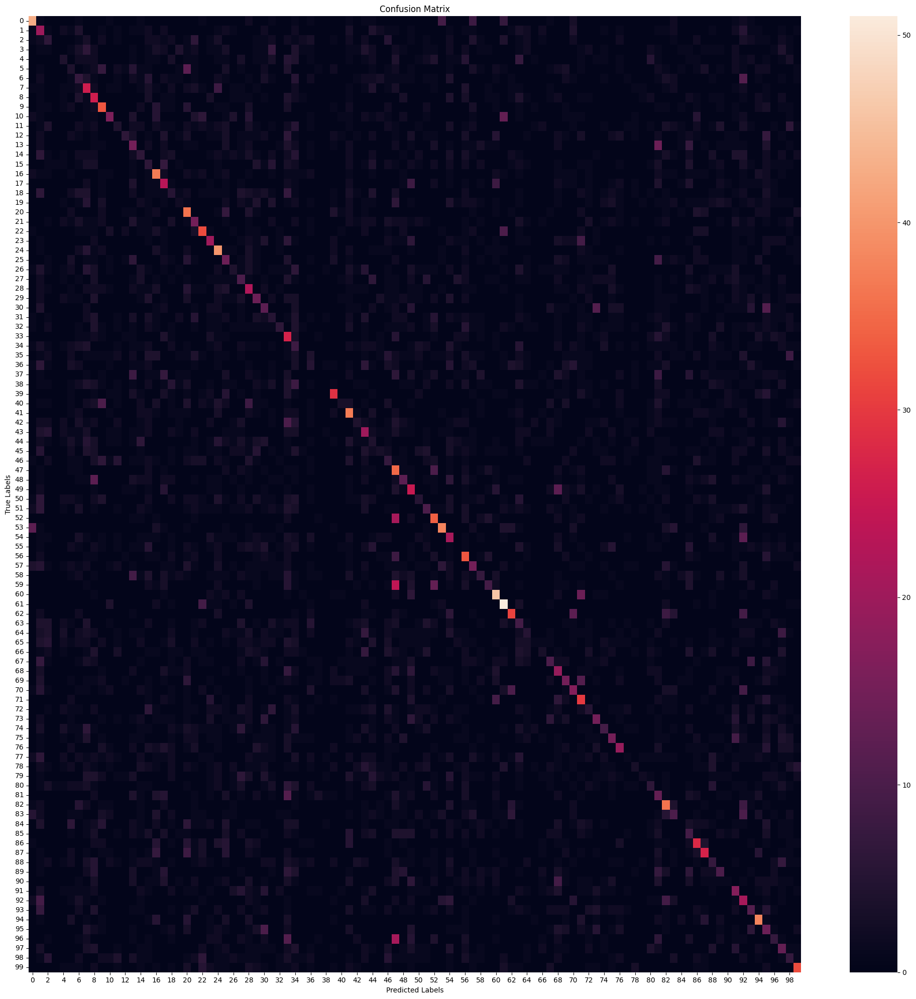

                   precision    recall  f1-score   support

           beaver       0.49      0.48      0.48        90
          dolphin       0.10      0.22      0.14        90
            otter       0.08      0.07      0.07        90
             seal       0.00      0.00      0.00        90
            whale       0.08      0.04      0.06        90
    aquarium fish       0.05      0.04      0.05        90
         flatfish       0.07      0.08      0.07        90
              ray       0.15      0.29      0.20        90
            shark       0.15      0.29      0.20        90
            trout       0.28      0.37      0.32        90
          orchids       0.31      0.18      0.23        90
          poppies       0.08      0.04      0.06        90
            roses       0.38      0.07      0.11        90
       sunflowers       0.11      0.17      0.14        90
           tulips       0.07      0.07      0.07        90
          bottles       0.05      0.07      0.06       

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 1, 1, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - accuracy: 0.0809 - f1_score: 0.0737 - loss: 7.2286 - precision: 0.1287 - val_accuracy: 0.0951 - val_f1_score: 0.0914 - val_loss: 5.2814 - val_precision: 0.2139
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1086 - f1_score: 0.1049 - loss: 4.7857 - precision: 0.2552 - val_accuracy: 0.1073 - val_f1_score: 0.1043 - val_loss: 4.5902 - val_precision: 0.3079
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1289 - f1_score: 0.1252 - loss: 4.1905 - precision: 0.3899 - val_accuracy: 0.1156 - val_f1_score: 0.1107 - val_loss: 4.3024 - val_precision: 0.3662
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1445 - f1_score: 0.1395 - loss: 3.9061 - precision: 0.4698 - val_accuracy: 0.1241 - val_f1_score: 0.1179 - val_loss: 4.1666 - val_precision: 0.4017
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1675 - f1_score: 0.1603 - loss: 3.7062 - precision: 0.5529 - val_accuracy: 0

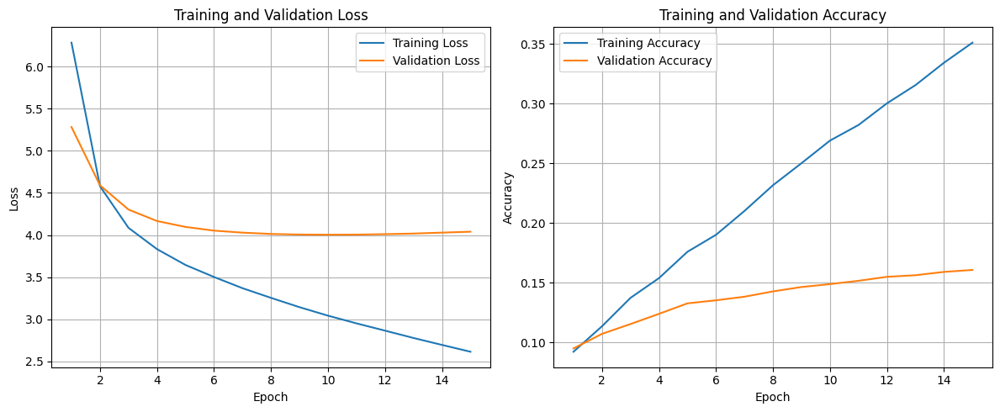

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1499 - f1_score: 0.1385 - loss: 3.9603 - precision: 0.4282
Test Accuracy: 15.22%
Test Loss: 396.16%
Test Precision: 42.93%
Test F1 Scores (Per Class): [51.6129    12.264147   2.797198   2.797198   4.84848    7.777773
  8.743165   7.6086903 14.70588   31.372543  31.818176   5.263153
  9.142853  17.924522   6.796112   3.3707817 27.777773  24.034328
  4.6783576  1.4084461 30.52631    7.8431325 32.978718  14.8471575
 30.708656   9.47368    0.         7.8431325 17.258879  11.594198
  8.16326    8.372088   6.504061  11.353706   2.8168967  6.711405
  4.96894    3.7036994  2.8368747 30.927828   8.695648  33.673462
  1.183427   8.968604   2.4390194  4.28571    5.673754  16.744183
 10.909085  15.306118   4.255315   4.411761  34.25926   38.578674
 10.476186   2.9411721 28.421047  16.766464   6.097556  13.095233
 46.46464   43.29896   26.999994   9.090904   7.3619576  1.3605396
  2.6490018 16.037731  14.857139  17.977526  23.78378   26.905827


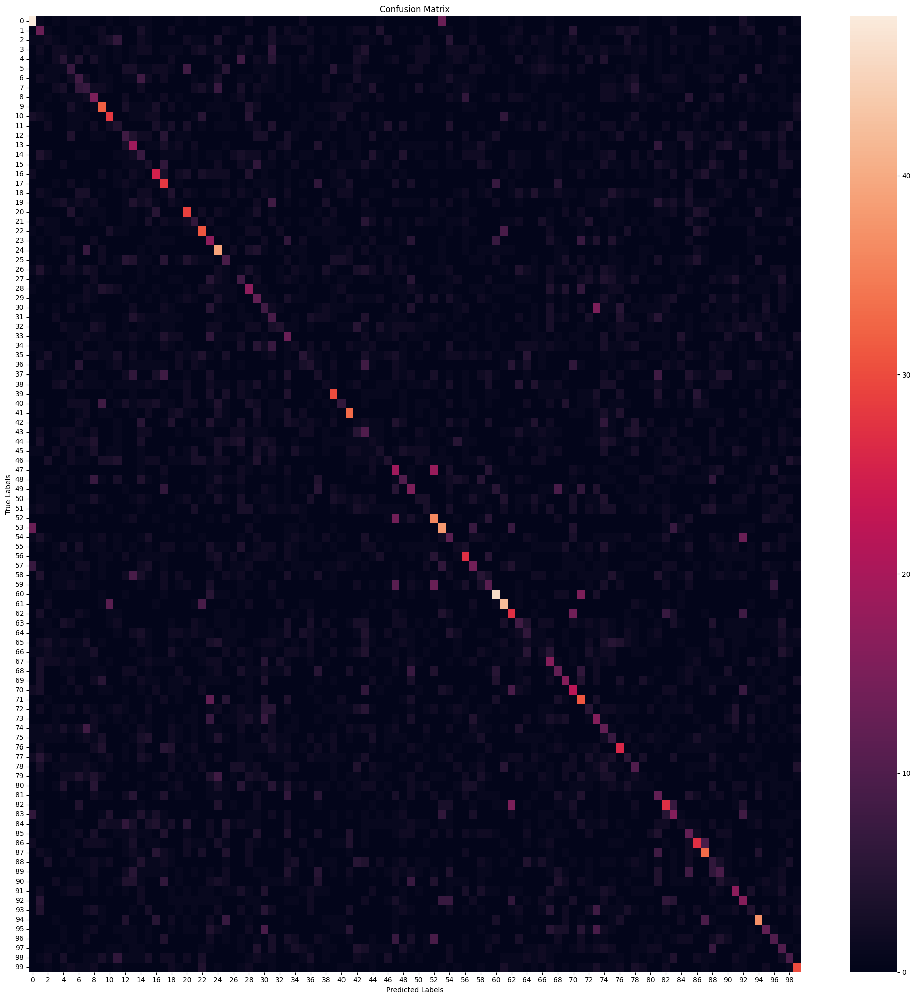

                   precision    recall  f1-score   support

           beaver       0.50      0.53      0.52        90
          dolphin       0.11      0.14      0.12        90
            otter       0.04      0.02      0.03        90
             seal       0.04      0.02      0.03        90
            whale       0.07      0.06      0.06        90
    aquarium fish       0.08      0.08      0.08        90
         flatfish       0.09      0.09      0.09        90
              ray       0.07      0.08      0.08        90
            shark       0.13      0.17      0.15        90
            trout       0.27      0.36      0.31        90
          orchids       0.33      0.31      0.32        90
          poppies       0.06      0.04      0.05        90
            roses       0.09      0.09      0.09        90
       sunflowers       0.16      0.21      0.18        90
           tulips       0.06      0.08      0.07        90
          bottles       0.03      0.03      0.03       

In [8]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (32, 32)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (32, 32)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (32, 32)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(32, 32, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (32, 32))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (32, 32))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (32, 32))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist

# With 128x128

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[23944].shape: (1,)
imgs[23944].shape: (32, 32, 3)


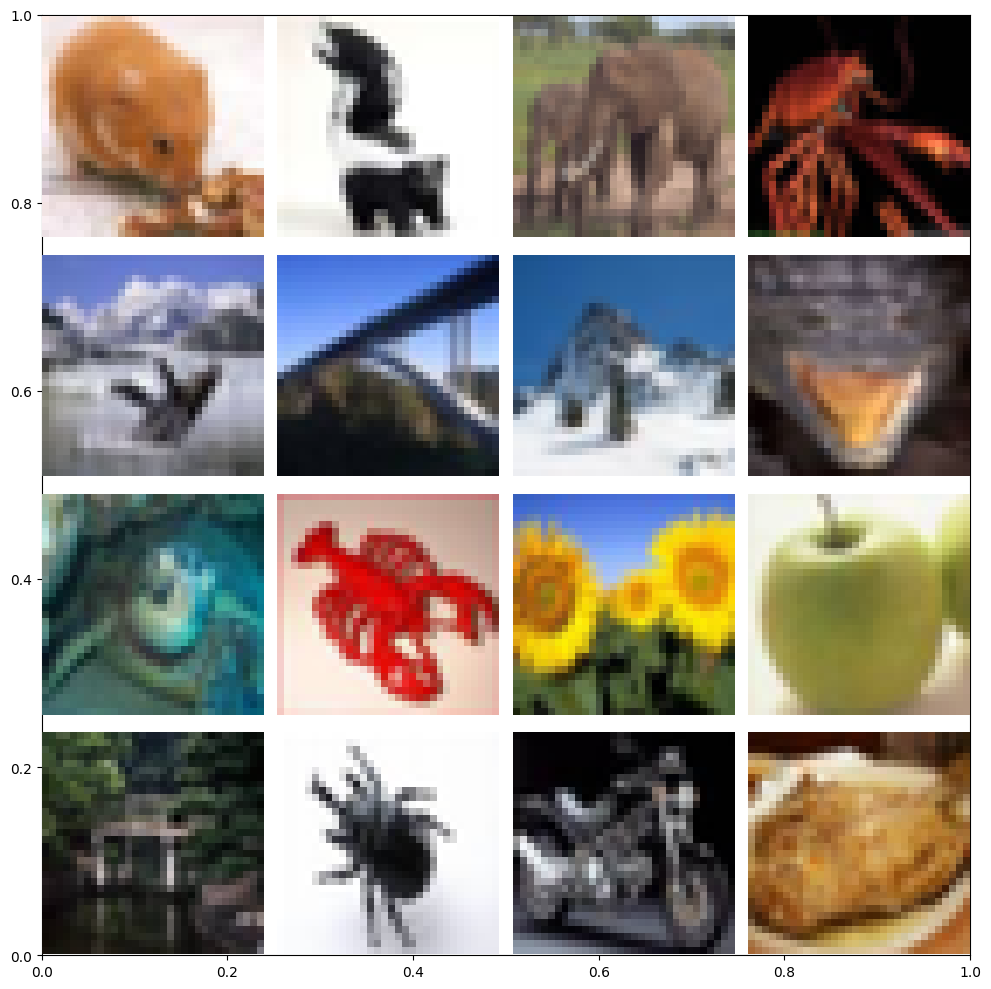

labels[17956].shape: (1,)
imgs[17956].shape: (32, 32, 3)


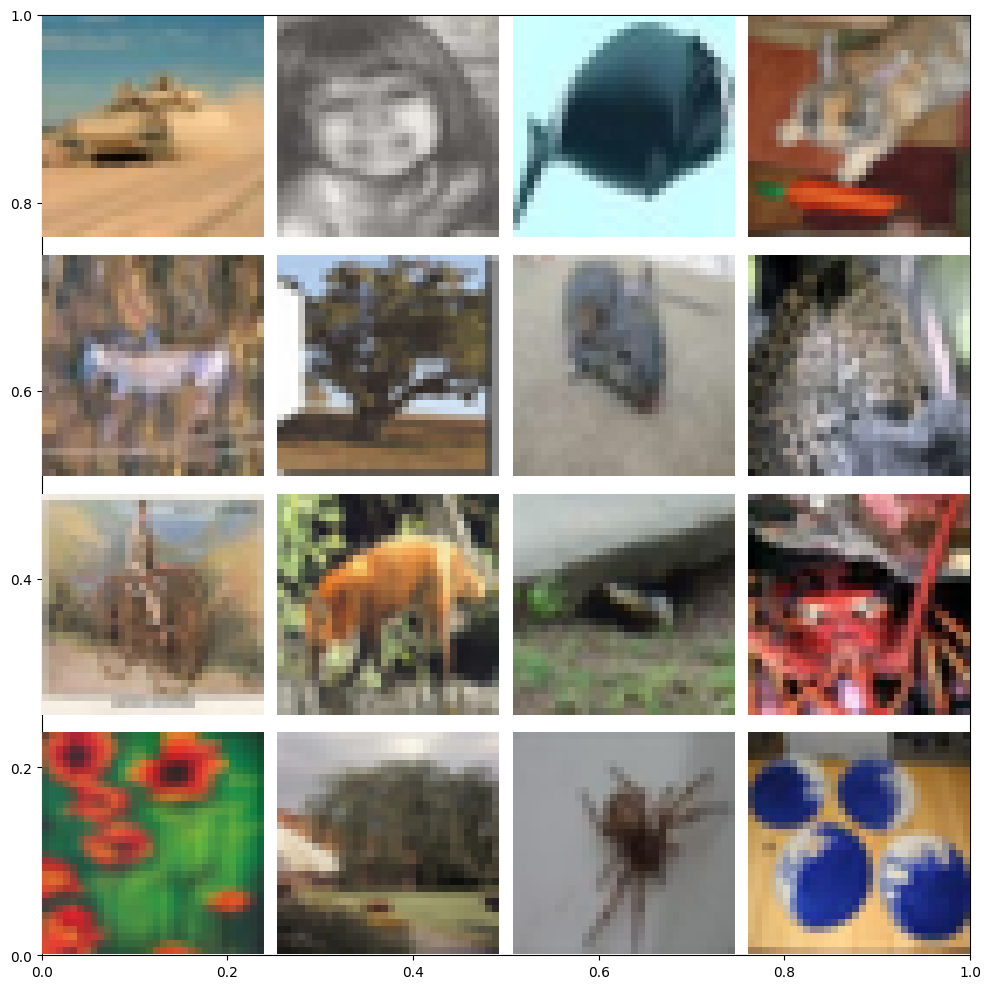

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


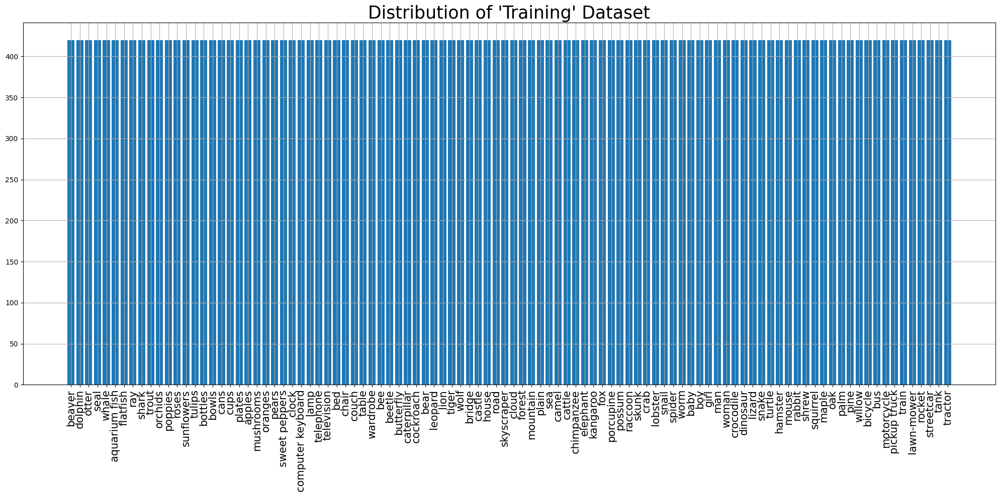

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


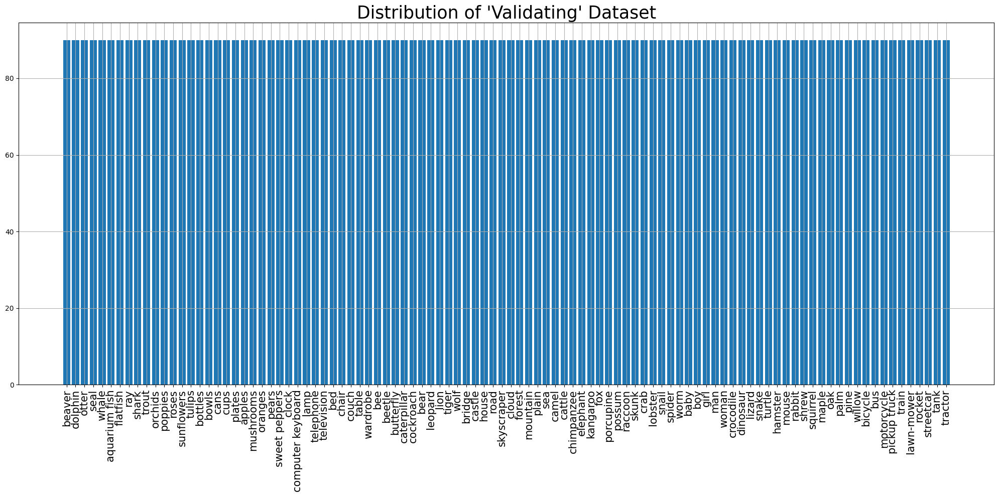

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


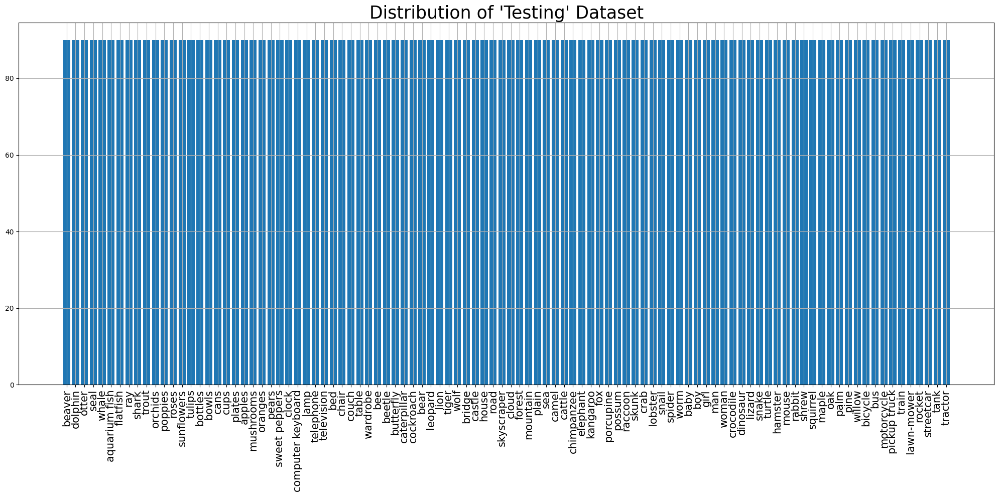

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 128, 128, 3)
(64, 100)
Model input shape: (None, 128, 128, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 128, 128, 3) (6

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 4, 4, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - accuracy: 0.3314 - f1_score: 0.3257 - loss: 2.8621 - precision: 0.6494 - val_accuracy: 0.5221 - val_f1_score: 0.5147 - val_loss: 1.7611 - val_precision: 0.7680
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5208 - f1_score: 0.5167 - loss: 1.7506 - precision: 0.7406 - val_accuracy: 0.5430 - val_f1_score: 0.5381 - val_loss: 1.6580 - val_precision: 0.7515
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5831 - f1_score: 0.5794 - loss: 1.5010 - precision: 0.7765 - val_accuracy: 0.5528 - val_f1_score: 0.5510 - val_loss: 1.6492 - val_precision: 0.7433
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6188 - f1_score: 0.6160 - loss: 1.3292 - precision: 0.7874 - val_accuracy: 0.5660 - val_f1_score: 0.5642 - val_loss: 1.6504 - val_precision: 0.7379
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6545 - f1_score: 0.6513 - loss: 1.1797 - precision: 0.8050 - val_accurac

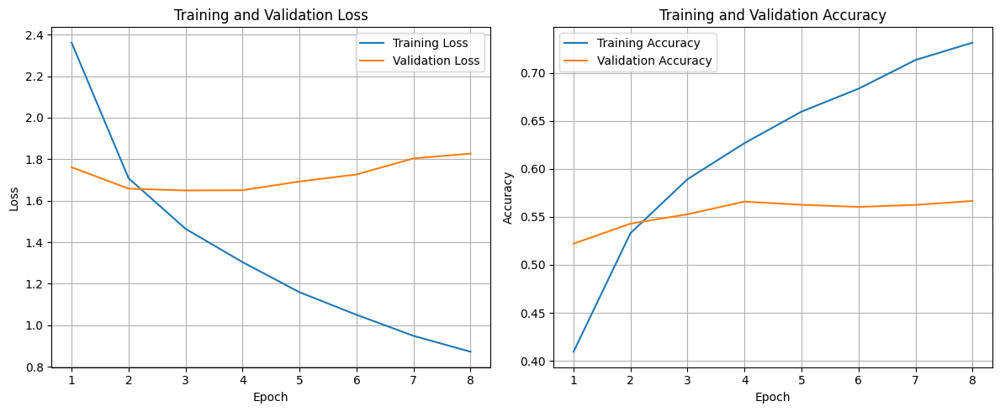

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5436 - f1_score: 0.5360 - loss: 1.6825 - precision: 0.7305
Test Accuracy: 54.83%
Test Loss: 166.37%
Test Precision: 73.19%
Test F1 Scores (Per Class): [76.13636  63.04347  48.38709  34.108524 19.999996 58.461536 46.889946
 59.53488  71.764694 79.329605 43.999992 37.41935  55.294113 42.857136
 50.61728  42.780743 71.794876 66.96832  51.0204   47.67441  73.14285
 68.0203   73.548386 67.948715 69.73684  45.4054   33.84615  33.526005
 75.675674 55.49132  48.148144 50.704224 38.578674 45.692883 55.60975
 20.168062 60.1227   46.666664 34.28571  84.57142  56.55172  76.24309
 53.14685  58.823524 32.87671  34.246574 43.43891  49.72375  72.04301
 76.041664 26.455025 54.21686  59.66386  84.66257  52.112667 29.54545
 70.15707  62.999992 58.571415 45.255466 72.61904  66.99028  52.499992
 60.571426 28.767118 40.816322 53.691273 39.423065 78.21229  79.31035
 55.14018  69.69697  33.519547 44.57831  35.838146 72.04301  79.775276
 55.24861  63.3333

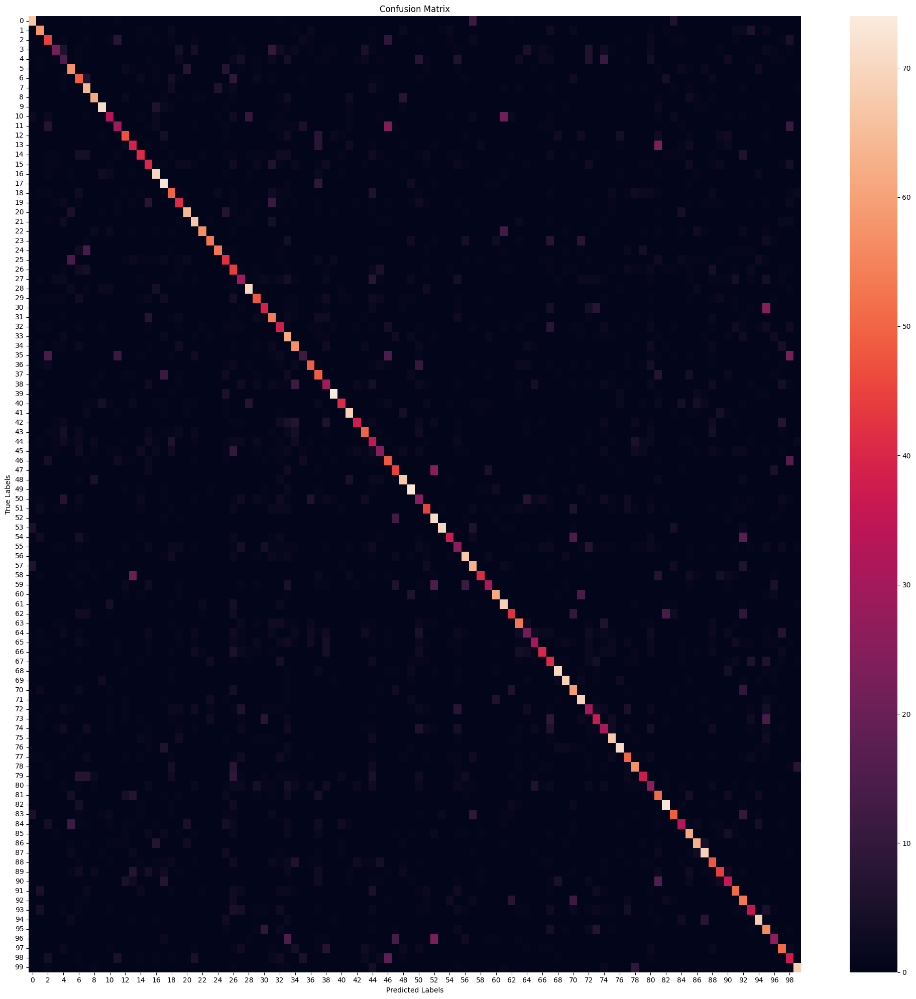

                   precision    recall  f1-score   support

           beaver       0.78      0.74      0.76        90
          dolphin       0.62      0.64      0.63        90
            otter       0.47      0.50      0.48        90
             seal       0.56      0.24      0.34        90
            whale       0.22      0.17      0.19        90
    aquarium fish       0.54      0.63      0.58        90
         flatfish       0.41      0.54      0.47        90
              ray       0.51      0.71      0.60        90
            shark       0.76      0.68      0.72        90
            trout       0.80      0.79      0.79        90
          orchids       0.55      0.37      0.44        90
          poppies       0.45      0.32      0.37        90
            roses       0.59      0.52      0.55        90
       sunflowers       0.42      0.43      0.43        90
           tulips       0.57      0.46      0.51        90
          bottles       0.41      0.44      0.43       

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 4, 4, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 37s 33ms/step - accuracy: 0.5701 - f1_score: 0.5663 - loss: 1.5950 - precision: 0.8259 - val_accuracy: 0.5583 - val_f1_score: 0.5563 - val_loss: 1.6428 - val_precision: 0.7655
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6285 - f1_score: 0.6246 - loss: 1.3215 - precision: 0.8368 - val_accuracy: 0.5711 - val_f1_score: 0.5691 - val_loss: 1.6036 - val_precision: 0.7529
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6591 - f1_score: 0.6552 - loss: 1.1992 - precision: 0.8478 - val_accuracy: 0.5769 - val_f1_score: 0.5748 - val_loss: 1.5820 - val_precision: 0.7485
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6783 - f1_score: 0.6749 - loss: 1.1152 - precision: 0.8582 - val_accuracy: 0.5820 - val_f1_score: 0.5797 - val_loss: 1.5681 - val_precision: 0.7472
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6971 - f1_score: 0.6938 - loss: 1.0433 - precision: 0.8654 - val_acc

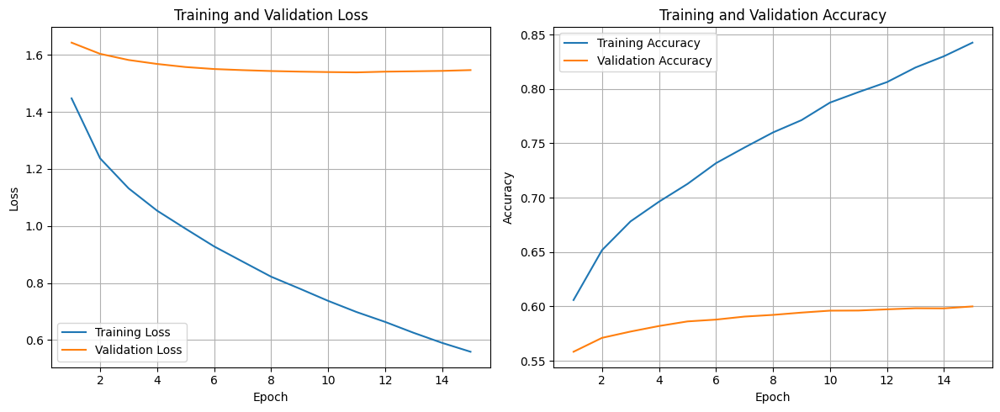

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5901 - f1_score: 0.5822 - loss: 1.5820 - precision: 0.7229
Test Accuracy: 59.40%
Test Loss: 156.85%
Test Precision: 72.75%
Test F1 Scores (Per Class): [77.34807  68.       48.42105  40.86021  28.571424 57.777775 54.838707
 66.666664 73.2558   79.12087  53.191483 38.749992 60.96256  54.44444
 51.764698 51.64835  72.53885  77.15736  50.261772 53.333324 78.85714
 70.71823  79.775276 70.786514 76.83616  47.77777  48.235287 41.176464
 77.9661   56.497173 54.54545  59.880234 45.783127 54.028427 58.757053
 34.730534 67.85713  55.367226 36.649208 86.03351  59.259247 74.999985
 60.818714 55.95237  37.931026 41.025635 45.65217  52.272724 72.222206
 78.30688  34.3949   62.29508  64.921455 84.7826   68.449196 30.409353
 74.71264  71.03825  69.090904 56.818176 73.988434 68.965515 58.56353
 63.73626  40.993782 42.04545  62.72189  47.290634 80.92485  76.8421
 62.14689  72.63157  38.509315 50.279324 39.344257 78.68852  81.56424
 57.303364 64.1711

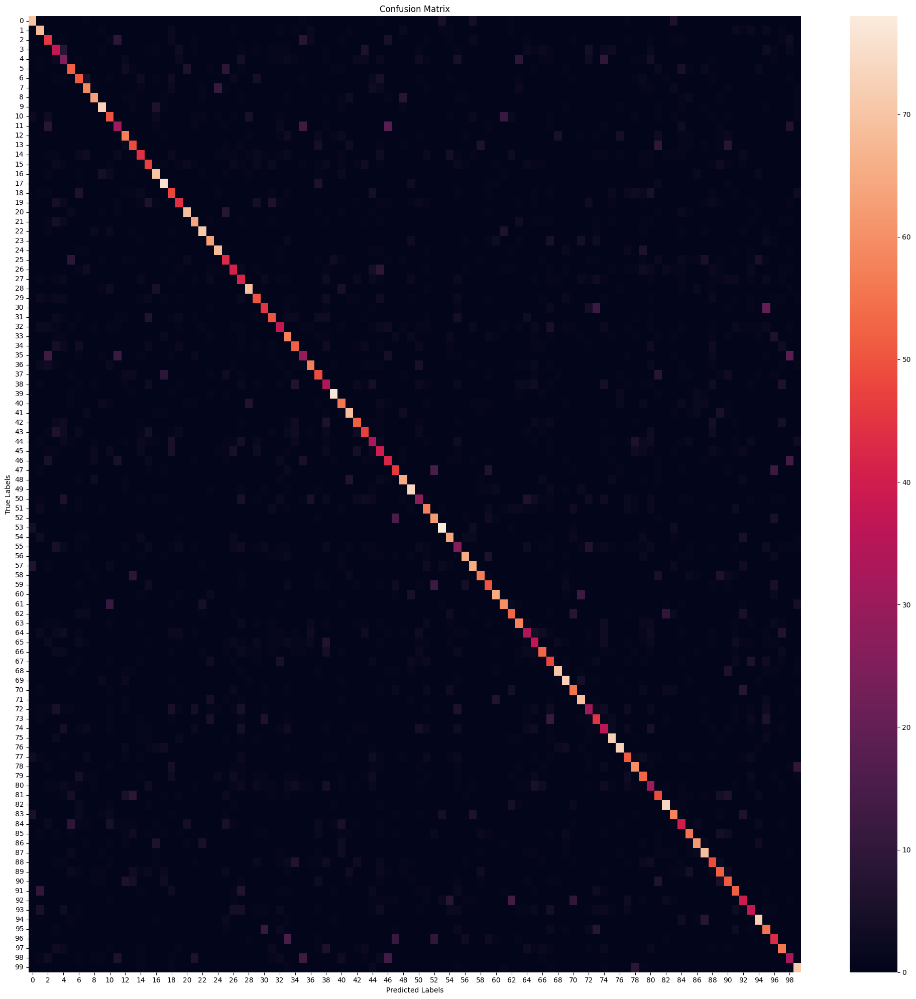

                   precision    recall  f1-score   support

           beaver       0.77      0.78      0.77        90
          dolphin       0.62      0.76      0.68        90
            otter       0.46      0.51      0.48        90
             seal       0.39      0.42      0.41        90
            whale       0.29      0.28      0.29        90
    aquarium fish       0.58      0.58      0.58        90
         flatfish       0.53      0.57      0.55        90
              ray       0.68      0.66      0.67        90
            shark       0.77      0.70      0.73        90
            trout       0.78      0.81      0.80        90
          orchids       0.51      0.56      0.53        90
          poppies       0.44      0.34      0.39        90
            roses       0.59      0.63      0.61        90
       sunflowers       0.54      0.54      0.54        90
           tulips       0.55      0.49      0.52        90
          bottles       0.51      0.52      0.52       

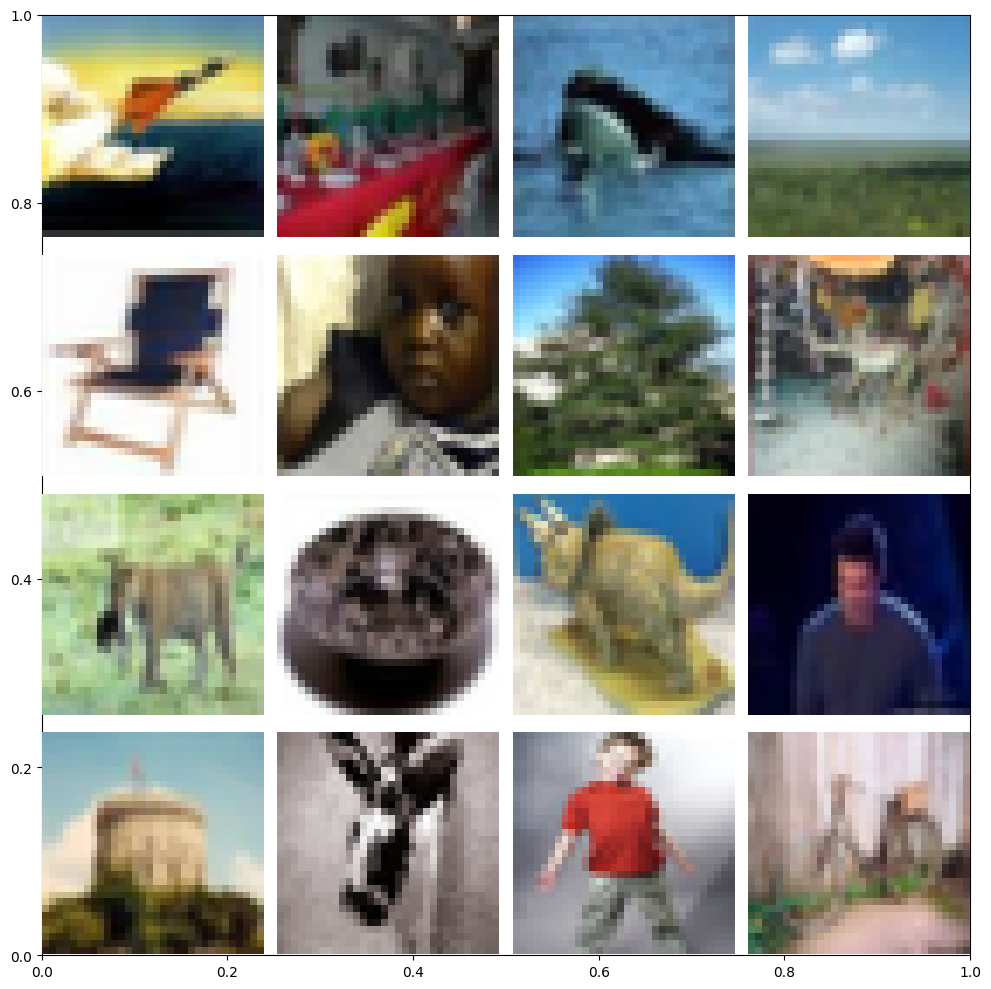

labels[22688].shape: (1,)
imgs[22688].shape: (32, 32, 3)


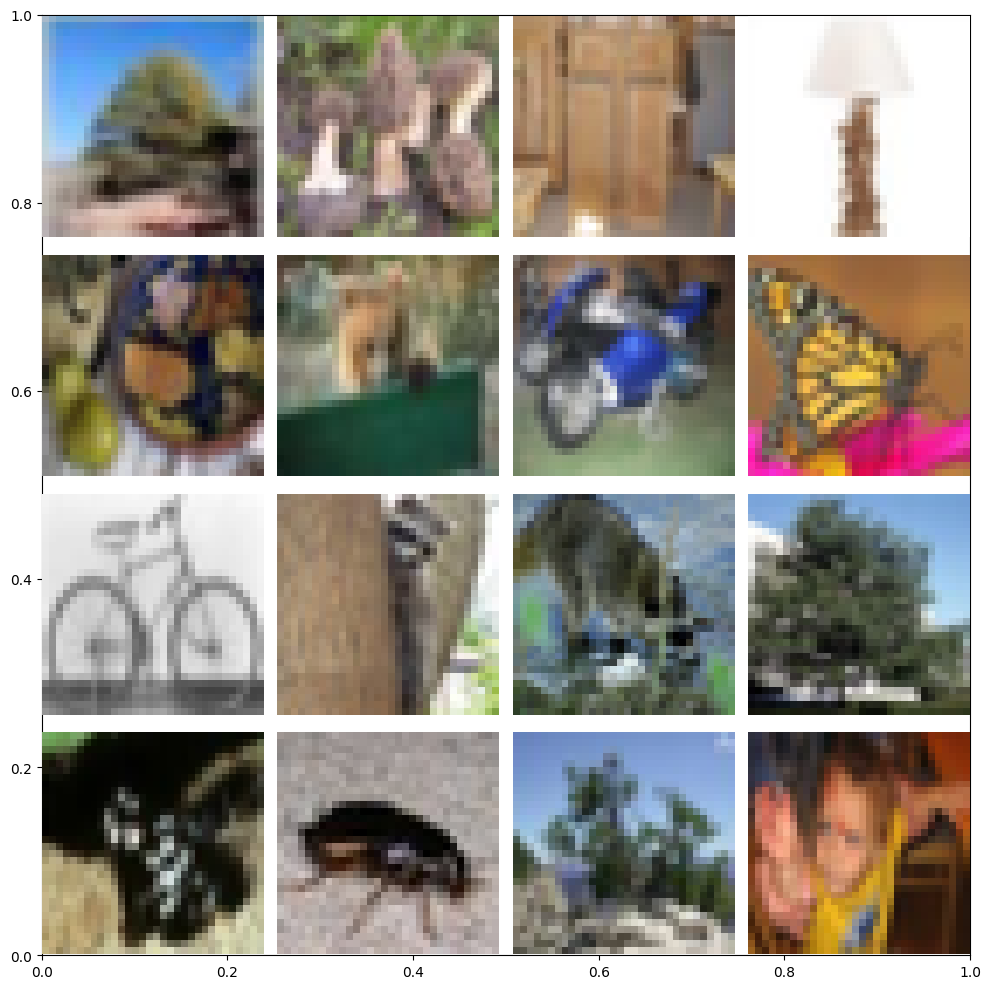

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


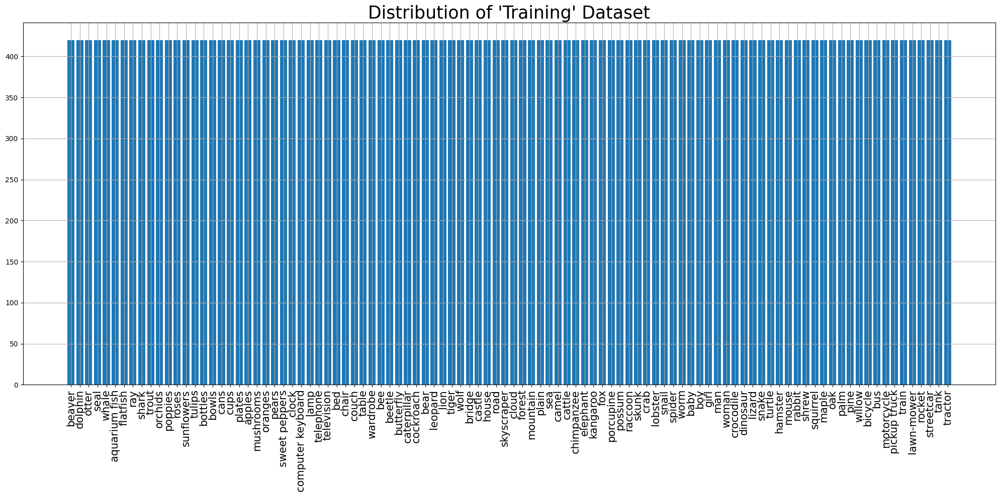

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


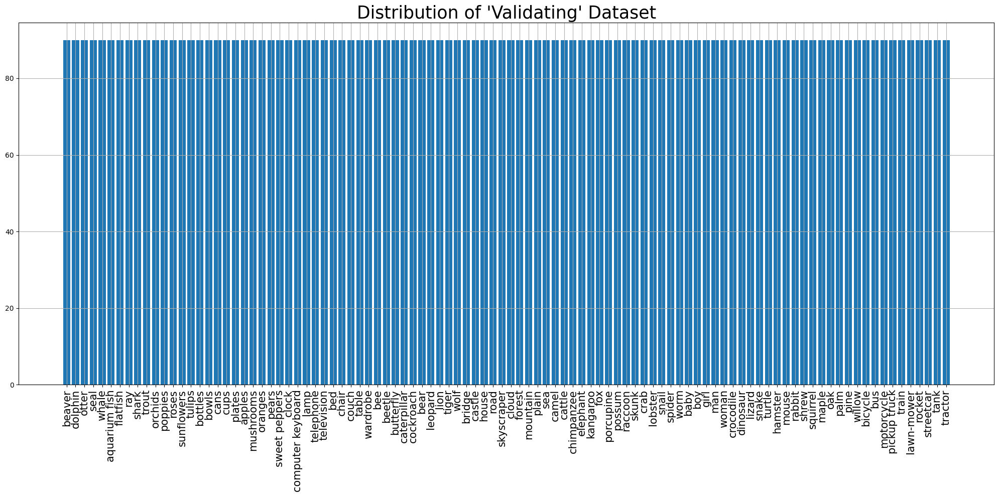

<ipython-input-9-920b20247ba2>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


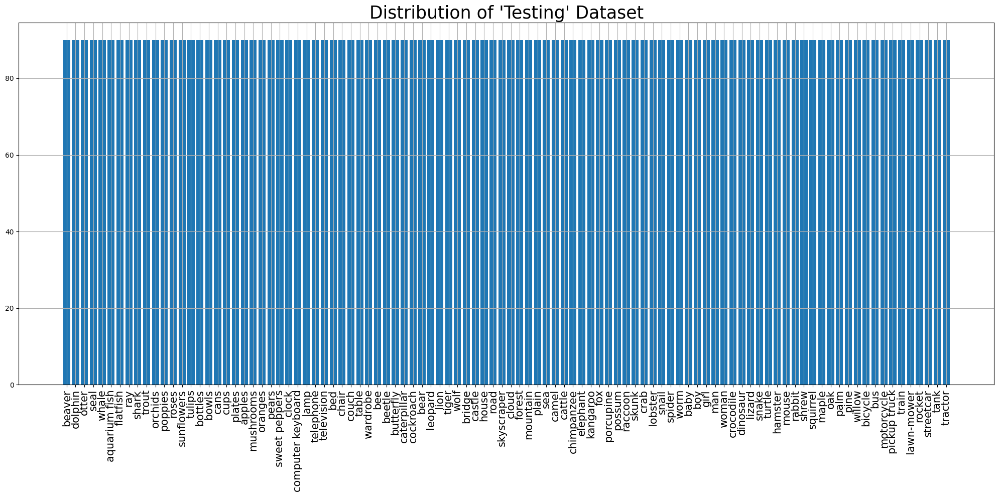

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 128, 128, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 128, 128, 3)
(64, 100)
Model input shape: (None, 128, 128, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 128, 128, 3) (6

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 4, 4, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 30s 29ms/step - accuracy: 0.3302 - f1_score: 0.3249 - loss: 2.8737 - precision: 0.6271 - val_accuracy: 0.5196 - val_f1_score: 0.5120 - val_loss: 1.7644 - val_precision: 0.7632
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5230 - f1_score: 0.5193 - loss: 1.7411 - precision: 0.7430 - val_accuracy: 0.5532 - val_f1_score: 0.5487 - val_loss: 1.6725 - val_precision: 0.7489
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5774 - f1_score: 0.5739 - loss: 1.5100 - precision: 0.7722 - val_accuracy: 0.5556 - val_f1_score: 0.5518 - val_loss: 1.6589 - val_precision: 0.7435
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6155 - f1_score: 0.6120 - loss: 1.3344 - precision: 0.7834 - val_accuracy: 0.5521 - val_f1_score: 0.5490 - val_loss: 1.6626 - val_precision: 0.7239
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6540 - f1_score: 0.6513 - loss: 1.1850 - precision: 0.8104 - val_accurac

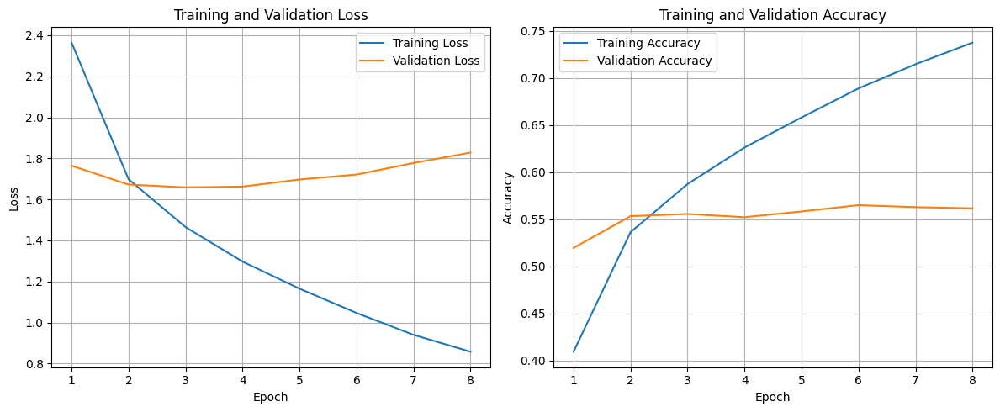

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5474 - f1_score: 0.5367 - loss: 1.6971 - precision: 0.7226
Test Accuracy: 55.62%
Test Loss: 165.59%
Test Precision: 73.98%
Test F1 Scores (Per Class): [77.38094  64.3216   42.23602  24.347824 24.460428 60.355026 44.18604
 57.798153 69.148926 73.40425  49.69696  38.497646 59.090908 44.318172
 52.51396  51.67464  68.852455 77.31957  49.999992 43.529408 74.86033
 66.666664 76.24999  68.74999  61.03895  53.921562 36.220467 33.80281
 76.300575 52.459015 47.33727  51.23152  39.999996 53.88127  58.947365
 19.54887  61.39534  52.023117 43.95604  85.02993  60.869564 75.268814
 47.142853 57.627117 37.837833 36.486485 46.80851  47.577087 66.35513
 77.00535  32.051277 60.52631  56.862743 84.26965  44.28571  26.285711
 73.01586  70.65217  67.948715 49.999992 72.8395   65.67163  52.857136
 55.681812 33.54838  43.708603 54.748596 35.754185 79.329605 73.05389
 55.45454  69.23076  28.571424 53.398056 35.675667 70.46631  78.723404
 49.411755 61.797

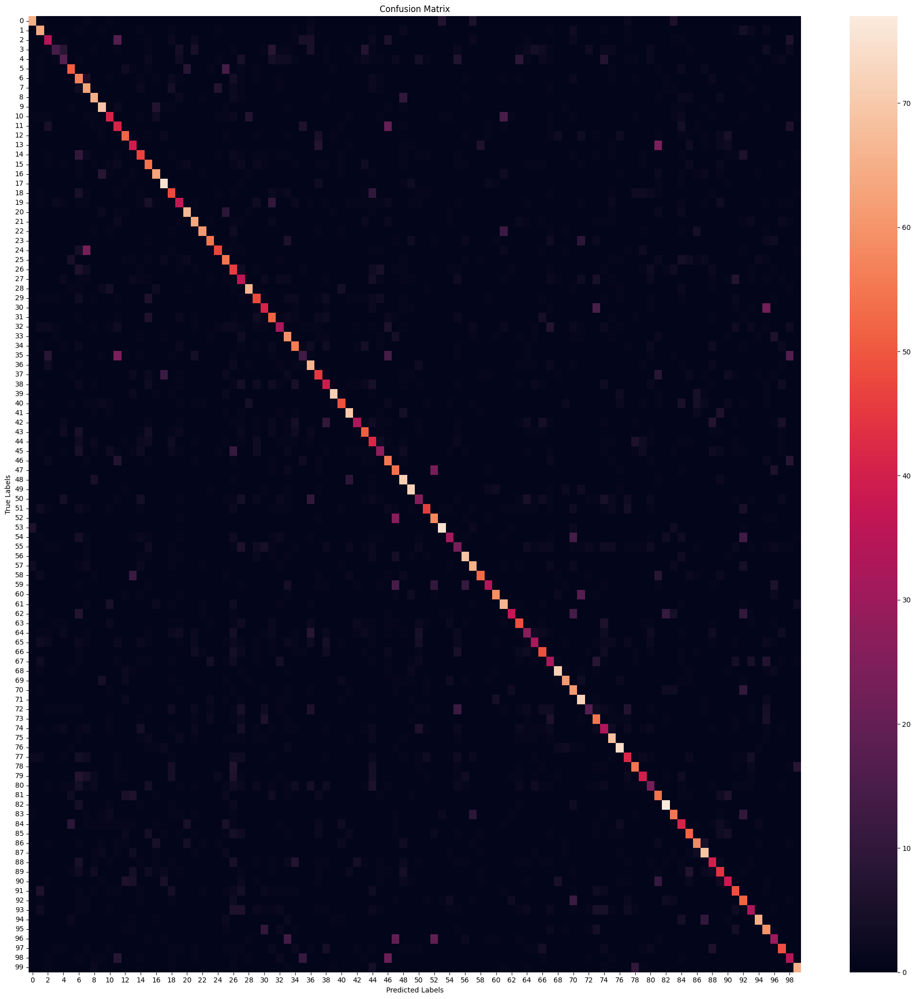

                   precision    recall  f1-score   support

           beaver       0.83      0.72      0.77        90
          dolphin       0.59      0.71      0.64        90
            otter       0.48      0.38      0.42        90
             seal       0.56      0.16      0.24        90
            whale       0.34      0.19      0.24        90
    aquarium fish       0.65      0.57      0.60        90
         flatfish       0.34      0.63      0.44        90
              ray       0.49      0.70      0.58        90
            shark       0.66      0.72      0.69        90
            trout       0.70      0.77      0.73        90
          orchids       0.55      0.46      0.50        90
          poppies       0.33      0.46      0.38        90
            roses       0.60      0.58      0.59        90
       sunflowers       0.45      0.43      0.44        90
           tulips       0.53      0.52      0.53        90
          bottles       0.45      0.60      0.52       

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 4, 4, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 34s 32ms/step - accuracy: 0.5658 - f1_score: 0.5630 - loss: 1.6053 - precision: 0.8227 - val_accuracy: 0.5597 - val_f1_score: 0.5575 - val_loss: 1.6459 - val_precision: 0.7630
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6276 - f1_score: 0.6246 - loss: 1.3224 - precision: 0.8328 - val_accuracy: 0.5699 - val_f1_score: 0.5674 - val_loss: 1.6080 - val_precision: 0.7531
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6600 - f1_score: 0.6567 - loss: 1.2027 - precision: 0.8466 - val_accuracy: 0.5739 - val_f1_score: 0.5715 - val_loss: 1.5892 - val_precision: 0.7487
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6793 - f1_score: 0.6761 - loss: 1.1134 - precision: 0.8579 - val_accuracy: 0.5783 - val_f1_score: 0.5762 - val_loss: 1.5757 - val_precision: 0.7448
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6960 - f1_score: 0.6930 - loss: 1.0433 - precision: 0.8632 - val_acc

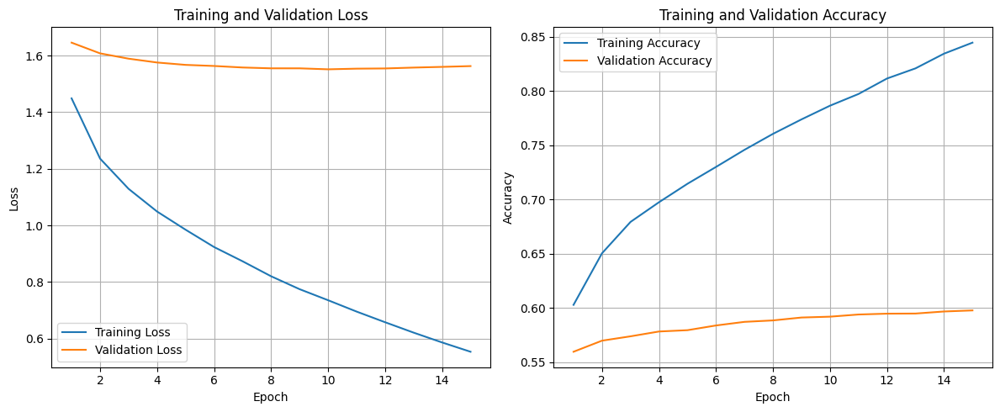

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5806 - f1_score: 0.5723 - loss: 1.5906 - precision: 0.7146
Test Accuracy: 59.42%
Test Loss: 156.21%
Test Precision: 72.84%
Test F1 Scores (Per Class): [76.47058  69.03552  49.735443 45.23809  29.508188 60.227264 56.497173
 62.14689  74.8538   76.43979  53.551907 44.047615 61.538452 51.977394
 52.873566 53.714287 70.46631  73.46938  50.261772 46.98795  77.52808
 67.40331  78.16091  72.13114  73.0337   56.521736 47.727264 36.363632
 75.58139  55.05617  49.122803 61.714287 48.148144 51.851845 57.142853
 34.567894 67.0391   55.865913 40.425526 85.55555  59.7826   81.31868
 50.887566 58.100555 38.54166  41.860455 50.526314 46.78362  75.268814
 77.65957  28.96551  63.218384 58.378376 85.71427  63.589745 29.54545
 76.92307  70.39106  72.289154 60.227264 76.300575 69.99999  61.111103
 61.01694  39.49044  45.74468  62.06896  47.422672 82.02247  77.24867
 59.886997 66.66666  35.92814  57.71144  40.659336 73.01586  79.55801
 50.574715 64.864

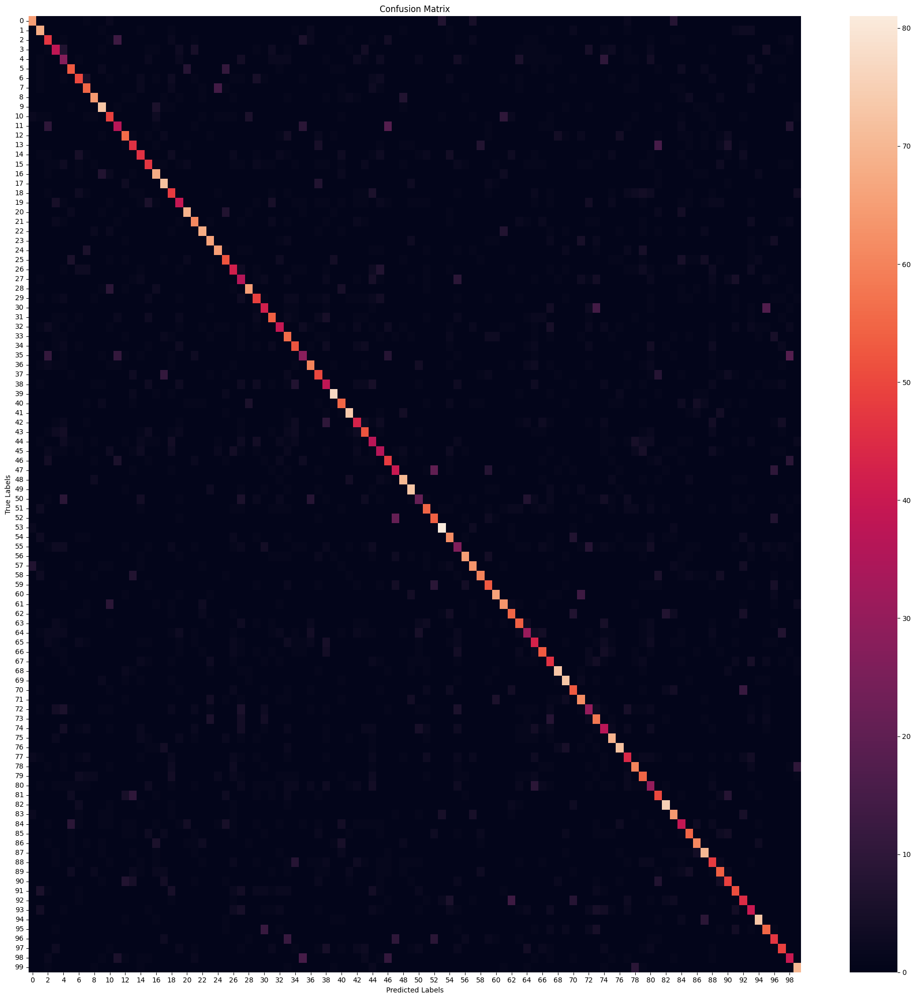

                   precision    recall  f1-score   support

           beaver       0.81      0.72      0.76        90
          dolphin       0.63      0.76      0.69        90
            otter       0.47      0.52      0.50        90
             seal       0.48      0.42      0.45        90
            whale       0.29      0.30      0.30        90
    aquarium fish       0.62      0.59      0.60        90
         flatfish       0.57      0.56      0.56        90
              ray       0.63      0.61      0.62        90
            shark       0.79      0.71      0.75        90
            trout       0.72      0.81      0.76        90
          orchids       0.53      0.54      0.54        90
          poppies       0.47      0.41      0.44        90
            roses       0.61      0.62      0.62        90
       sunflowers       0.53      0.51      0.52        90
           tulips       0.55      0.51      0.53        90
          bottles       0.55      0.52      0.54       

In [9]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (128, 128)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (128, 128)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (128, 128)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (128, 128))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (128, 128))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (128, 128))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist

# With 224x224

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[34127].shape: (1,)
imgs[34127].shape: (32, 32, 3)


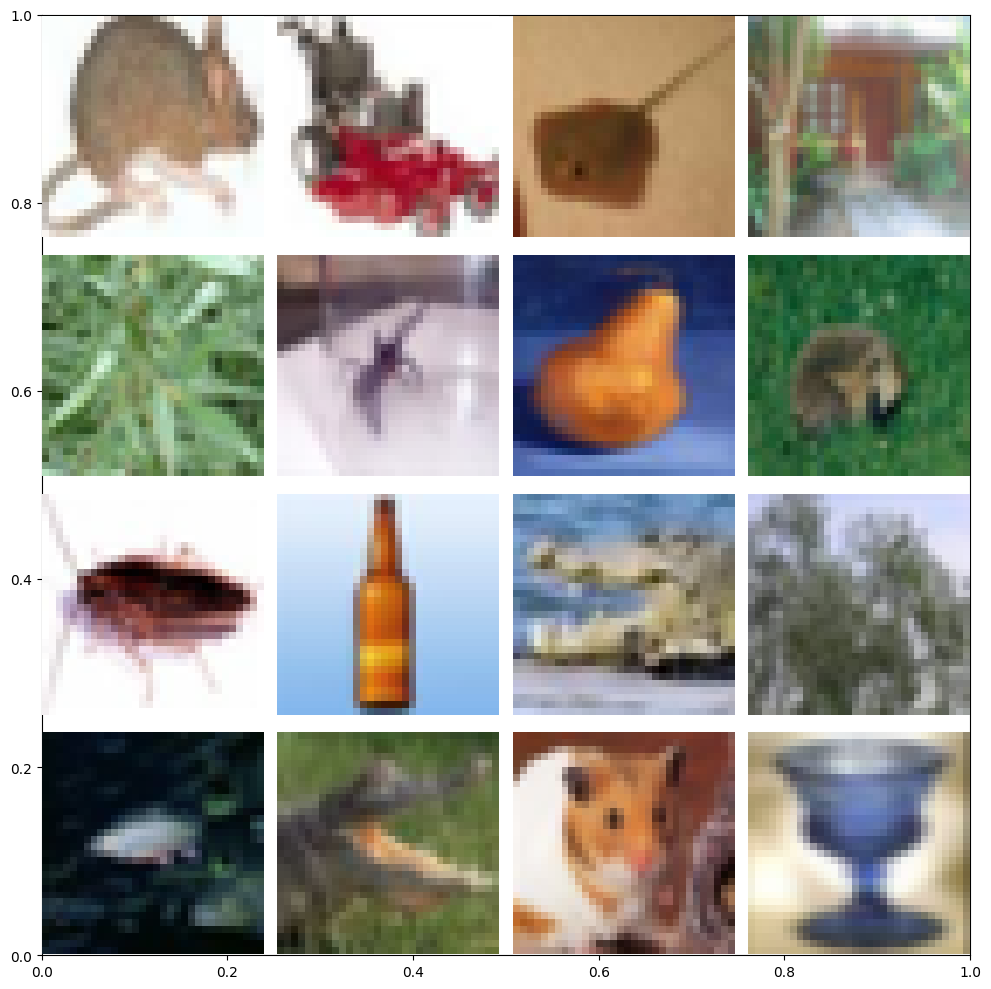

labels[17275].shape: (1,)
imgs[17275].shape: (32, 32, 3)


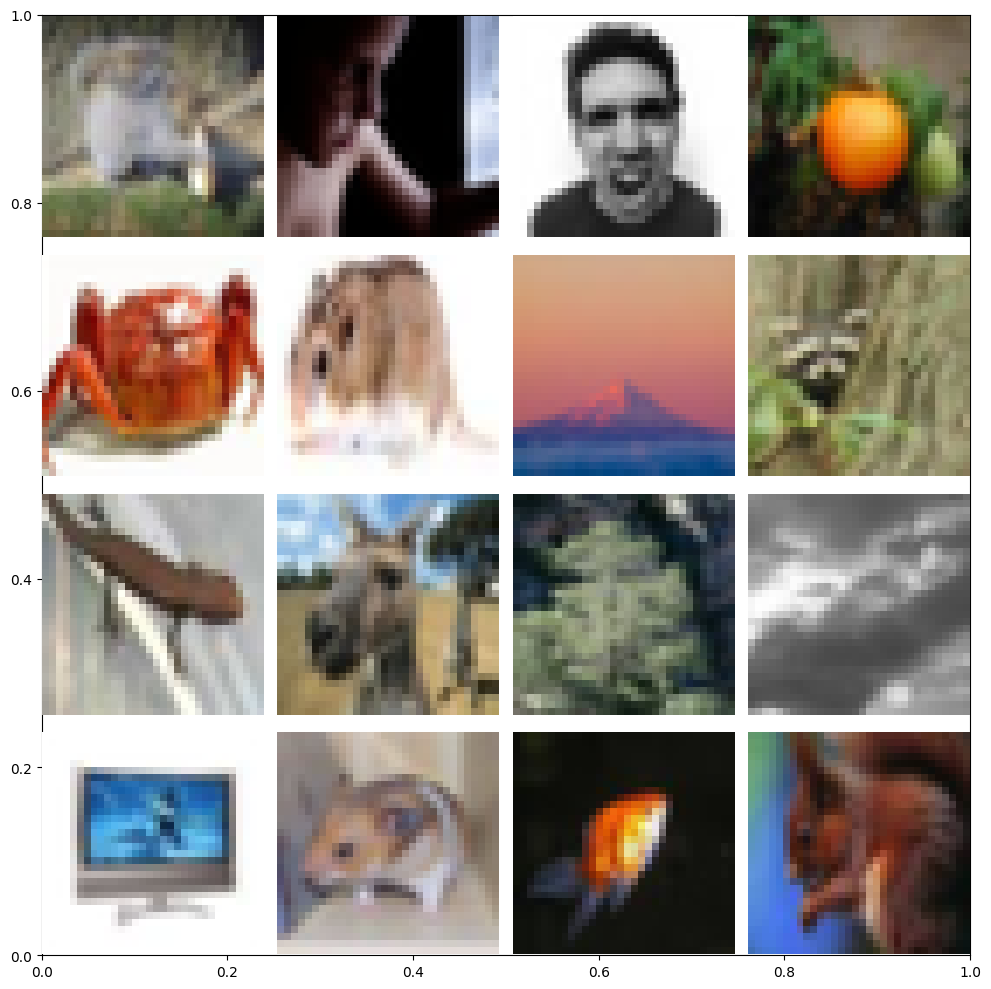

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


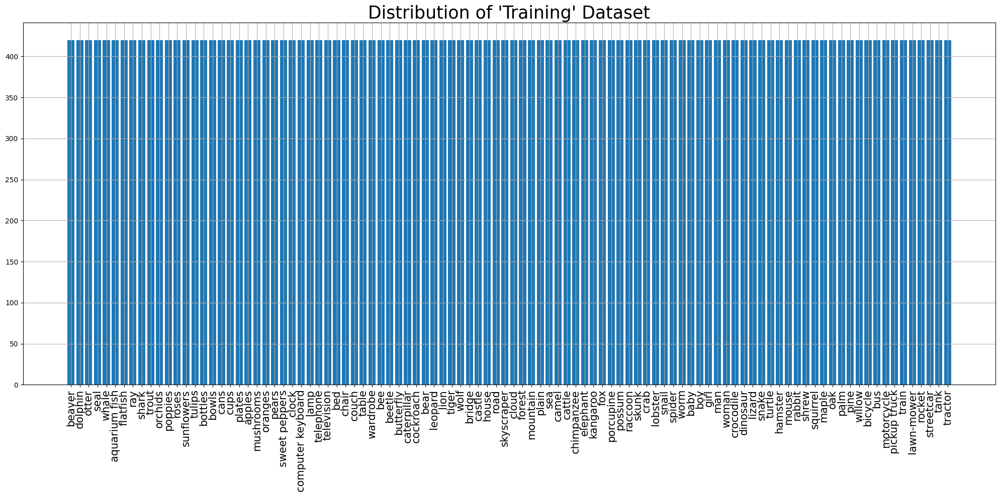

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


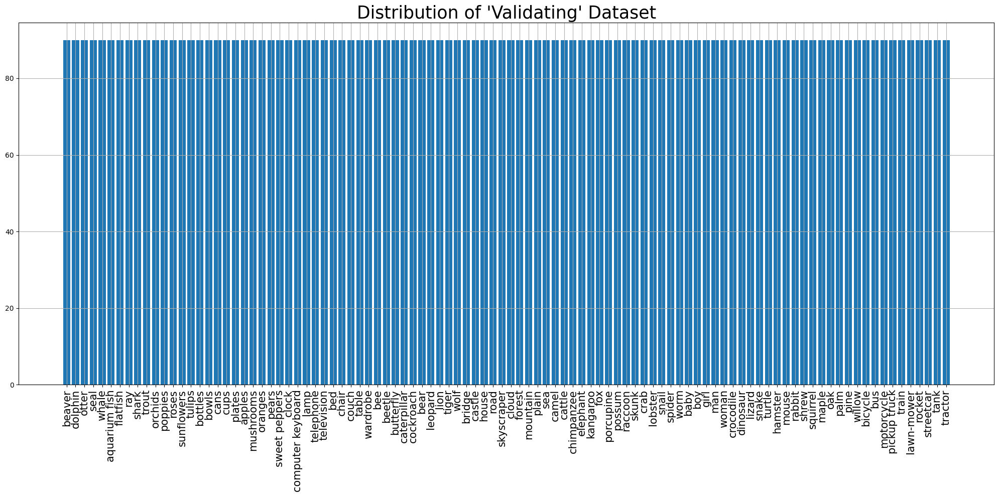

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


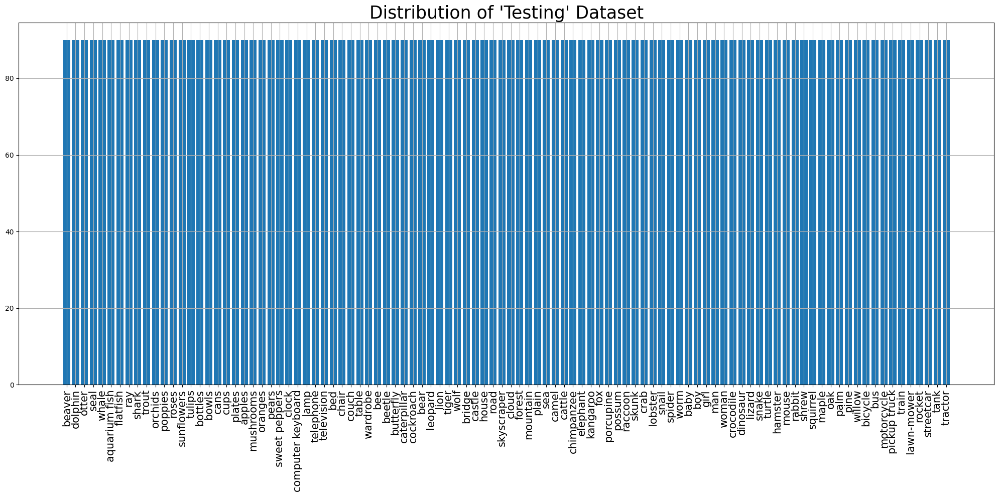

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 43s 47ms/step - accuracy: 0.3855 - f1_score: 0.3811 - loss: 2.5309 - precision: 0.7076 - val_accuracy: 0.5978 - val_f1_score: 0.5934 - val_loss: 1.4480 - val_precision: 0.7978
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5971 - f1_score: 0.5938 - loss: 1.4372 - precision: 0.7780 - val_accuracy: 0.6207 - val_f1_score: 0.6187 - val_loss: 1.3501 - val_precision: 0.7972
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6418 - f1_score: 0.6388 - loss: 1.2404 - precision: 0.7998 - val_accuracy: 0.6288 - val_f1_score: 0.6254 - val_loss: 1.3232 - val_precision: 0.7845
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6776 - f1_score: 0.6754 - loss: 1.0909 - precision: 0.8157 - val_accuracy: 0.6294 - val_f1_score: 0.6278 - val_loss: 1.3305 - val_precision: 0.7806
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.7061 - f1_score: 0.7040 - loss: 0.9729 - precision: 0.8297 - val_acc

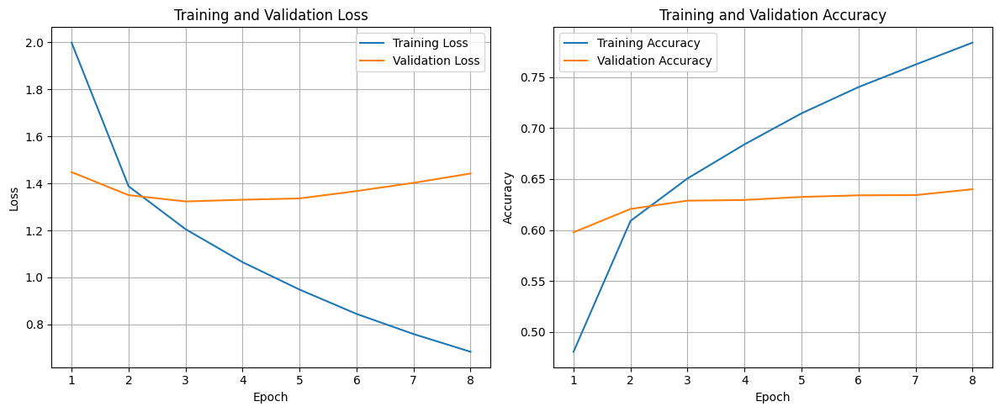

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6237 - f1_score: 0.6155 - loss: 1.3415 - precision: 0.7731
Test Accuracy: 63.34%
Test Loss: 131.22%
Test Precision: 78.97%
Test F1 Scores (Per Class): [81.60919  79.09604  55.865913 39.682537 39.75155  67.40331  56.363632
 61.751152 77.7202   81.01266  64.       40.789467 66.25     54.64481
 66.25767  56.43564  76.28865  65.04065  55.91397  51.960777 80.681816
 75.49018  77.98741  75.15151  74.84662  60.10362  49.275356 43.165462
 77.59562  68.208084 55.555546 63.387978 43.428566 58.883244 65.088745
 36.496346 67.05882  55.621304 52.760727 88.13559  71.590904 77.08333
 59.999996 70.11494  52.023117 50.340134 43.703697 61.38614  80.681816
 80.21389  44.82758  72.95596  61.39534  85.22727  70.23808  38.461533
 74.99999  70.93597  78.205124 49.624054 78.65168  72.625694 67.06587
 68.23529  40.2985   48.543686 62.14689  58.536583 84.37499  82.02247
 63.316578 73.33333  44.692734 55.555553 38.216557 77.89473  79.39698
 50.46729  67.857

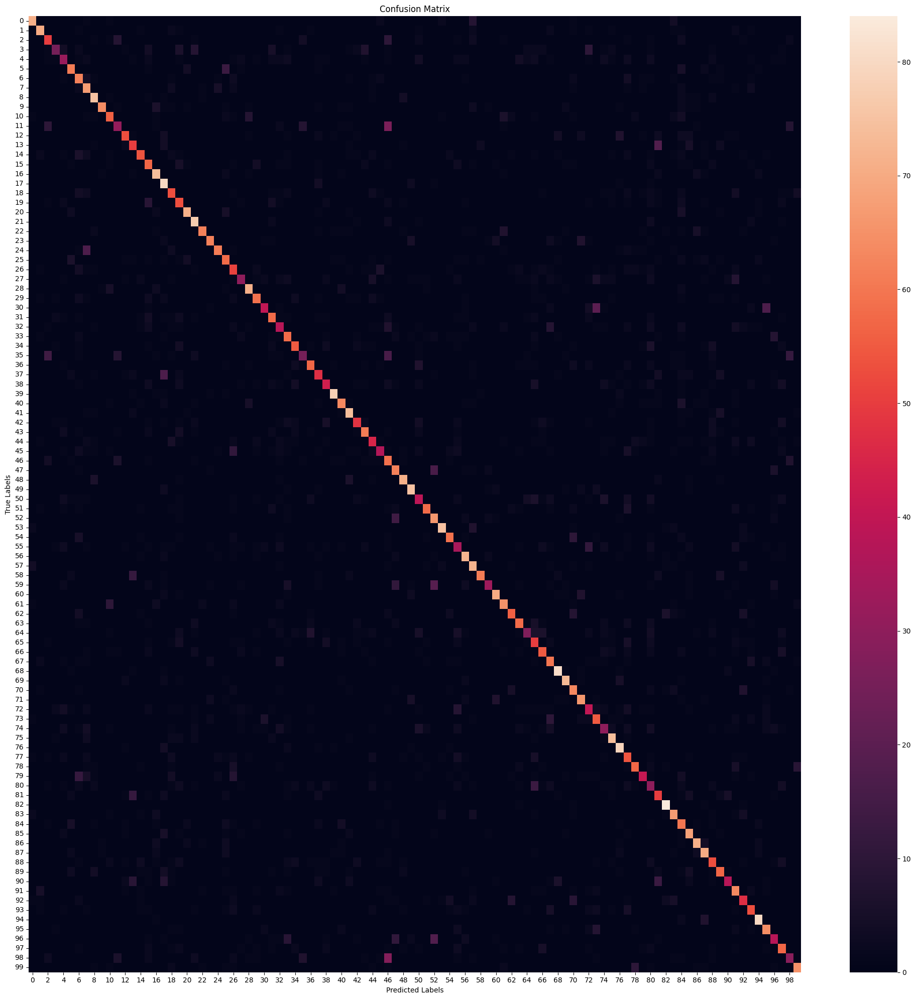

                   precision    recall  f1-score   support

           beaver       0.85      0.79      0.82        90
          dolphin       0.80      0.78      0.79        90
            otter       0.56      0.56      0.56        90
             seal       0.69      0.28      0.40        90
            whale       0.45      0.36      0.40        90
    aquarium fish       0.67      0.68      0.67        90
         flatfish       0.48      0.69      0.56        90
              ray       0.53      0.74      0.62        90
            shark       0.73      0.83      0.78        90
            trout       0.94      0.71      0.81        90
          orchids       0.66      0.62      0.64        90
          poppies       0.50      0.34      0.41        90
            roses       0.76      0.59      0.66        90
       sunflowers       0.54      0.56      0.55        90
           tulips       0.74      0.60      0.66        90
          bottles       0.51      0.63      0.56       

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 45s 47ms/step - accuracy: 0.6535 - f1_score: 0.6491 - loss: 1.2343 - precision: 0.8402 - val_accuracy: 0.6467 - val_f1_score: 0.6444 - val_loss: 1.2889 - val_precision: 0.7952
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7056 - f1_score: 0.7024 - loss: 1.0089 - precision: 0.8558 - val_accuracy: 0.6546 - val_f1_score: 0.6526 - val_loss: 1.2591 - val_precision: 0.7911
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7283 - f1_score: 0.7254 - loss: 0.9153 - precision: 0.8612 - val_accuracy: 0.6598 - val_f1_score: 0.6582 - val_loss: 1.2423 - val_precision: 0.7883
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7489 - f1_score: 0.7463 - loss: 0.8491 - precision: 0.8698 - val_accuracy: 0.6666 - val_f1_score: 0.6652 - val_loss: 1.2319 - val_precision: 0.7880
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7676 - f1_score: 0.7649 - loss: 0.7894 - precision: 0.8806 - val_acc

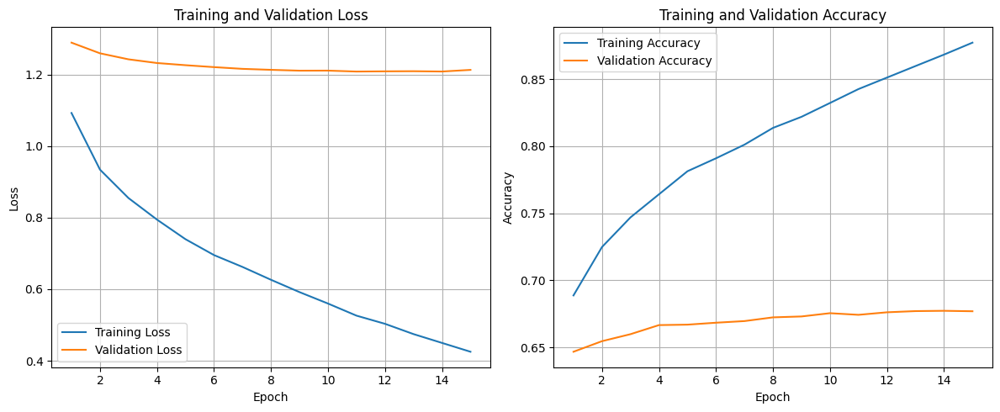

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6658 - f1_score: 0.6572 - loss: 1.2300 - precision: 0.7735
Test Accuracy: 67.36%
Test Loss: 120.45%
Test Precision: 78.13%
Test F1 Scores (Per Class): [86.666664 80.628265 54.736835 54.143642 44.06779  69.36415  65.32663
 69.61325  83.04093  82.558136 69.61325  45.71428  61.202175 60.227264
 70.11494  63.276833 77.77777  75.5102   55.555553 61.62162  85.10638
 79.12087  81.767944 76.300575 80.       69.005844 53.038673 42.391296
 74.725266 68.263466 64.28571  69.71428  53.48836  58.461536 68.74999
 39.75903  70.21276  60.21505  53.89221  89.534874 69.430046 83.060104
 67.06587  71.1111   47.999996 48.913036 52.325577 60.24096  84.7826
 81.767944 42.352932 72.83237  64.55026  90.217384 74.99999  37.869816
 82.02247  79.09604  79.99999  62.427734 77.9661   73.33333  63.687145
 71.428566 46.98795  60.96256  70.58823  63.387978 89.385475 81.675385
 65.92178  75.675674 39.534874 63.04347  39.999996 82.22221  85.86956
 58.682625 69.6629

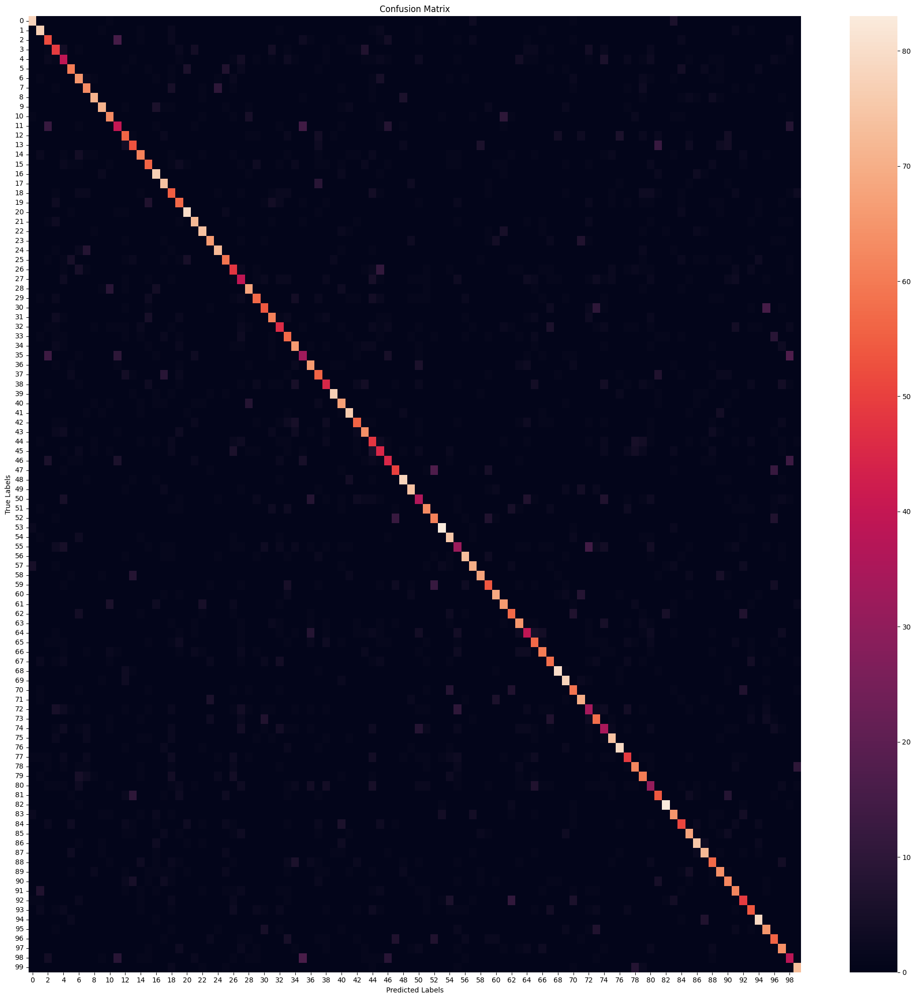

                   precision    recall  f1-score   support

           beaver       0.87      0.87      0.87        90
          dolphin       0.76      0.86      0.81        90
            otter       0.52      0.58      0.55        90
             seal       0.54      0.54      0.54        90
            whale       0.45      0.43      0.44        90
    aquarium fish       0.72      0.67      0.69        90
         flatfish       0.60      0.72      0.65        90
              ray       0.69      0.70      0.70        90
            shark       0.88      0.79      0.83        90
            trout       0.87      0.79      0.83        90
          orchids       0.69      0.70      0.70        90
          poppies       0.47      0.44      0.46        90
            roses       0.60      0.62      0.61        90
       sunflowers       0.62      0.59      0.60        90
           tulips       0.73      0.68      0.70        90
          bottles       0.64      0.62      0.63       

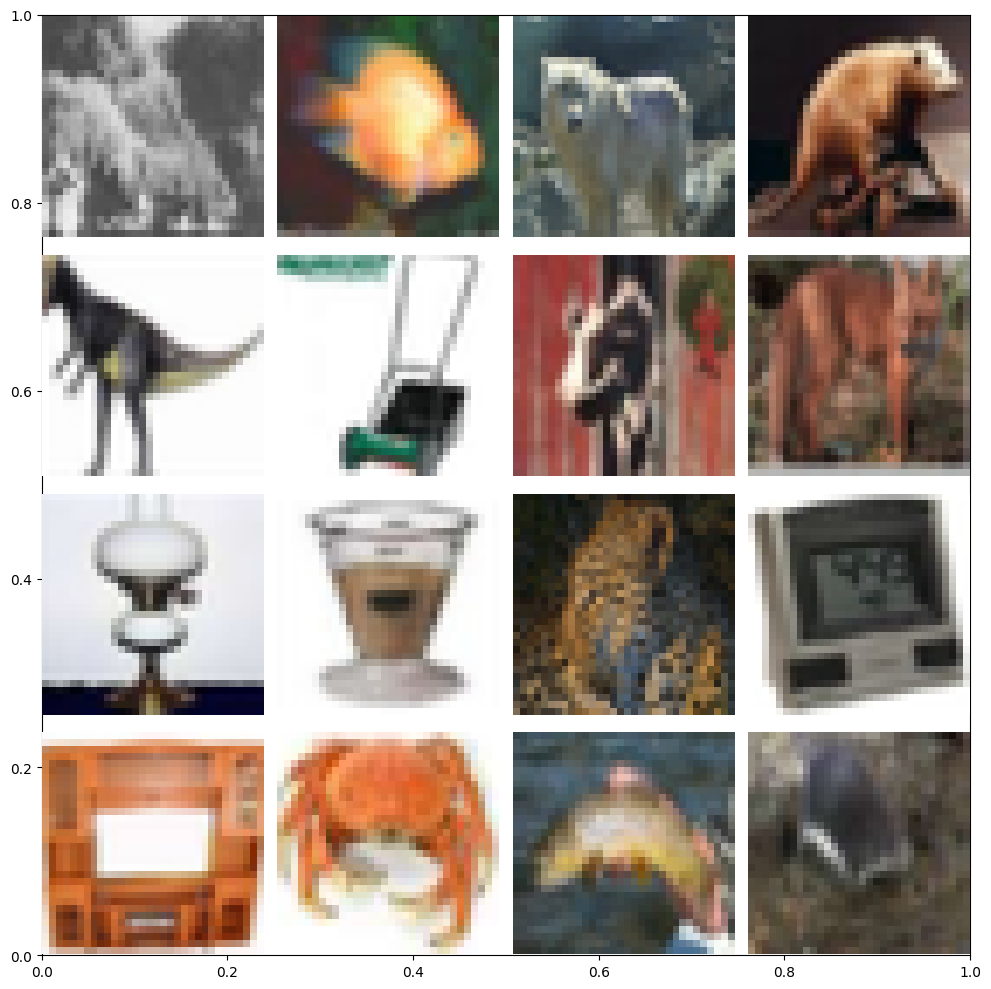

labels[20537].shape: (1,)
imgs[20537].shape: (32, 32, 3)


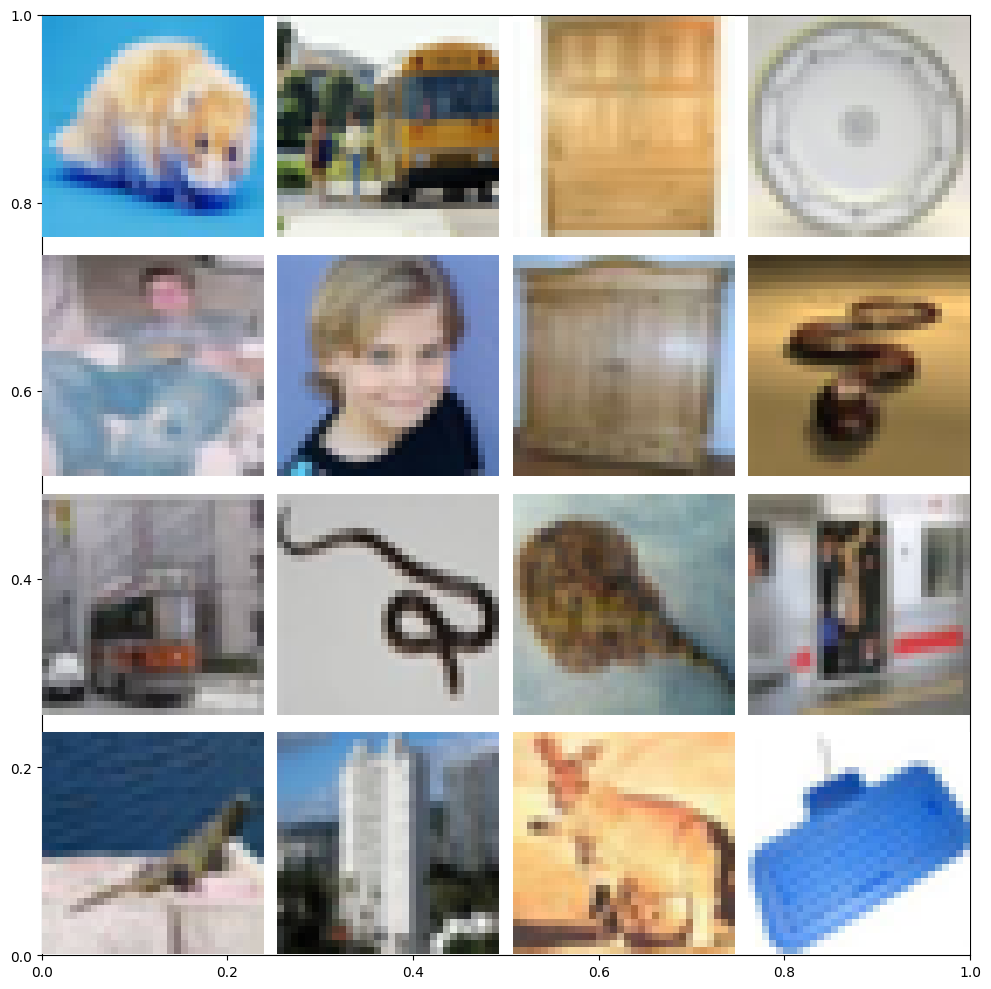

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


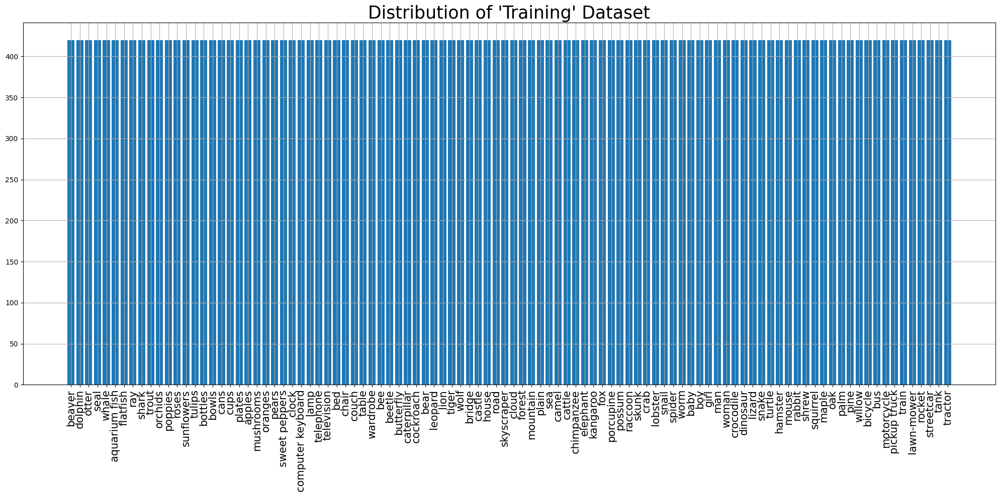

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


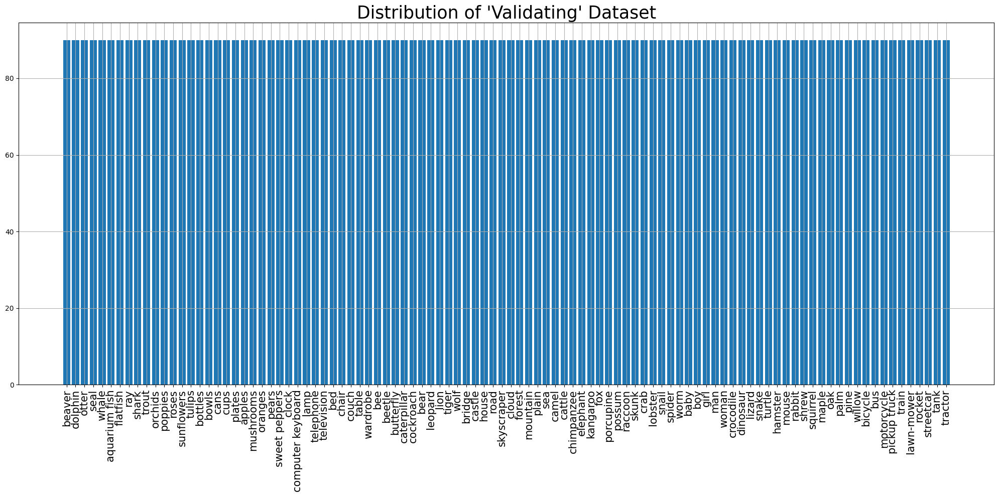

<ipython-input-10-1e20b652902c>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


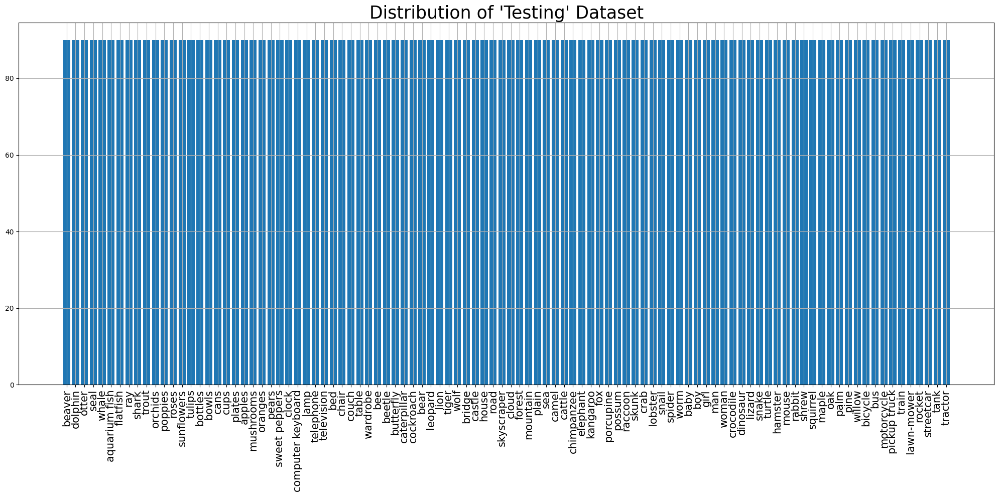

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_6           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 38s 43ms/step - accuracy: 0.3861 - f1_score: 0.3818 - loss: 2.5243 - precision: 0.7084 - val_accuracy: 0.5984 - val_f1_score: 0.5948 - val_loss: 1.4394 - val_precision: 0.7974
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5932 - f1_score: 0.5902 - loss: 1.4520 - precision: 0.7750 - val_accuracy: 0.6220 - val_f1_score: 0.6196 - val_loss: 1.3455 - val_precision: 0.7953
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.6422 - f1_score: 0.6397 - loss: 1.2367 - precision: 0.8008 - val_accuracy: 0.6279 - val_f1_score: 0.6243 - val_loss: 1.3414 - val_precision: 0.7771
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.6794 - f1_score: 0.6771 - loss: 1.0835 - precision: 0.8182 - val_accuracy: 0.6371 - val_f1_score: 0.6343 - val_loss: 1.3117 - val_precision: 0.7773
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.7108 - f1_score: 0.7083 - loss: 0.9607 - precision: 0.8328 - val_acc

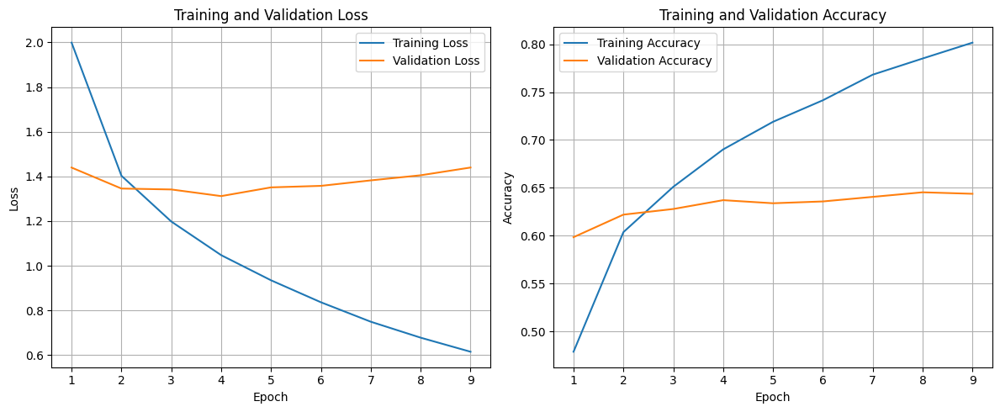

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.6282 - f1_score: 0.6182 - loss: 1.3484 - precision: 0.7718
Test Accuracy: 63.72%
Test Loss: 132.14%
Test Precision: 78.07%
Test F1 Scores (Per Class): [84.883705 80.66298  53.95348  40.579704 37.433147 69.76743  62.264145
 68.36735  81.35593  81.60919  65.11627  42.94478  64.197525 50.95541
 63.905323 64.28571  78.260864 75.5102   56.684486 59.685856 80.22598
 69.99999  74.68353  71.14094  77.300606 56.19047  48.21428  44.585983
 78.53403  61.363636 59.574467 71.91011  50.299393 54.128437 65.90909
 21.428568 66.66666  59.595955 52.499992 88.13559  64.51612  77.24867
 63.88889  68.78981  42.268036 49.72375  50.44247  51.948048 79.329605
 78.172585 43.037968 71.604935 61.69154  85.02993  72.51461  33.783783
 74.2268   71.77033  76.72956  51.351345 76.92307  73.33333  66.25767
 68.29269  45.07042  49.999992 55.14018  56.701027 86.45833  80.459755
 67.6923   70.35175  42.307686 63.21243  36.571426 80.87432  82.10526
 55.882347 63.6363

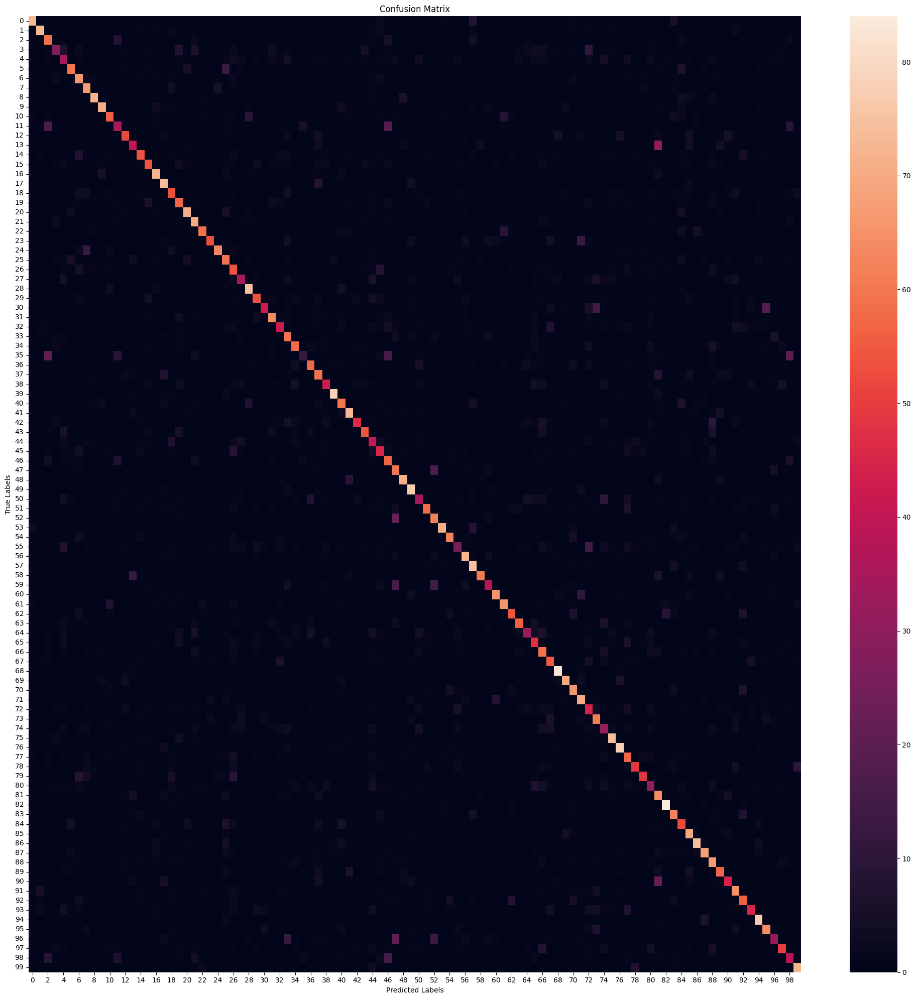

                   precision    recall  f1-score   support

           beaver       0.89      0.81      0.85        90
          dolphin       0.80      0.81      0.81        90
            otter       0.47      0.66      0.55        90
             seal       0.58      0.31      0.41        90
            whale       0.36      0.39      0.37        90
    aquarium fish       0.73      0.67      0.70        90
         flatfish       0.54      0.73      0.62        90
              ray       0.63      0.74      0.68        90
            shark       0.83      0.80      0.81        90
            trout       0.85      0.79      0.82        90
          orchids       0.68      0.62      0.65        90
          poppies       0.49      0.39      0.43        90
            roses       0.72      0.58      0.64        90
       sunflowers       0.60      0.44      0.51        90
           tulips       0.68      0.60      0.64        90
          bottles       0.69      0.60      0.64       

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_6           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 44s 47ms/step - accuracy: 0.6608 - f1_score: 0.6575 - loss: 1.1839 - precision: 0.8336 - val_accuracy: 0.6443 - val_f1_score: 0.6425 - val_loss: 1.2947 - val_precision: 0.7818
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7290 - f1_score: 0.7261 - loss: 0.9127 - precision: 0.8638 - val_accuracy: 0.6522 - val_f1_score: 0.6508 - val_loss: 1.2718 - val_precision: 0.7775
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7550 - f1_score: 0.7525 - loss: 0.8184 - precision: 0.8744 - val_accuracy: 0.6590 - val_f1_score: 0.6580 - val_loss: 1.2586 - val_precision: 0.7751
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7734 - f1_score: 0.7709 - loss: 0.7523 - precision: 0.8813 - val_accuracy: 0.6609 - val_f1_score: 0.6593 - val_loss: 1.2546 - val_precision: 0.7737
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7908 - f1_score: 0.7883 - loss: 0.7033 - precision: 0.8899 - val_acc

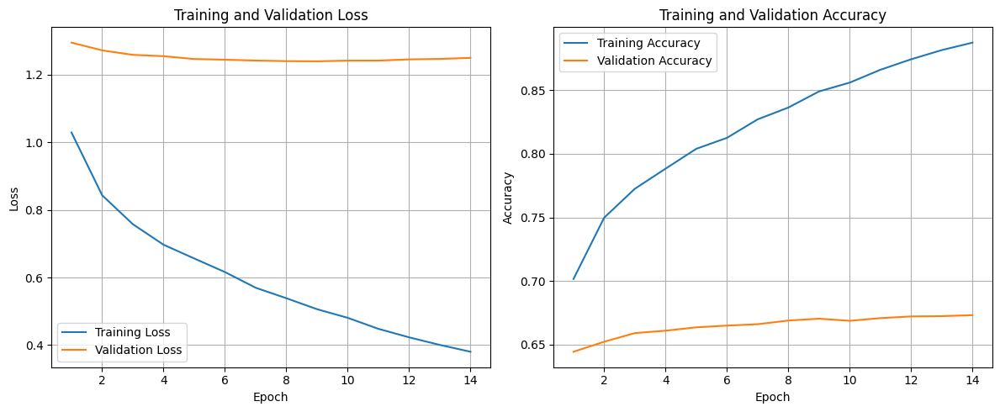

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6658 - f1_score: 0.6573 - loss: 1.2552 - precision: 0.7698
Test Accuracy: 67.19%
Test Loss: 124.10%
Test Precision: 77.53%
Test F1 Scores (Per Class): [84.32432  80.21389  55.83756  51.891888 41.081078 73.14285  70.526306
 64.86485  83.615814 82.95453  67.796616 43.478252 69.430046 63.636356
 65.03067  64.       81.28342  74.46808  57.60869  58.823524 82.97872
 75.138115 84.153    77.01149  80.21977  65.92178  54.748596 49.46236
 80.64516  67.796616 60.355026 70.329666 50.602406 61.702126 69.51871
 38.461533 73.33333  60.21505  54.02298  90.28571  69.51871  82.75862
 71.67629  70.05649  46.63212  47.61904  49.72375  55.999992 84.04254
 80.21977  42.10526  72.13114  63.492058 89.61748  72.53885  40.659336
 80.459755 73.863625 78.61271  58.100555 78.362564 75.58139  65.90909
 67.05202  53.333324 58.620686 63.101597 59.459454 89.65517  82.47422
 70.05649  73.40425  44.171776 62.76595  35.227264 83.14606  86.02149
 60.67415  68.208084

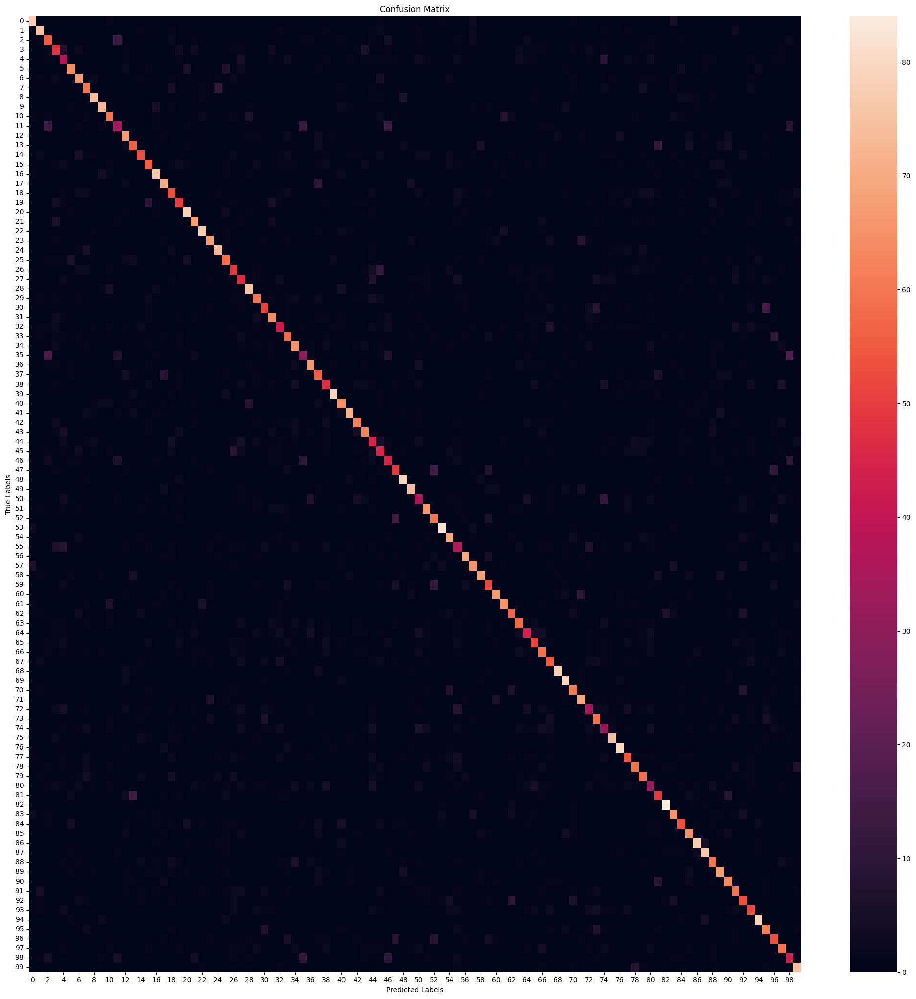

                   precision    recall  f1-score   support

           beaver       0.82      0.87      0.84        90
          dolphin       0.77      0.83      0.80        90
            otter       0.51      0.61      0.56        90
             seal       0.51      0.53      0.52        90
            whale       0.40      0.42      0.41        90
    aquarium fish       0.75      0.71      0.73        90
         flatfish       0.67      0.74      0.71        90
              ray       0.63      0.67      0.65        90
            shark       0.85      0.82      0.84        90
            trout       0.85      0.81      0.83        90
          orchids       0.69      0.67      0.68        90
          poppies       0.49      0.38      0.42        90
            roses       0.65      0.74      0.69        90
       sunflowers       0.65      0.62      0.64        90
           tulips       0.73      0.59      0.65        90
          bottles       0.66      0.62      0.64       

In [10]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (224, 224))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist

# Different mu

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[34180].shape: (1,)
imgs[34180].shape: (32, 32, 3)


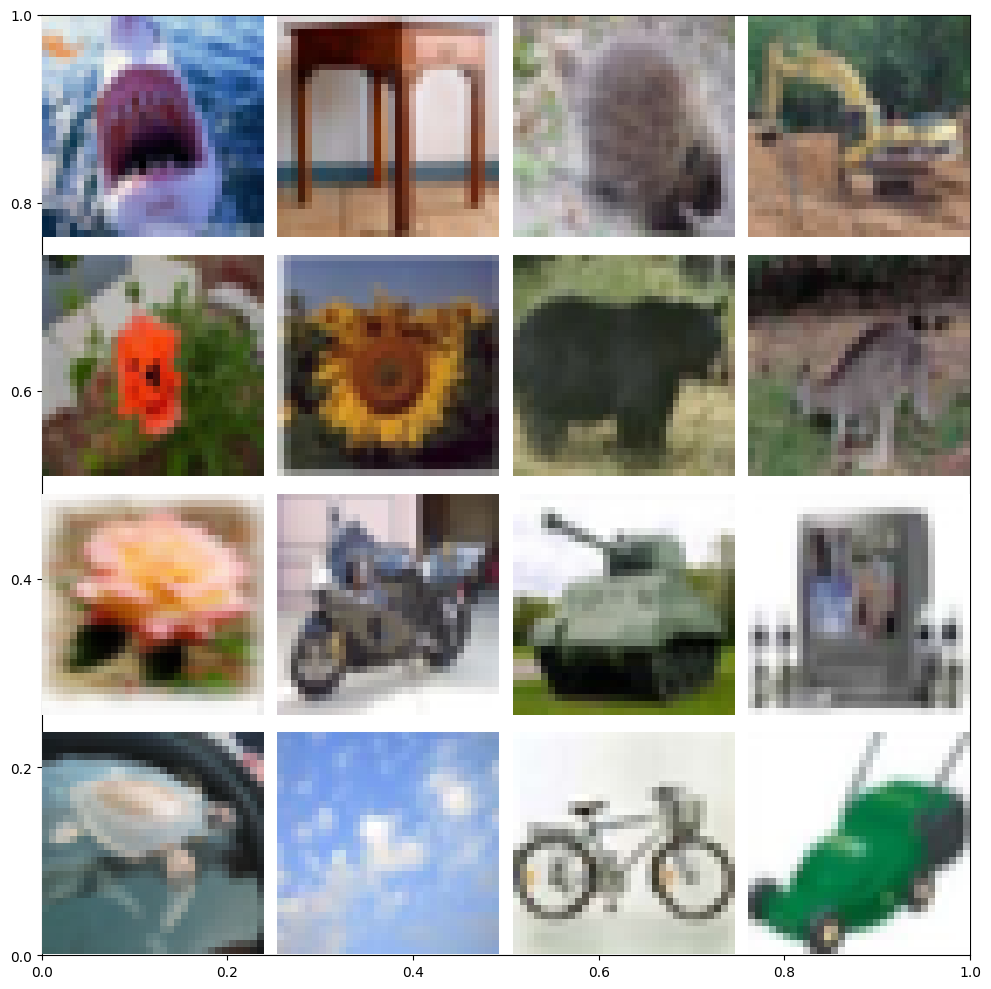

labels[17931].shape: (1,)
imgs[17931].shape: (32, 32, 3)


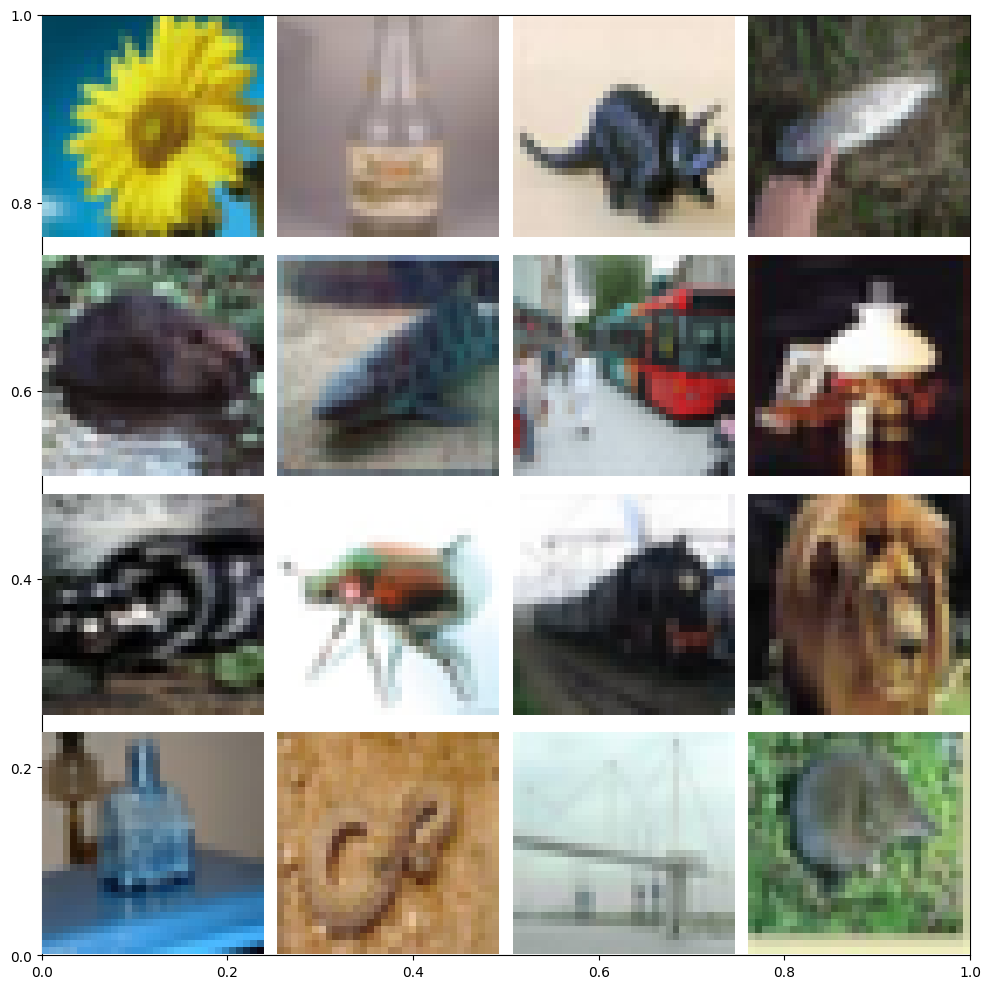

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


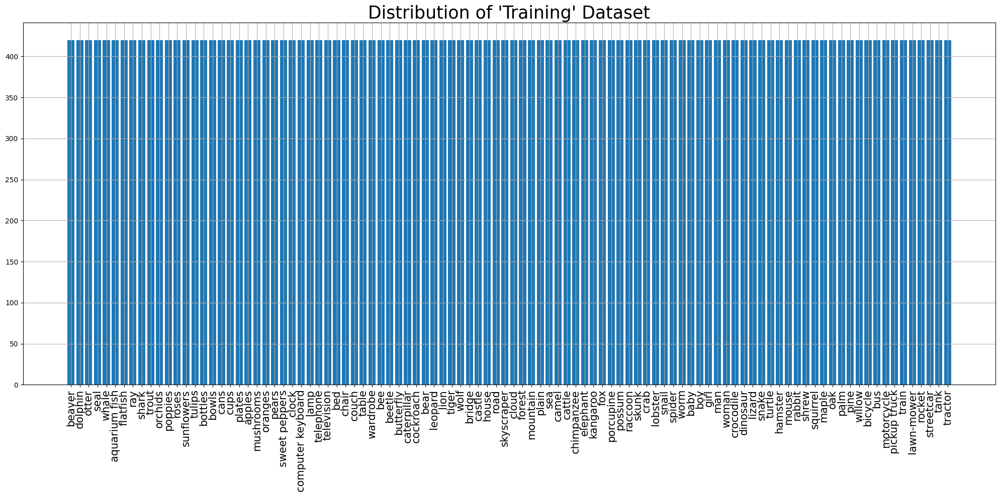

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


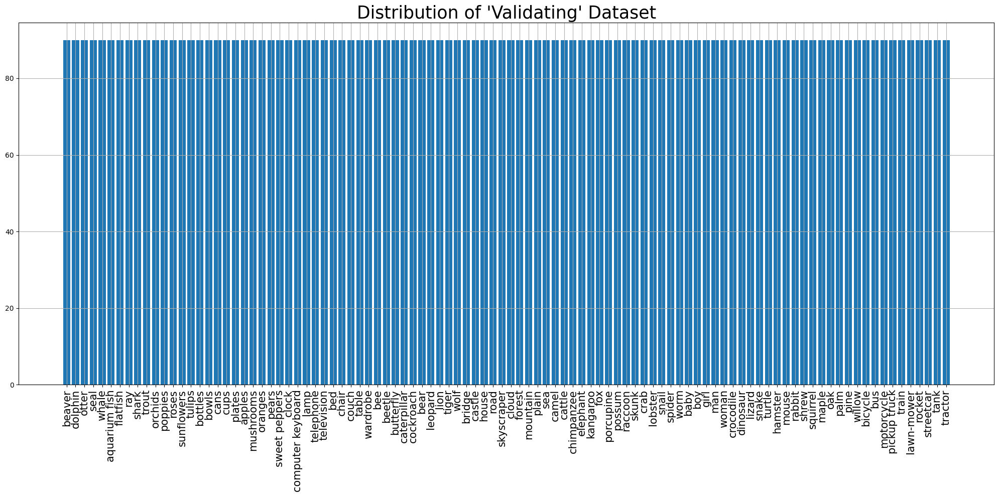

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


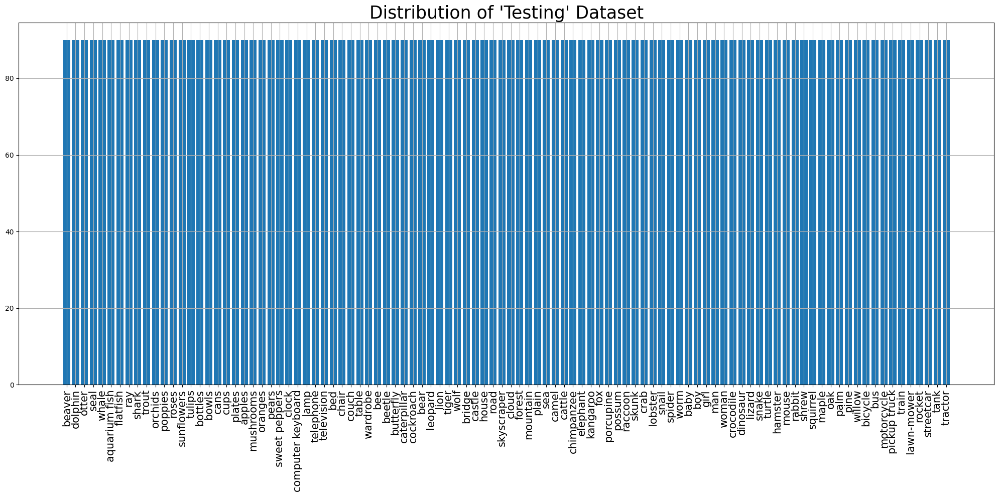

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_7           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 39s 44ms/step - accuracy: 0.3659 - f1_score: 0.3613 - loss: 2.5963 - precision: 0.6501 - val_accuracy: 0.5360 - val_f1_score: 0.5294 - val_loss: 1.6792 - val_precision: 0.7627
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5043 - f1_score: 0.5001 - loss: 1.8441 - precision: 0.7106 - val_accuracy: 0.5581 - val_f1_score: 0.5550 - val_loss: 1.6068 - val_precision: 0.7630
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5367 - f1_score: 0.5333 - loss: 1.6980 - precision: 0.7337 - val_accuracy: 0.5601 - val_f1_score: 0.5587 - val_loss: 1.6002 - val_precision: 0.7529
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5643 - f1_score: 0.5609 - loss: 1.5914 - precision: 0.7429 - val_accuracy: 0.5797 - val_f1_score: 0.5759 - val_loss: 1.6201 - val_precision: 0.7463
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5845 - f1_score: 0.5812 - loss: 1.5068 - precision: 0.7546 - val_acc

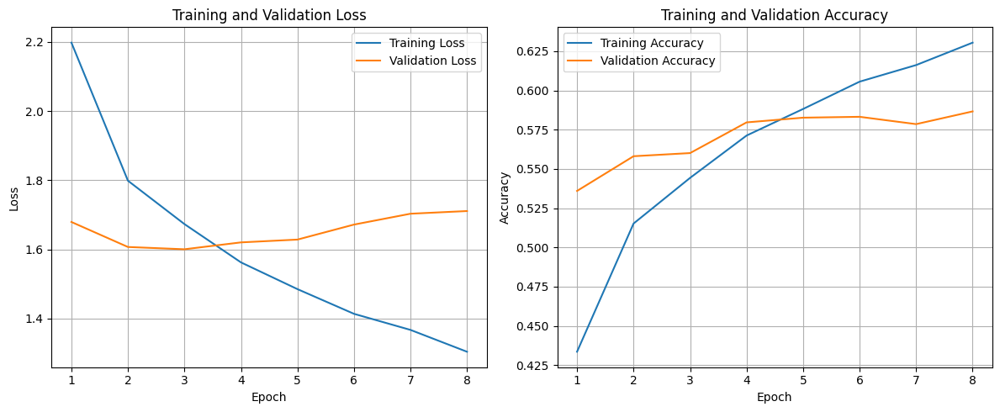

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5615 - f1_score: 0.5546 - loss: 1.6258 - precision: 0.7411
Test Accuracy: 57.48%
Test Loss: 158.60%
Test Precision: 76.07%
Test F1 Scores (Per Class): [75.49669  72.61146  47.31182  31.932768 26.573423 51.282047 49.773754
 64.646454 77.906975 84.70587  59.340656 42.307686 64.47368  49.80237
 64.77273  43.54838  75.53191  64.40677  52.849735 52.631577 75.40983
 64.       82.42424  68.04123  69.86301  54.298634 45.933006 28.799995
 77.19298  58.031082 38.167934 55.072456 47.727264 51.960777 52.1327
 19.999996 59.999996 50.574715 41.304344 87.57396  63.291134 71.65774
 49.624054 65.19337  43.478252 37.288128 48.305077 46.048103 78.918915
 77.89473  34.196888 59.036137 49.142857 81.08108  65.43209  26.213587
 70.83333  68.68686  56.249992 35.398224 68.86791  70.15707  60.227264
 54.32098  37.878784 41.66666  56.603767 42.66666  81.56424  84.61538
 63.366337 63.855415 24.86486  50.261772 28.205124 78.07486  79.347824
 52.38095  60.3351

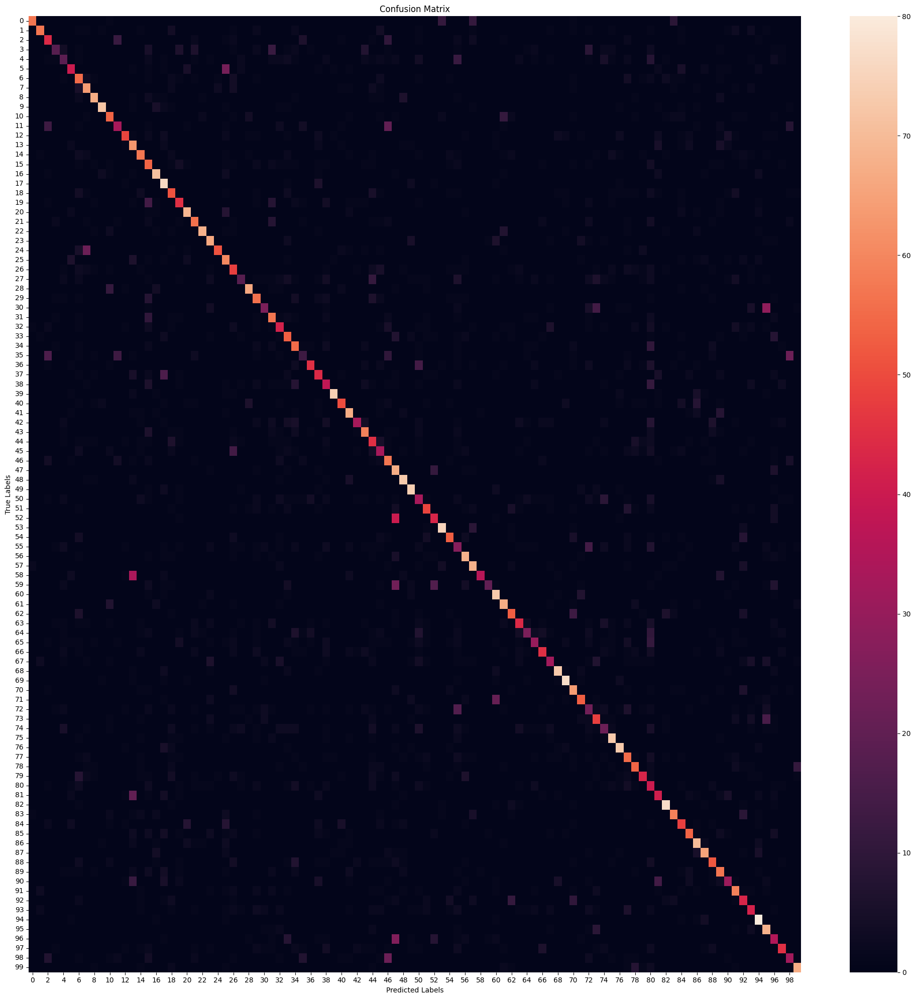

                   precision    recall  f1-score   support

           beaver       0.93      0.63      0.75        90
          dolphin       0.85      0.63      0.73        90
            otter       0.46      0.49      0.47        90
             seal       0.64      0.20      0.31        90
            whale       0.36      0.21      0.27        90
    aquarium fish       0.61      0.44      0.51        90
         flatfish       0.42      0.61      0.50        90
              ray       0.59      0.71      0.65        90
            shark       0.82      0.74      0.78        90
            trout       0.90      0.80      0.85        90
          orchids       0.59      0.60      0.59        90
          poppies       0.50      0.37      0.42        90
            roses       0.79      0.54      0.64        90
       sunflowers       0.39      0.70      0.50        90
           tulips       0.66      0.63      0.65        90
          bottles       0.34      0.60      0.44       

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_7           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.5412 - f1_score: 0.5366 - loss: 1.6985 - precision: 0.7681 - val_accuracy: 0.5984 - val_f1_score: 0.5975 - val_loss: 1.5156 - val_precision: 0.7665
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6087 - f1_score: 0.6049 - loss: 1.3849 - precision: 0.8007 - val_accuracy: 0.6107 - val_f1_score: 0.6088 - val_loss: 1.4701 - val_precision: 0.7705
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6259 - f1_score: 0.6227 - loss: 1.2875 - precision: 0.8112 - val_accuracy: 0.6153 - val_f1_score: 0.6137 - val_loss: 1.4447 - val_precision: 0.7715
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6450 - f1_score: 0.6421 - loss: 1.2075 - precision: 0.8204 - val_accuracy: 0.6217 - val_f1_score: 0.6199 - val_loss: 1.4251 - val_precision: 0.7721
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.6674 - f1_score: 0.6642 - loss: 1.1339 - precision: 0.8315 - val_acc

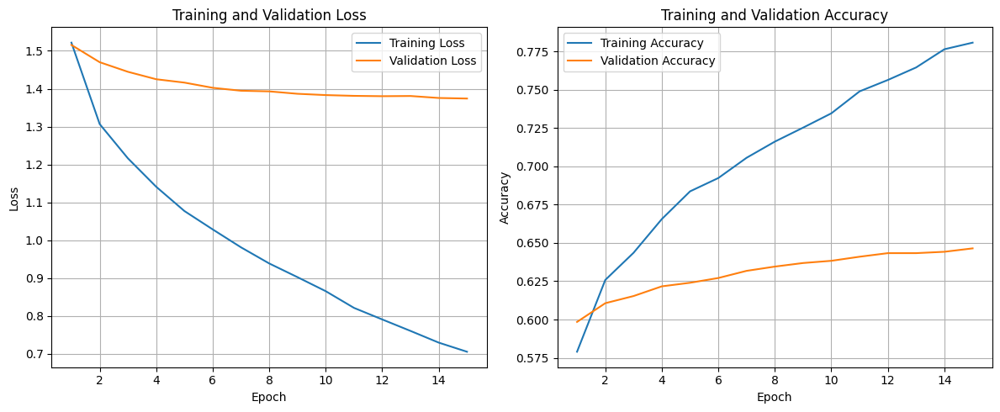

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6369 - f1_score: 0.6309 - loss: 1.4024 - precision: 0.7598
Test Accuracy: 64.79%
Test Loss: 137.36%
Test Precision: 76.80%
Test F1 Scores (Per Class): [86.36363  79.78141  53.475933 47.727264 33.513508 61.445778 60.396034
 68.449196 82.558136 81.31868  67.40331  47.499996 61.956512 61.363636
 63.5838   59.7826   80.87432  77.89473  57.731956 60.33519  78.49462
 75.675674 81.96721  78.16091  81.11111  62.222218 48.42105  41.450768
 76.13636  65.24063  60.714275 66.26506  53.416145 57.843132 63.157898
 31.213865 67.02127  58.064507 53.48836  89.94083  66.31578  80.446915
 65.53671  68.888885 48.044685 46.48648  53.93258  54.64481  83.69564
 79.787224 38.37209  71.590904 64.2487   89.14285  68.39378  33.33333
 77.01149  73.863625 78.57143  53.08641  79.28994  73.0337   65.55555
 65.14285  45.508976 49.42528  63.73626  55.319138 87.56756  80.628265
 67.83625  73.79678  35.35911  60.869556 32.183903 82.22221  86.81318
 59.428566 64.406

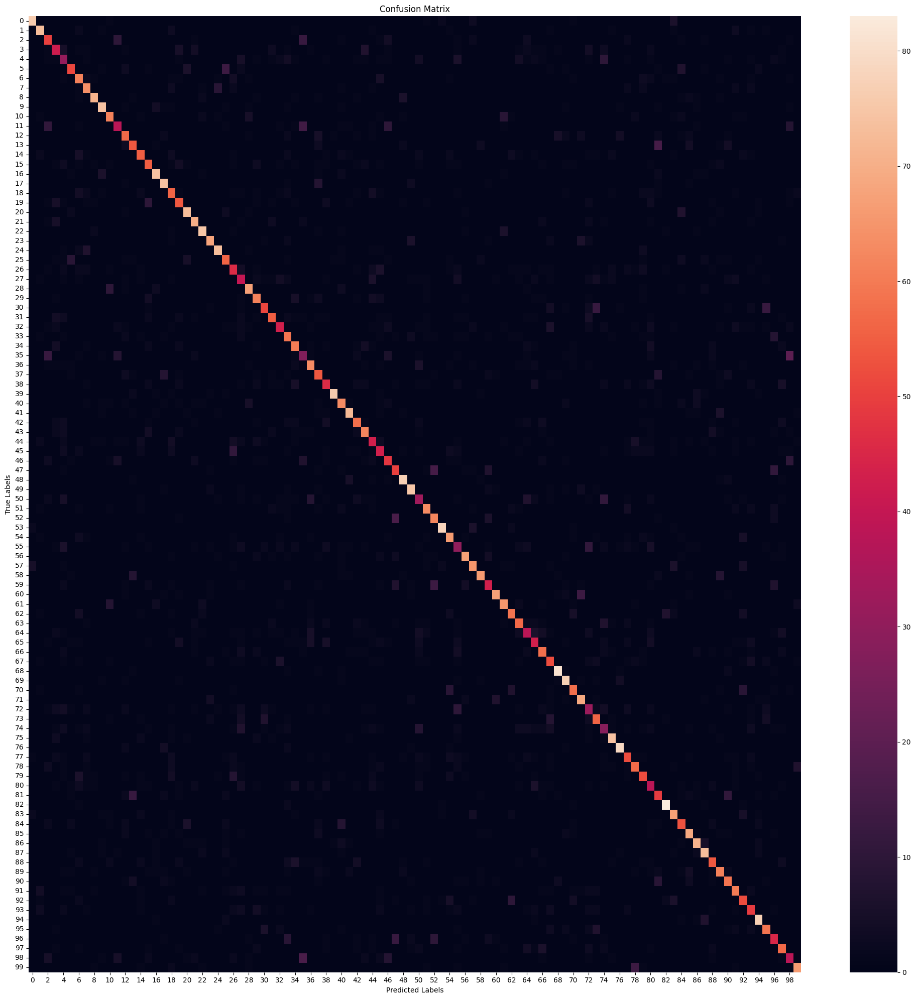

                   precision    recall  f1-score   support

           beaver       0.88      0.84      0.86        90
          dolphin       0.78      0.81      0.80        90
            otter       0.52      0.56      0.53        90
             seal       0.49      0.47      0.48        90
            whale       0.33      0.34      0.34        90
    aquarium fish       0.67      0.57      0.61        90
         flatfish       0.54      0.68      0.60        90
              ray       0.66      0.71      0.68        90
            shark       0.87      0.79      0.83        90
            trout       0.80      0.82      0.81        90
          orchids       0.67      0.68      0.67        90
          poppies       0.54      0.42      0.47        90
            roses       0.61      0.63      0.62        90
       sunflowers       0.63      0.60      0.61        90
           tulips       0.66      0.61      0.64        90
          bottles       0.59      0.61      0.60       

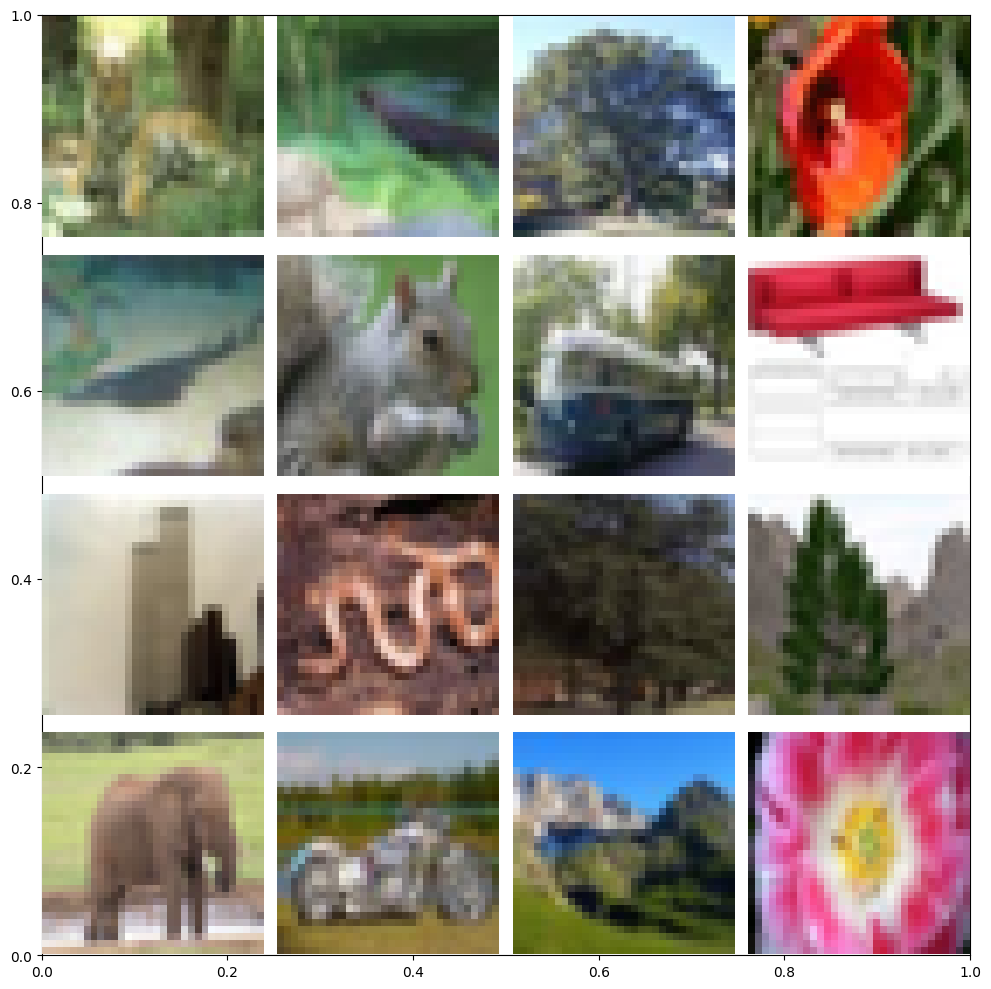

labels[41635].shape: (1,)
imgs[41635].shape: (32, 32, 3)


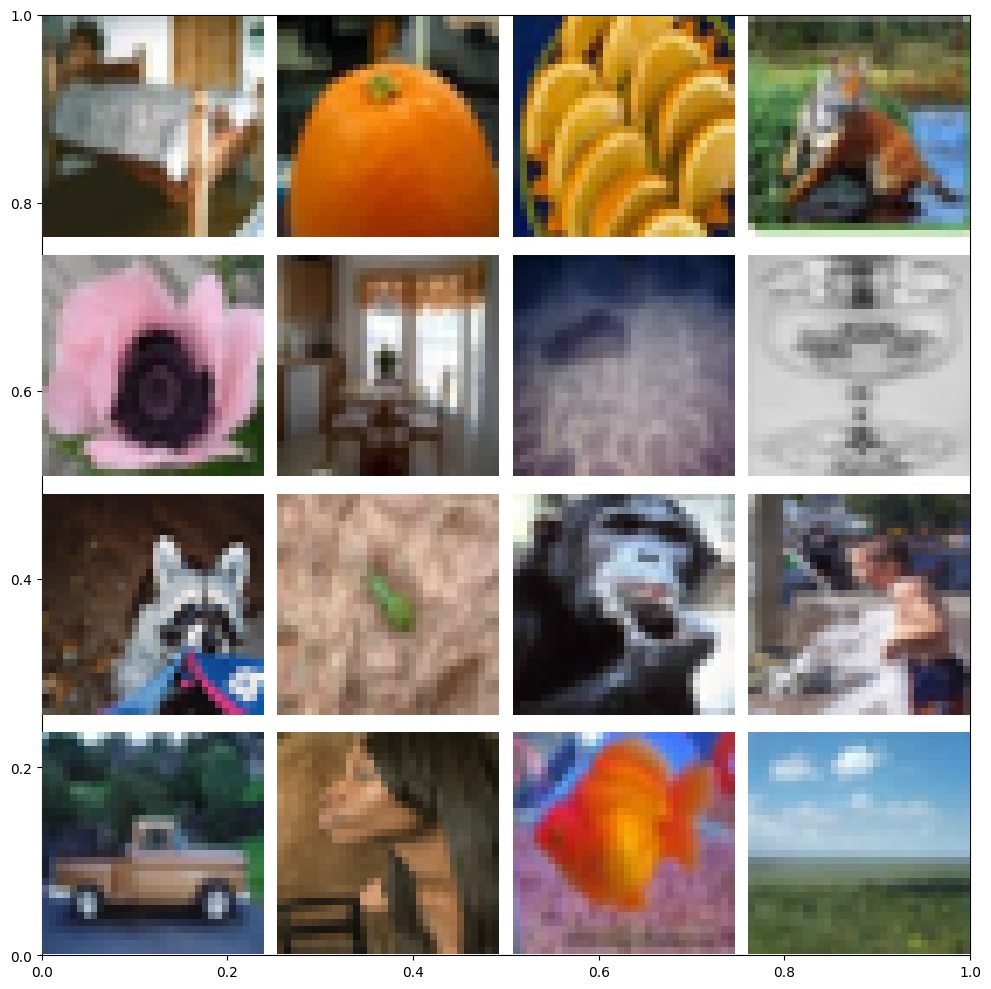

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


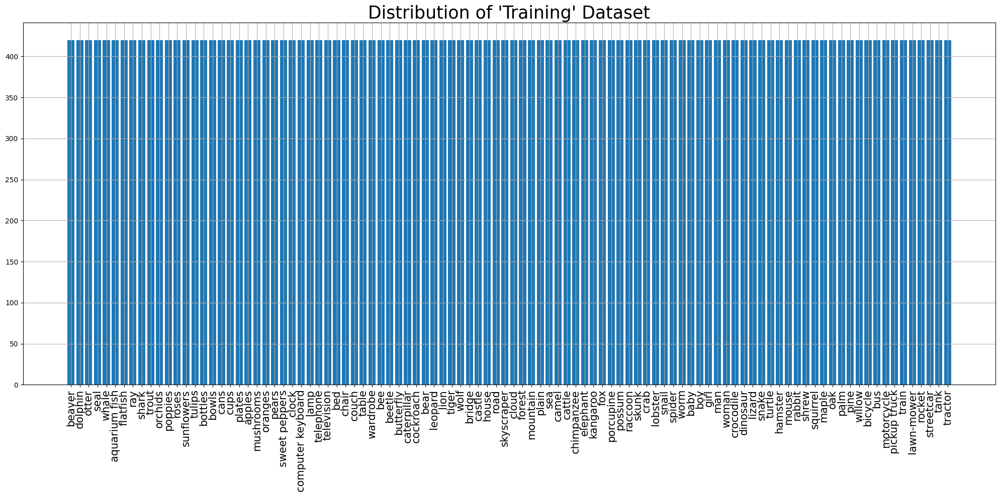

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


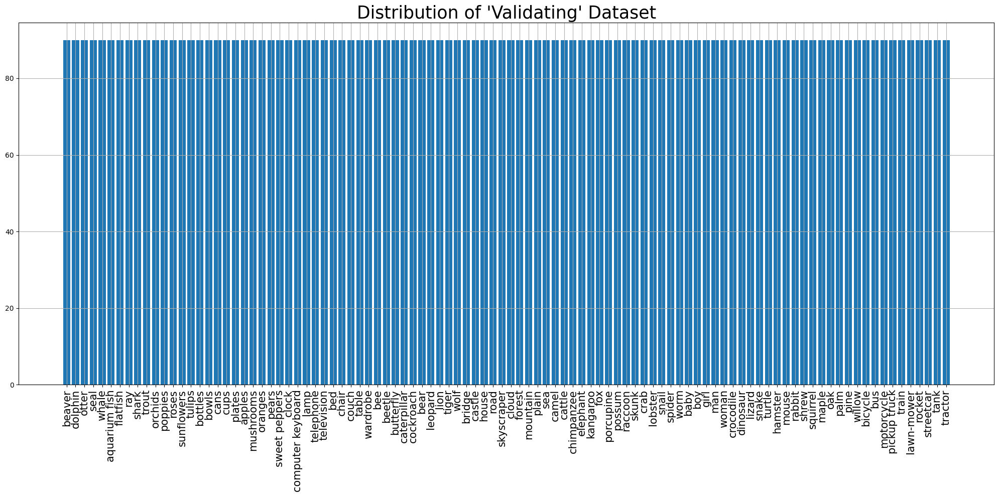

<ipython-input-11-6923e65f817a>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


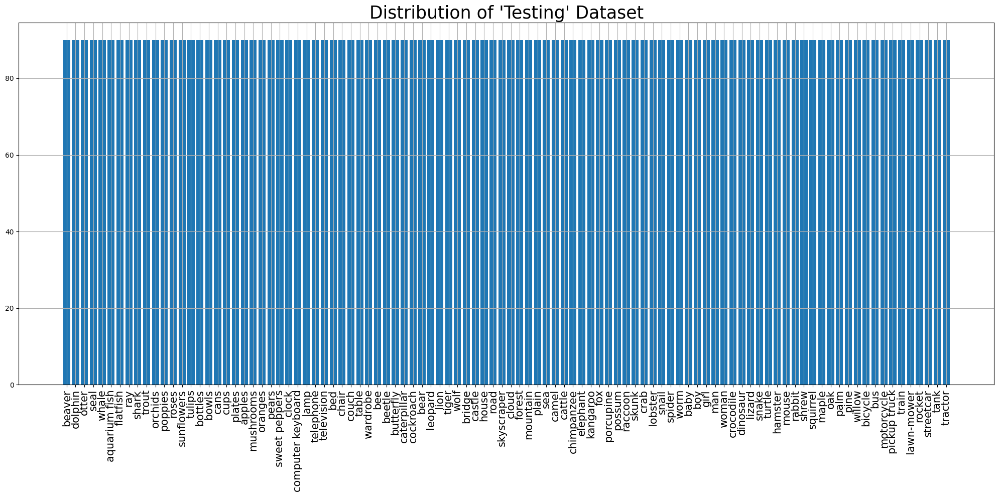

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_8           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 40s 43ms/step - accuracy: 0.3658 - f1_score: 0.3603 - loss: 2.6026 - precision: 0.6574 - val_accuracy: 0.5516 - val_f1_score: 0.5471 - val_loss: 1.6233 - val_precision: 0.7724
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5062 - f1_score: 0.5018 - loss: 1.8390 - precision: 0.7177 - val_accuracy: 0.5666 - val_f1_score: 0.5638 - val_loss: 1.5981 - val_precision: 0.7693
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5374 - f1_score: 0.5335 - loss: 1.6996 - precision: 0.7344 - val_accuracy: 0.5744 - val_f1_score: 0.5692 - val_loss: 1.5854 - val_precision: 0.7604
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5631 - f1_score: 0.5600 - loss: 1.5841 - precision: 0.7448 - val_accuracy: 0.5732 - val_f1_score: 0.5682 - val_loss: 1.6269 - val_precision: 0.7503
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.5843 - f1_score: 0.5816 - loss: 1.5010 - precision: 0.7565 - val_acc

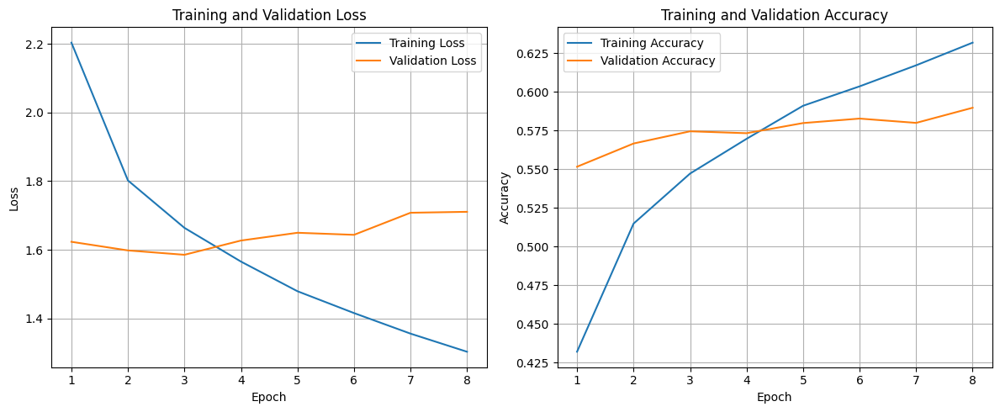

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5715 - f1_score: 0.5628 - loss: 1.6236 - precision: 0.7544
Test Accuracy: 57.64%
Test Loss: 158.61%
Test Precision: 76.18%
Test F1 Scores (Per Class): [76.82927  69.607834 47.45762  36.641216 25.599995 62.962955 50.7317
 54.468082 76.190475 78.61271  58.285706 43.157887 63.492058 46.98795
 59.016384 52.972965 73.5294   68.10344  55.855846 48.351646 77.71428
 68.74999  78.85714  75.641014 66.666664 54.310333 47.39336  31.249996
 74.725266 58.479523 39.34426  64.24241  36.66666  48.120293 53.535347
  9.999997 58.385086 46.242767 47.82608  86.22754  61.33333  74.8538
 49.275356 65.93406  43.617016 32.87671  43.478256 46.923073 74.14634
 75.89743  31.515144 63.803684 51.764698 82.7957   62.499992 22.784807
 69.791664 63.681583 74.117645 49.624054 74.69879  69.69697  58.653843
 56.73758  38.518517 43.749992 54.421764 51.256275 80.459755 77.77777
 53.88601  71.03825  31.050222 55.319138 27.499994 71.56862  81.56424
 43.749996 61.25     

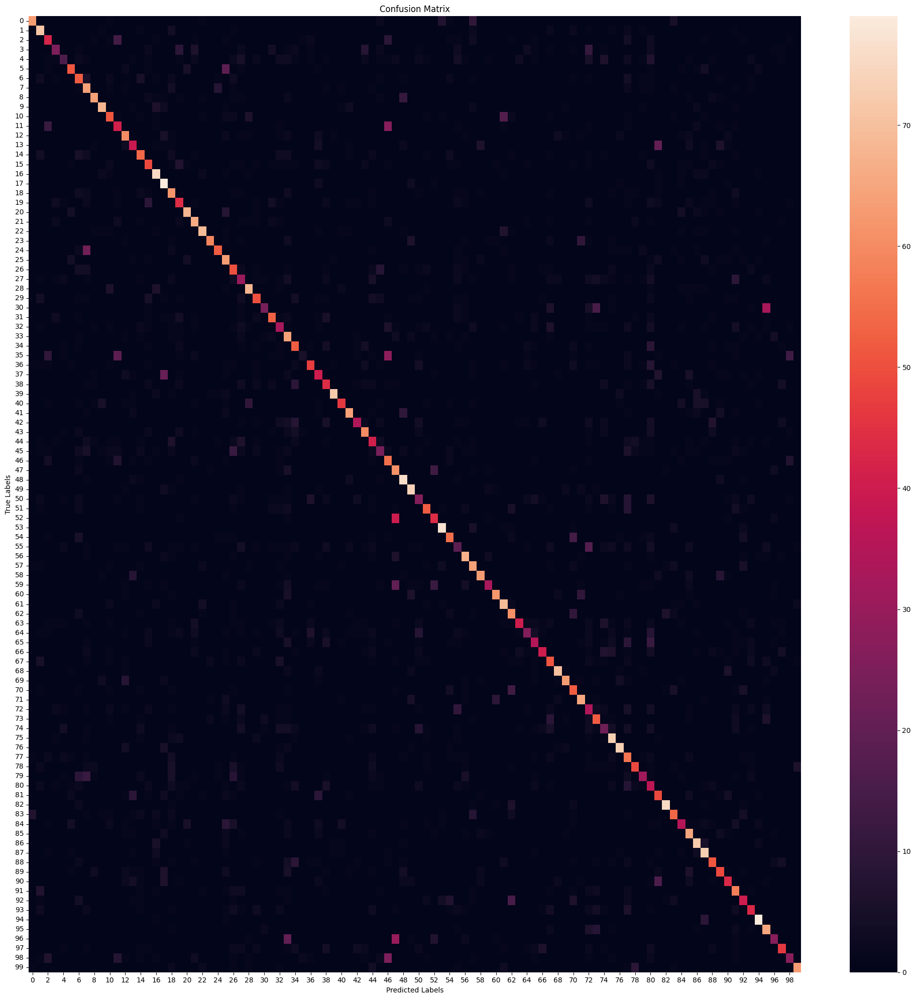

                   precision    recall  f1-score   support

           beaver       0.85      0.70      0.77        90
          dolphin       0.62      0.79      0.70        90
            otter       0.48      0.47      0.47        90
             seal       0.60      0.28      0.38        90
            whale       0.46      0.18      0.26        90
    aquarium fish       0.71      0.57      0.63        90
         flatfish       0.45      0.58      0.51        90
              ray       0.44      0.71      0.54        90
            shark       0.82      0.71      0.76        90
            trout       0.82      0.76      0.79        90
          orchids       0.60      0.57      0.58        90
          poppies       0.41      0.46      0.43        90
            roses       0.60      0.67      0.63        90
       sunflowers       0.51      0.43      0.47        90
           tulips       0.58      0.60      0.59        90
          bottles       0.52      0.54      0.53       

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_8           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.5310 - f1_score: 0.5285 - loss: 1.7507 - precision: 0.7598 - val_accuracy: 0.5991 - val_f1_score: 0.5979 - val_loss: 1.5055 - val_precision: 0.7728
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.6023 - f1_score: 0.5991 - loss: 1.4052 - precision: 0.8008 - val_accuracy: 0.6131 - val_f1_score: 0.6116 - val_loss: 1.4535 - val_precision: 0.7704
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.6315 - f1_score: 0.6284 - loss: 1.2833 - precision: 0.8138 - val_accuracy: 0.6191 - val_f1_score: 0.6171 - val_loss: 1.4270 - val_precision: 0.7724
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.6511 - f1_score: 0.6480 - loss: 1.2113 - precision: 0.8237 - val_accuracy: 0.6223 - val_f1_score: 0.6207 - val_loss: 1.4071 - val_precision: 0.7745
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.6669 - f1_score: 0.6638 - loss: 1.1342 - precision: 0.8320 - val_acc

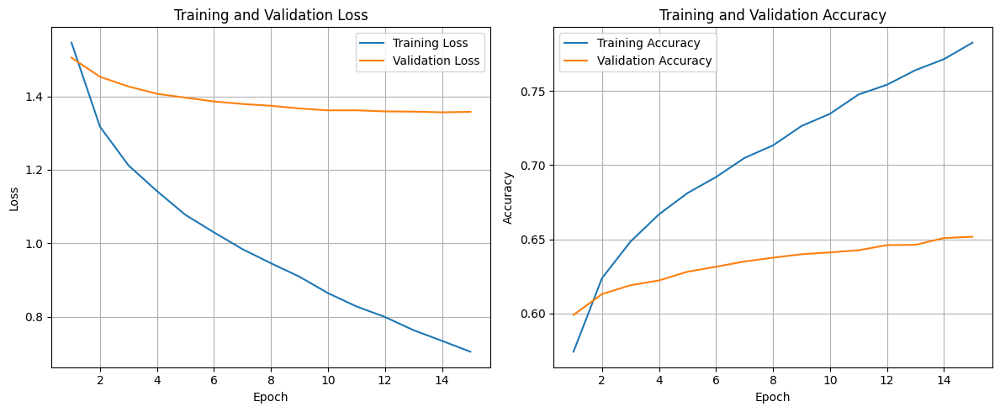

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6373 - f1_score: 0.6296 - loss: 1.4006 - precision: 0.7639
Test Accuracy: 64.71%
Test Loss: 135.62%
Test Precision: 77.27%
Test F1 Scores (Per Class): [82.872925 77.173904 54.736835 48.863632 32.608692 63.529408 62.311554
 65.94594  82.20858  83.14606  65.92178  50.29239  71.345024 57.92349
 61.87845  60.773476 78.723404 75.64766  60.63829  59.64912  82.47422
 76.190475 80.43478  80.459755 78.49462  63.218384 54.143642 39.999996
 79.329605 66.666664 61.176468 68.263466 45.962727 55.60975  66.29834
 36.781605 67.0391   58.510624 57.471264 87.71929  68.39378  79.329605
 64.13043  73.0337   49.18032  42.937847 52.873566 57.627117 77.77777
 80.87432  44.943817 69.36415  64.2487   86.20689  71.35678  35.051544
 77.52808  70.329666 78.313255 55.49132  82.558136 74.57626  61.62162
 64.       40.816322 52.873566 65.16853  55.789463 85.55555  81.28342
 68.15642  76.08696  37.426895 58.285706 31.818176 80.21977  85.55555
 60.919537 65.14285

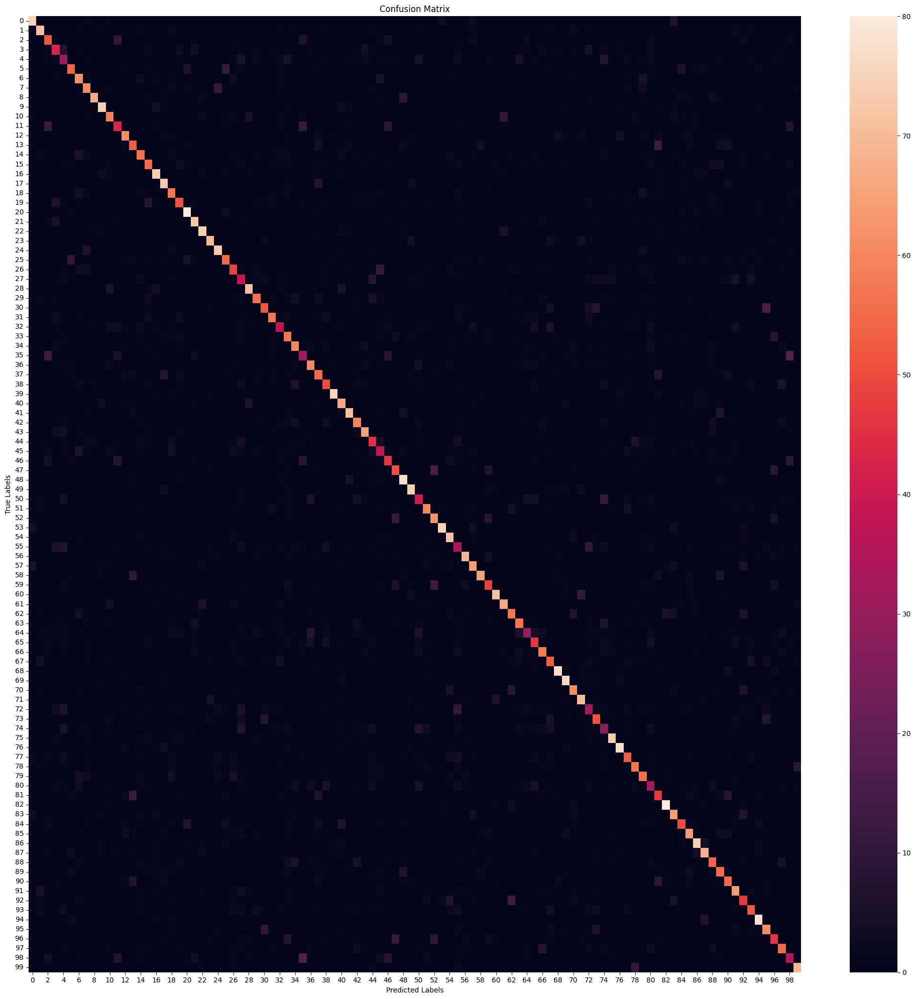

                   precision    recall  f1-score   support

           beaver       0.82      0.83      0.83        90
          dolphin       0.76      0.79      0.77        90
            otter       0.52      0.58      0.55        90
             seal       0.50      0.48      0.49        90
            whale       0.32      0.33      0.33        90
    aquarium fish       0.68      0.60      0.64        90
         flatfish       0.57      0.69      0.62        90
              ray       0.64      0.68      0.66        90
            shark       0.92      0.74      0.82        90
            trout       0.84      0.82      0.83        90
          orchids       0.66      0.66      0.66        90
          poppies       0.53      0.48      0.50        90
            roses       0.75      0.68      0.71        90
       sunflowers       0.57      0.59      0.58        90
           tulips       0.62      0.62      0.62        90
          bottles       0.60      0.61      0.60       

In [11]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=0.003),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (224, 224))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist

# Unfreeze all weights

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[30473].shape: (1,)
imgs[30473].shape: (32, 32, 3)


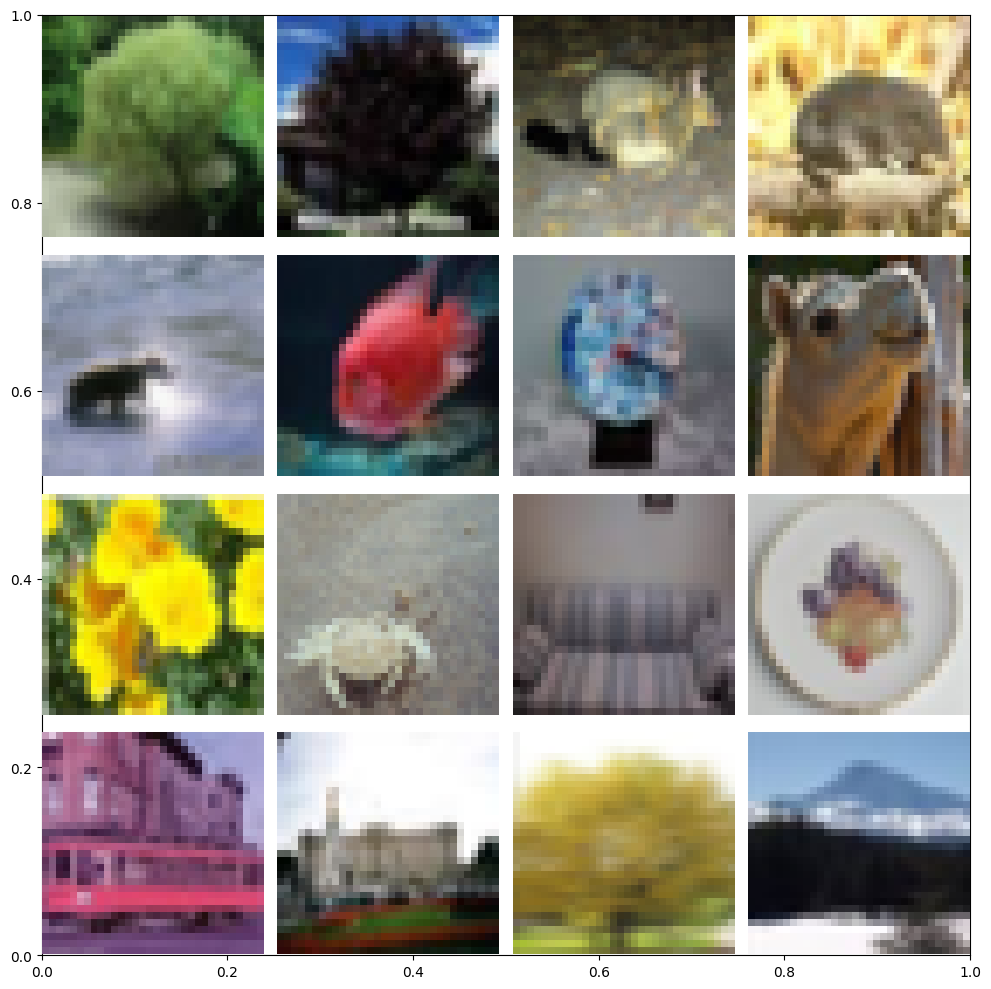

labels[40173].shape: (1,)
imgs[40173].shape: (32, 32, 3)


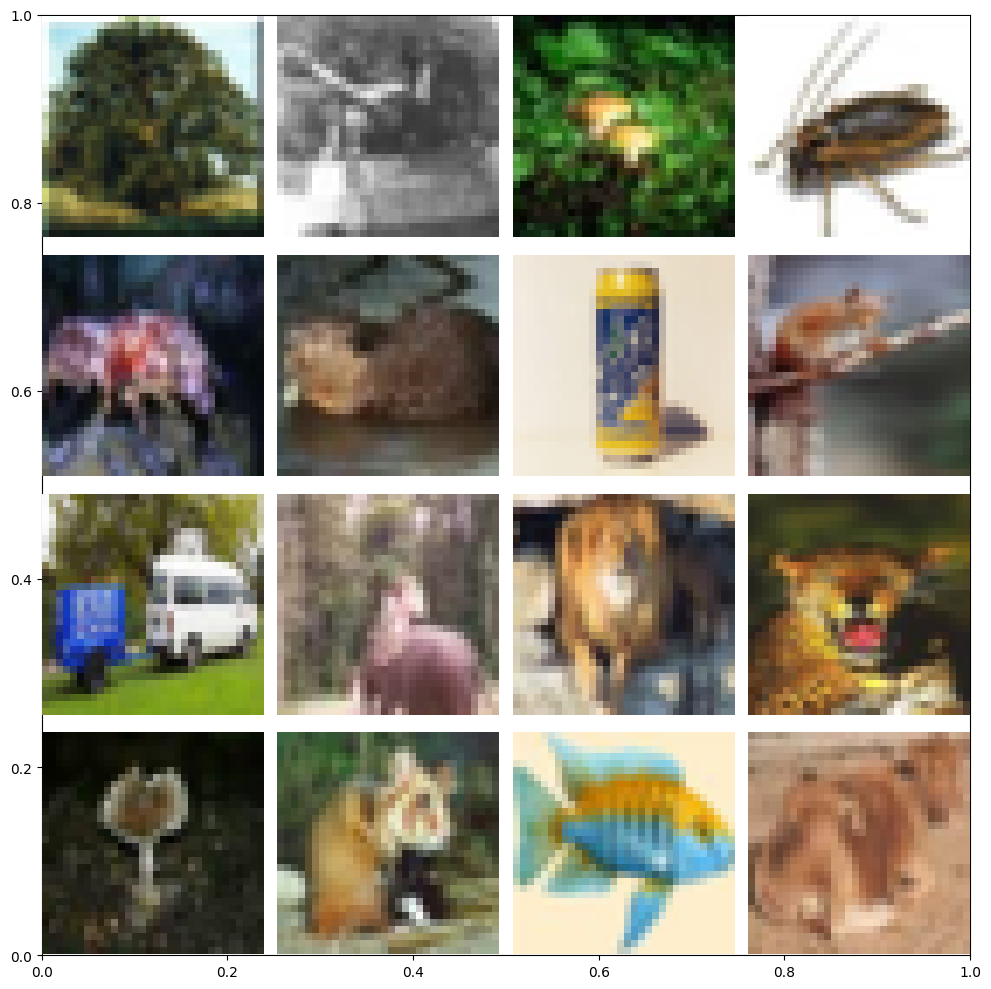

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


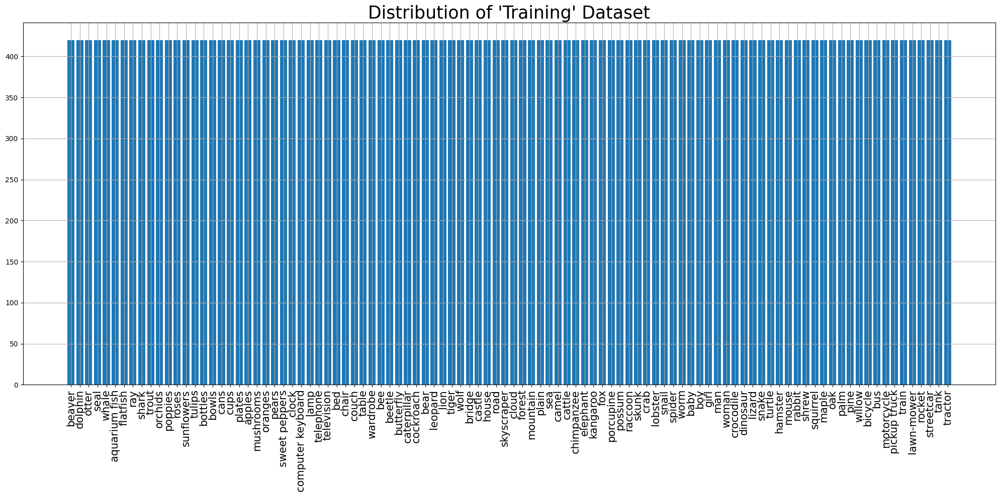

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


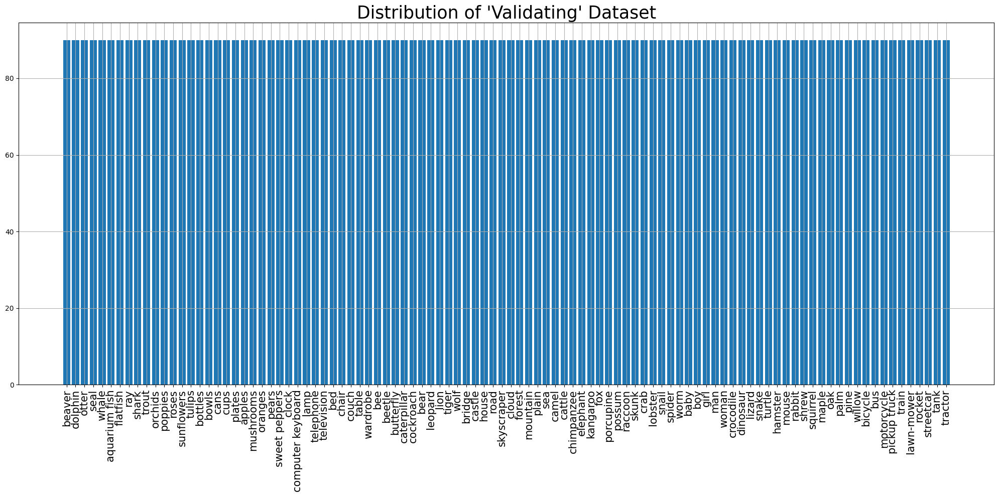

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


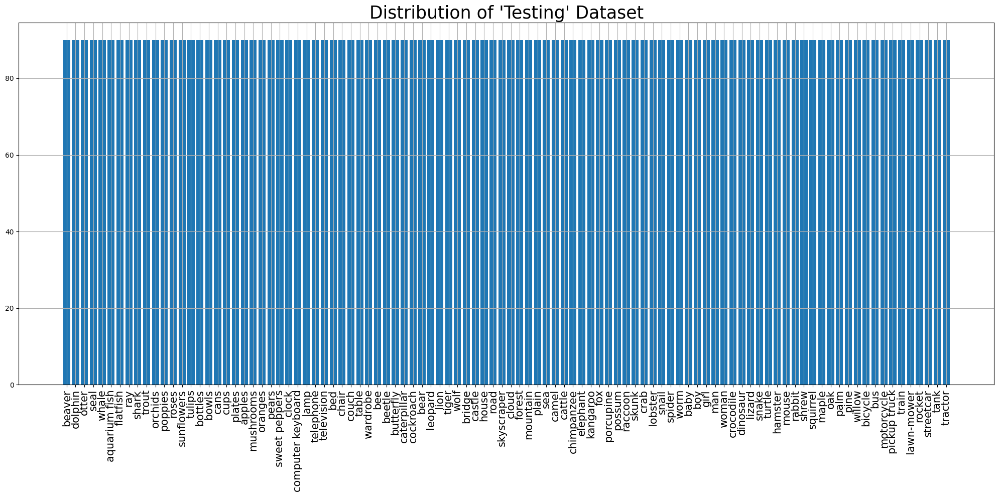

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_9           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 24,619,748 (93.92 MB)

 Non-trainable params: 45,440 (177.50 KB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 121s 108ms/step - accuracy: 0.0296 - f1_score: 0.0207 - loss: 4.4183 - precision: 0.1419 - val_accuracy: 0.0230 - val_f1_score: 0.0088 - val_loss: 12.2373 - val_precision: 0.0233
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.0661 - f1_score: 0.0503 - loss: 4.0206 - precision: 0.3085 - val_accuracy: 0.0619 - val_f1_score: 0.0344 - val_loss: 5.9474 - val_precision: 0.1446
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.0991 - f1_score: 0.0836 - loss: 3.8056 - precision: 0.3754 - val_accuracy: 0.0914 - val_f1_score: 0.0660 - val_loss: 4.2681 - val_precision: 0.2438
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.1328 - f1_score: 0.1174 - loss: 3.5888 - precision: 0.4953 - val_accuracy: 0.1112 - val_f1_score: 0.0801 - val_loss: 4.3979 - val_precision: 0.2569
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 69ms/step - accuracy: 0.1786 - f1_score: 0.1619 - loss: 3.3386 - precision: 0.5653 - val_

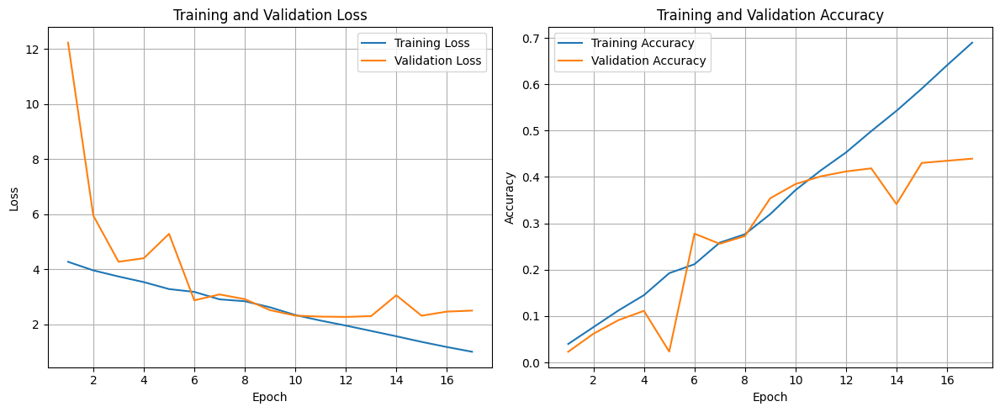

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.4031 - f1_score: 0.3890 - loss: 2.2556 - precision: 0.6716
Test Accuracy: 41.03%
Test Loss: 224.05%
Test Precision: 68.32%
Test F1 Scores (Per Class): [72.98578  37.81094  40.49079  18.897635 18.9781   37.647053 41.176464
 39.344257 60.63829  44.954124 28.025469 19.31034  39.455776 33.43848
 28.947363 28.930813 36.8932   60.98654  31.067955 34.408596 62.222218
 48.695644 27.067665 55.555553 56.122444 32.472317 19.580416 30.120478
 50.19011  30.252098 37.349392 33.766228 28.776974 43.010746 24.817513
 12.499998 47.741932 27.480911 31.847128 52.12121  25.954193 62.365585
 47.05882  45.23809  21.301771 19.999996 29.999996 49.315063 59.154922
 56.37583  21.705421 30.93922  58.555126 69.565216 59.999996 14.765098
 53.08641  49.438194 34.645664 27.586205 78.5276   49.54954  44.295296
 34.042545  8.264459 19.999996 36.986294 31.249994 79.166664 59.31034
 47.61904  63.59446  15.873012 44.21052  25.850338 62.944157 62.63736
 27.551016 27.8

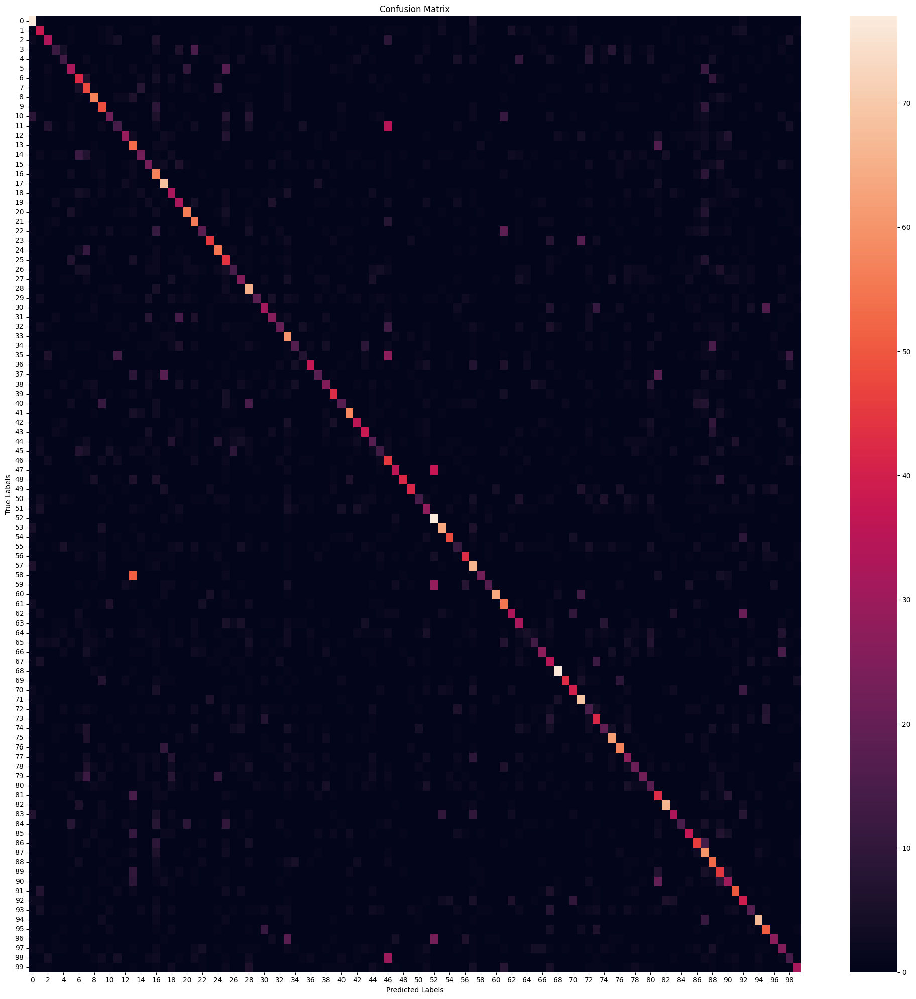

                   precision    recall  f1-score   support

           beaver       0.64      0.86      0.73        90
          dolphin       0.34      0.42      0.38        90
            otter       0.45      0.37      0.40        90
             seal       0.32      0.13      0.19        90
            whale       0.28      0.14      0.19        90
    aquarium fish       0.40      0.36      0.38        90
         flatfish       0.37      0.47      0.41        90
              ray       0.31      0.53      0.39        90
            shark       0.58      0.63      0.61        90
            trout       0.38      0.54      0.45        90
          orchids       0.33      0.24      0.28        90
          poppies       0.25      0.16      0.19        90
            roses       0.51      0.32      0.39        90
       sunflowers       0.23      0.59      0.33        90
           tulips       0.35      0.24      0.29        90
          bottles       0.33      0.26      0.29       

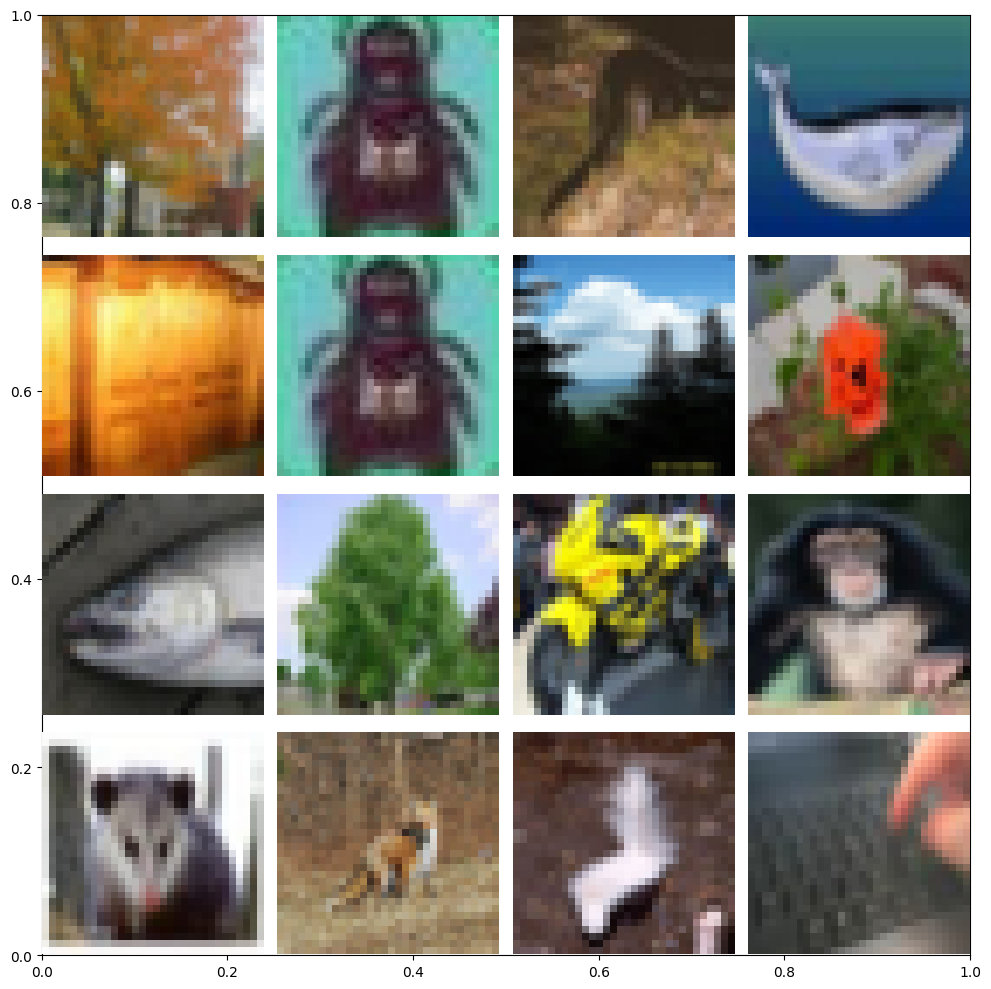

labels[17162].shape: (1,)
imgs[17162].shape: (32, 32, 3)


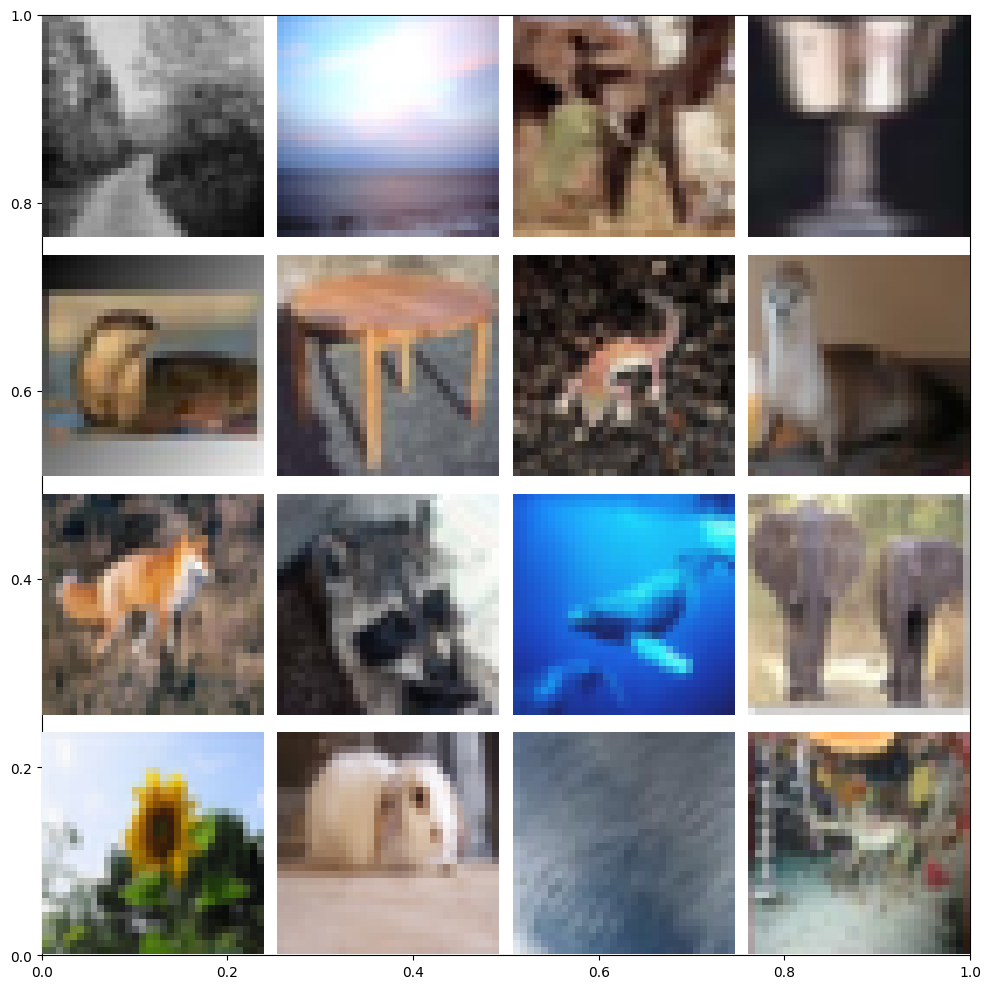

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


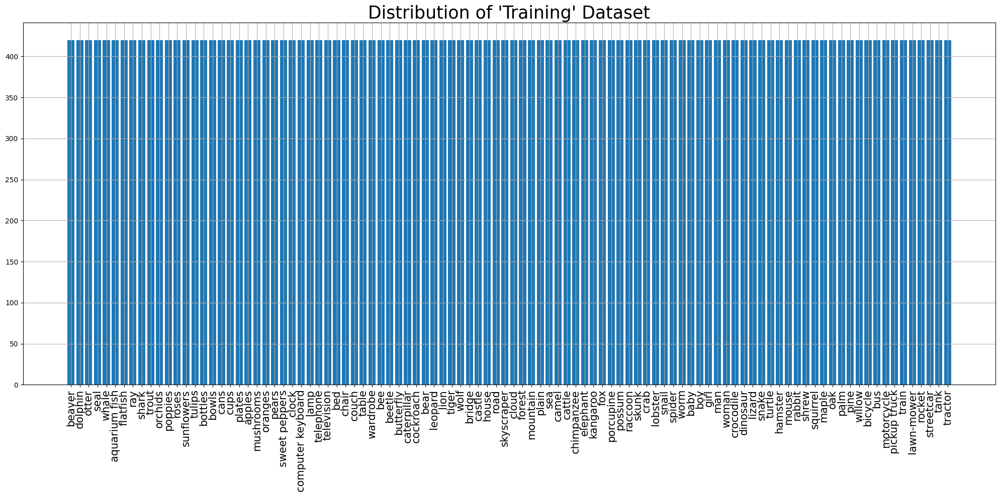

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


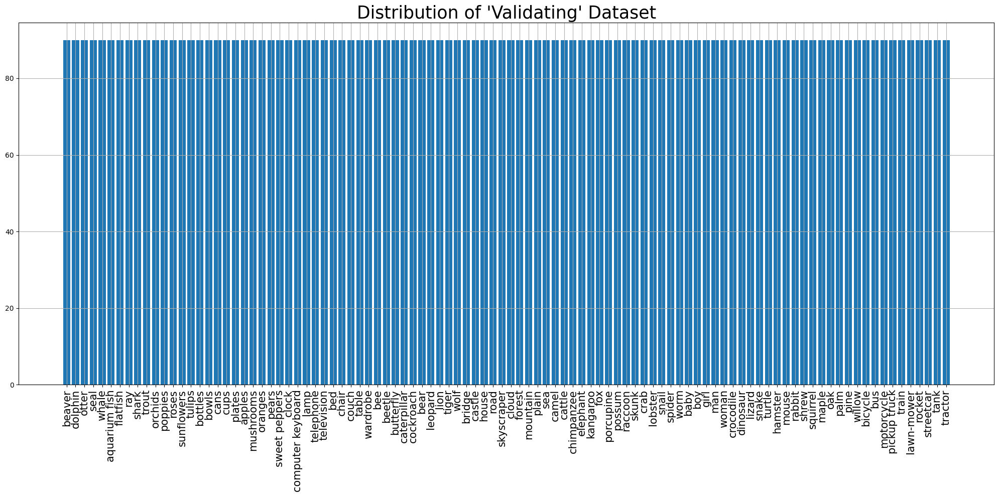

<ipython-input-12-e9907fed57ee>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


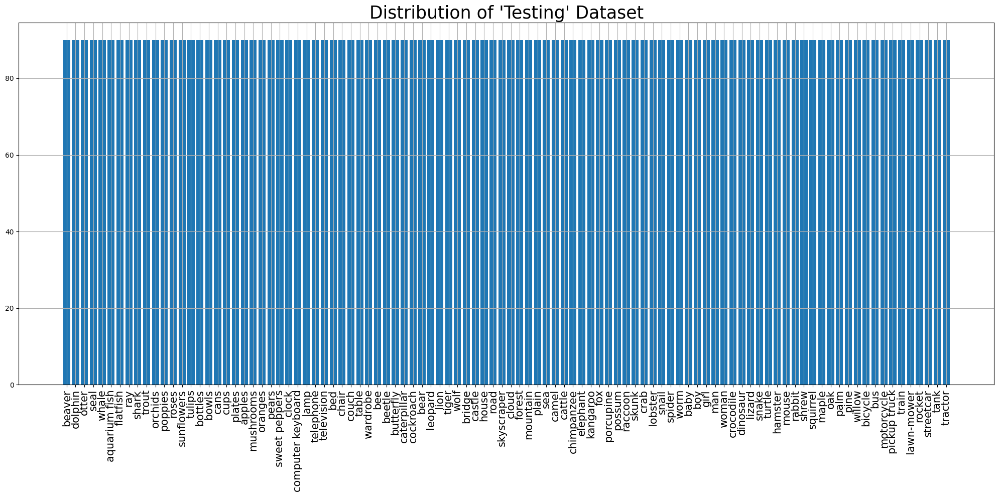

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_10          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 24,619,748 (93.92 MB)

 Non-trainable params: 45,440 (177.50 KB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 115s 106ms/step - accuracy: 0.0175 - f1_score: 0.0097 - loss: 4.5675 - precision: 0.1271 - val_accuracy: 0.0187 - val_f1_score: 0.0029 - val_loss: 7.2379 - val_precision: 0.0358
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.0309 - f1_score: 0.0181 - loss: 4.3453 - precision: 0.1397 - val_accuracy: 0.0452 - val_f1_score: 0.0190 - val_loss: 4.5566 - val_precision: 0.1628
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.0566 - f1_score: 0.0418 - loss: 4.0928 - precision: 0.3221 - val_accuracy: 0.0772 - val_f1_score: 0.0438 - val_loss: 4.0322 - val_precision: 0.4586
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.0875 - f1_score: 0.0688 - loss: 3.8569 - precision: 0.3341 - val_accuracy: 0.1211 - val_f1_score: 0.0888 - val_loss: 3.6665 - val_precision: 0.6852
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 70ms/step - accuracy: 0.1090 - f1_score: 0.0907 - loss: 3.7251 - precision: 0.5653 - val_a

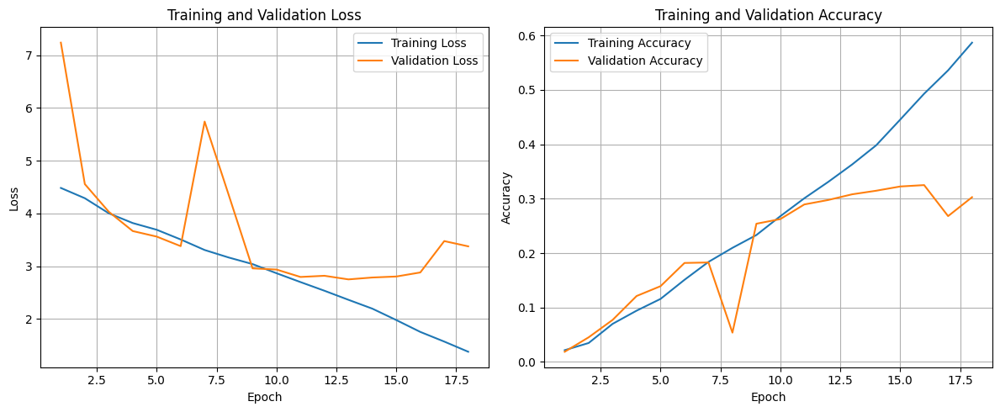

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3049 - f1_score: 0.2872 - loss: 2.7337 - precision: 0.6770
Test Accuracy: 31.28%
Test Loss: 272.10%
Test Precision: 67.29%
Test F1 Scores (Per Class): [64.93506   30.872477  21.468922   3.6036007 16.666662  19.999996
 41.610733  33.77777   32.25806   42.857136  17.460314  22.58064
 24.060148  26.609436  21.739126  15.789472  42.708324  53.080566
 25.714281  21.212118  57.516335  35.78947   18.897635  48.205124
 52.325577  19.814238  19.047617  18.548384  39.81481   22.97297
 31.578945  32.173912  26.519335  23.873869  27.027023  14.925369
 35.71428    7.874011   0.        29.743586   8.080808  60.60605
 26.027393  24.675318  17.283947  10.344825  22.006468  42.45809
 39.682537  44.571423  14.130431  13.664591  51.95729   66.32652
 44.927532   6.779658  39.370075  36.2573    31.620546  18.803413
 73.62636   40.495865  45.55555   19.847322  13.333329   3.883493
 11.382112  25.806444  63.507103  47.142853  41.34615   58.163254
 12.21

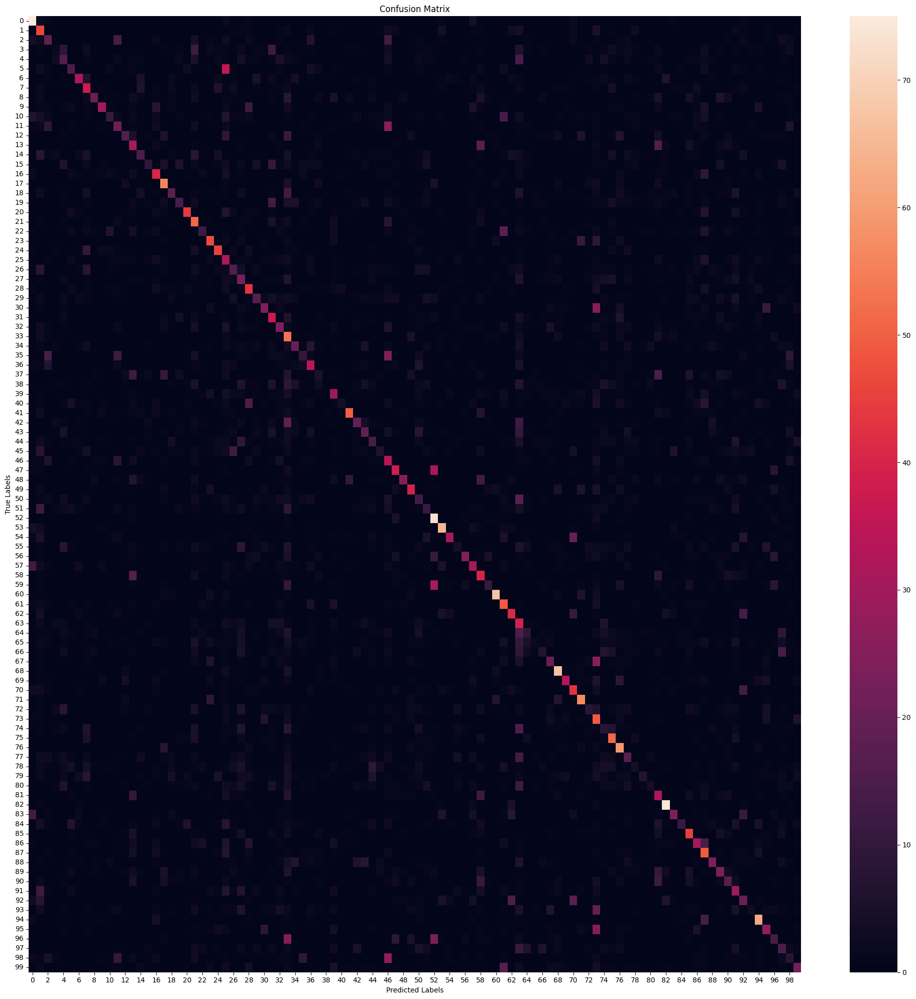

                   precision    recall  f1-score   support

           beaver       0.53      0.83      0.65        90
          dolphin       0.22      0.51      0.31        90
            otter       0.22      0.21      0.21        90
             seal       0.10      0.02      0.04        90
            whale       0.16      0.18      0.17        90
    aquarium fish       0.25      0.17      0.20        90
         flatfish       0.53      0.34      0.42        90
              ray       0.28      0.42      0.34        90
            shark       0.59      0.22      0.32        90
            trout       0.60      0.33      0.43        90
          orchids       0.31      0.12      0.17        90
          poppies       0.22      0.23      0.23        90
            roses       0.37      0.18      0.24        90
       sunflowers       0.22      0.34      0.27        90
           tulips       0.31      0.17      0.22        90
          bottles       0.38      0.10      0.16       

In [12]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = True

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=0.003),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

# Increase model complexity () add layers ), reduce dropout and more epochs for overfitting

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[20643].shape: (1,)
imgs[20643].shape: (32, 32, 3)


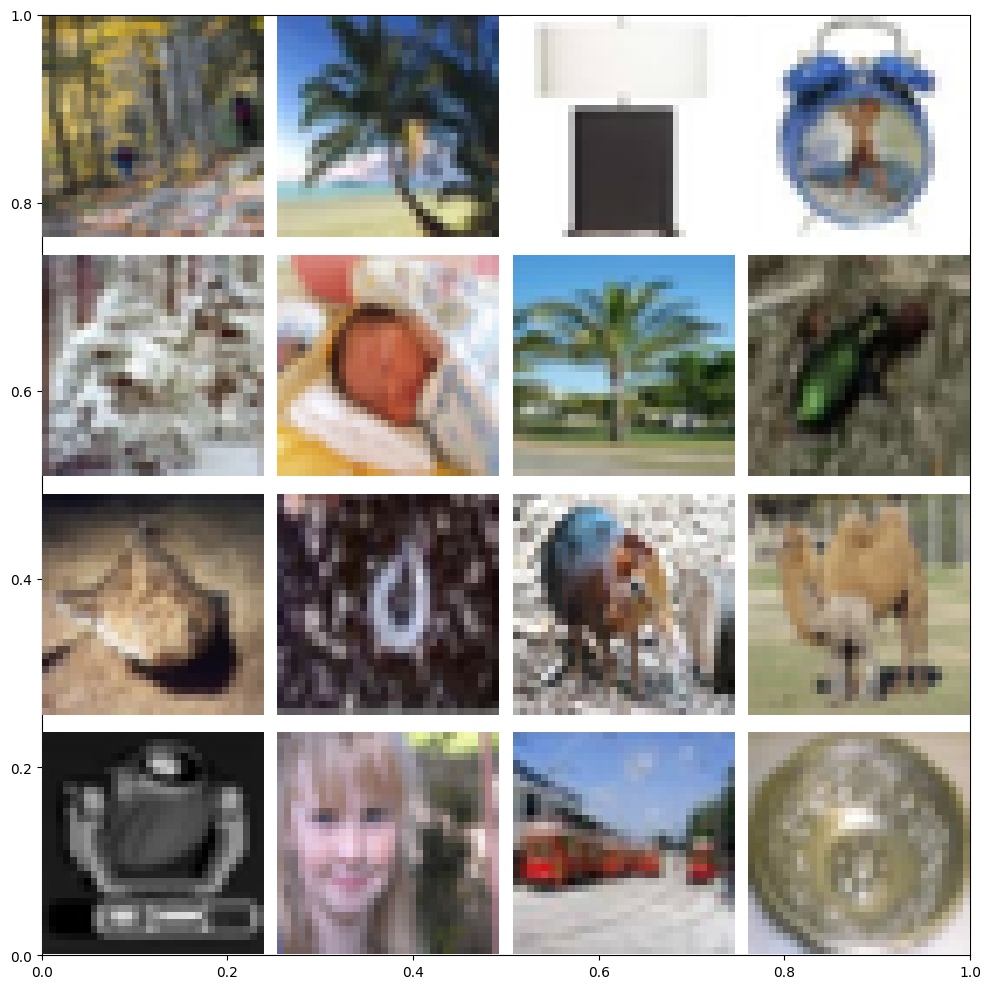

labels[25617].shape: (1,)
imgs[25617].shape: (32, 32, 3)


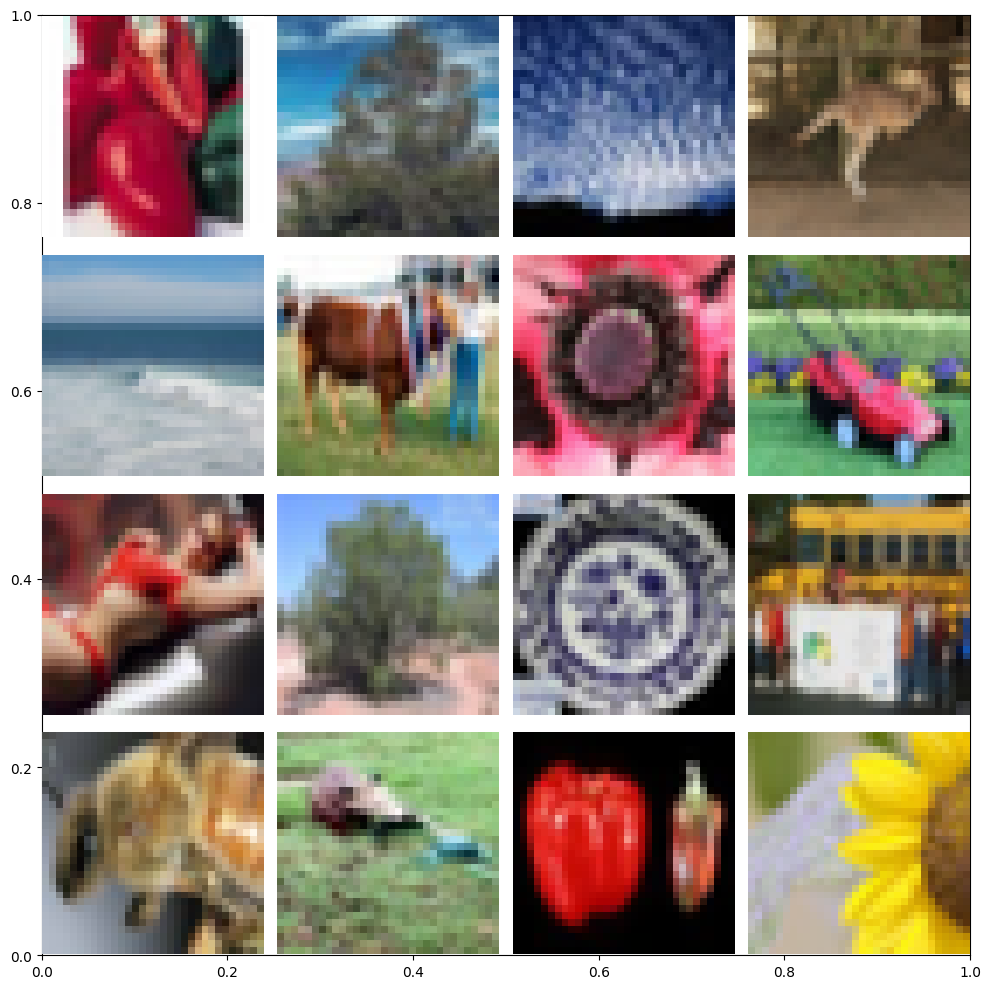

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


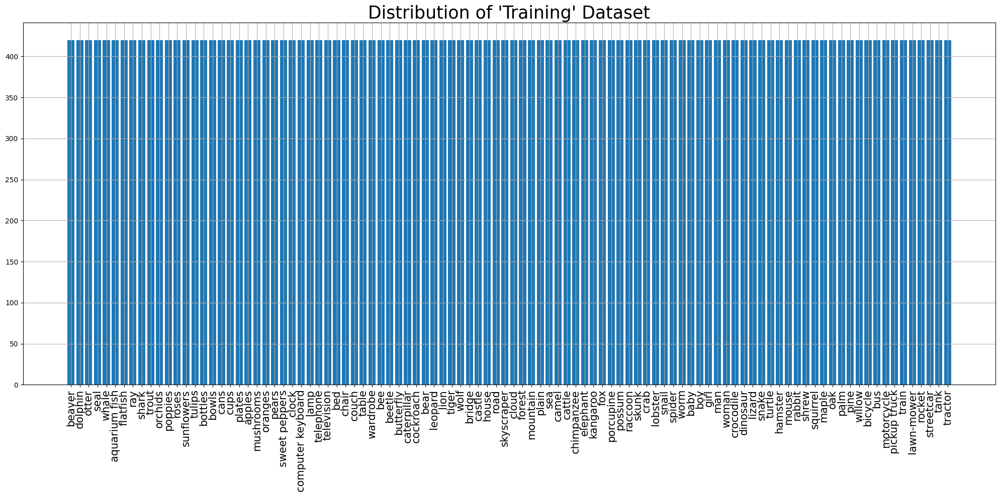

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


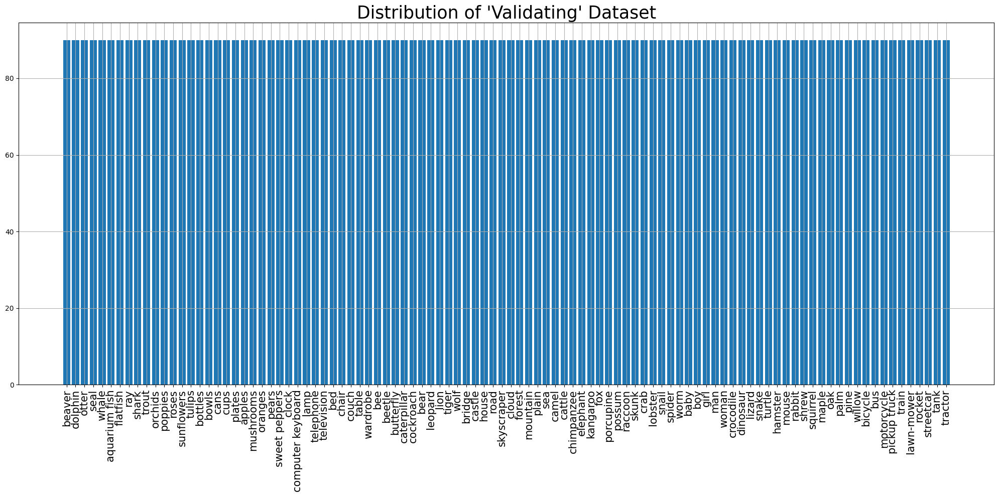

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


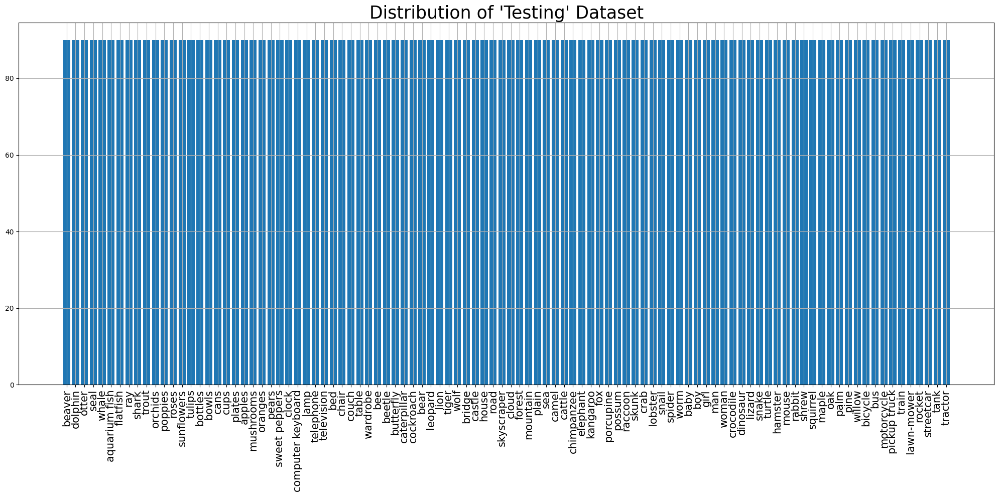

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_11          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,501,732 (101.10 MB)

 Trainable params: 2,936,932 (11.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 59s 59ms/step - accuracy: 0.3478 - f1_score: 0.3418 - loss: 2.5766 - precision: 0.6353 - val_accuracy: 0.5170 - val_f1_score: 0.5085 - val_loss: 1.7630 - val_precision: 0.7391
Epoch 2/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5573 - f1_score: 0.5539 - loss: 1.6155 - precision: 0.7560 - val_accuracy: 0.5523 - val_f1_score: 0.5464 - val_loss: 1.7133 - val_precision: 0.7412
Epoch 3/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6156 - f1_score: 0.6124 - loss: 1.3631 - precision: 0.7907 - val_accuracy: 0.5581 - val_f1_score: 0.5569 - val_loss: 1.7749 - val_precision: 0.7209
Epoch 4/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6588 - f1_score: 0.6560 - loss: 1.1988 - precision: 0.8105 - val_accuracy: 0.5618 - val_f1_score: 0.5578 - val_loss: 1.8784 - val_precision: 0.7109
Epoch 5/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6837 - f1_score: 0.6813 - loss: 1.1045 - precision: 0.8200 - val_acc

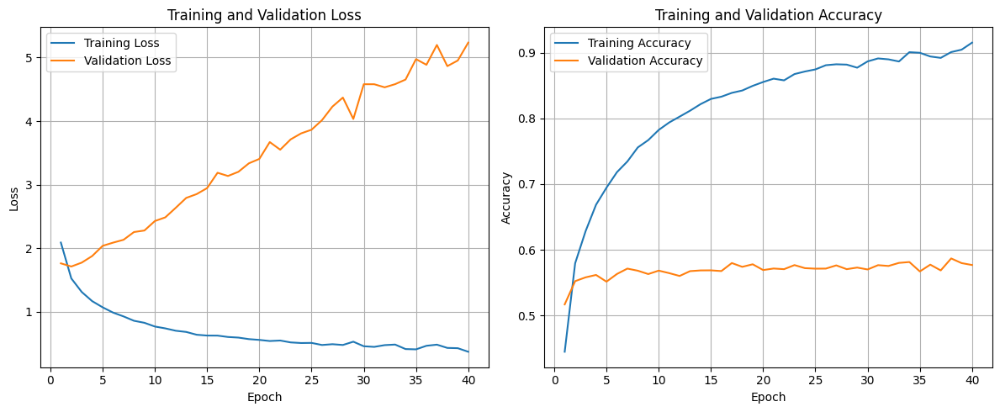

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5786 - f1_score: 0.5757 - loss: 5.1580 - precision: 0.6400
Test Accuracy: 58.40%
Test Loss: 502.87%
Test Precision: 64.79%
Test F1 Scores (Per Class): [79.79274  69.135796 45.535706 41.558437 32.989685 50.66666  51.308887
 56.043945 73.809525 79.75459  47.682114 40.816322 67.51592  56.774185
 59.016384 56.6265   73.46938  71.51515  49.746185 45.508976 80.82901
 68.78981  74.28571  72.04301  69.18238  53.45622  44.808735 40.223457
 76.74419  47.39884  59.036137 55.384613 39.999996 56.71641  60.09851
 33.333324 65.16853  44.565212 49.72375  87.86127  63.354034 75.40983
 58.88888  64.739876 44.943817 33.83084  38.993706 51.08225  79.166664
 80.95238  26.829264 62.944157 58.024685 82.95453  65.60846  25.149694
 76.300575 65.217384 71.95121  42.352932 75.14451  69.87952  52.41379
 58.757053 40.75829  37.735844 61.452507 47.61904  82.285706 77.98741
 60.82474  68.508286 24.277452 49.999992 30.232555 79.79274  75.12195
 48.837204 60.9756

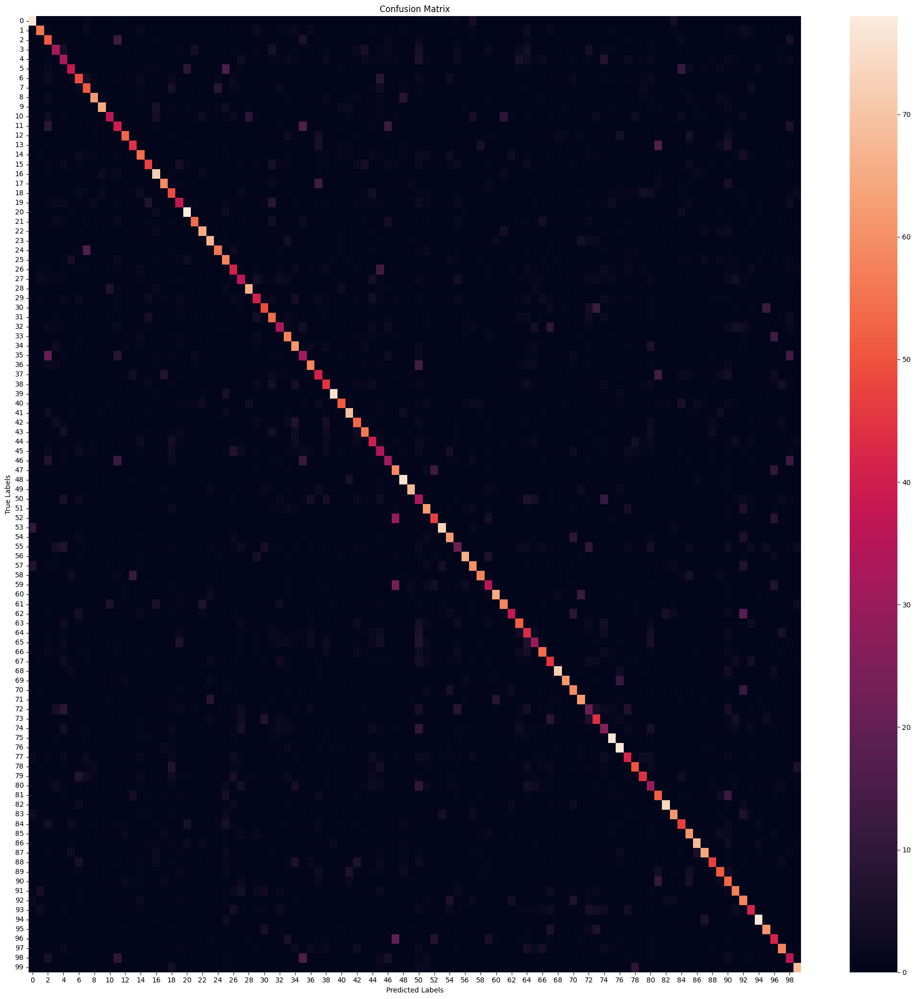

                   precision    recall  f1-score   support

           beaver       0.75      0.86      0.80        90
          dolphin       0.78      0.62      0.69        90
            otter       0.38      0.57      0.46        90
             seal       0.50      0.36      0.42        90
            whale       0.31      0.36      0.33        90
    aquarium fish       0.63      0.42      0.51        90
         flatfish       0.49      0.54      0.51        90
              ray       0.55      0.57      0.56        90
            shark       0.79      0.69      0.74        90
            trout       0.89      0.72      0.80        90
          orchids       0.59      0.40      0.48        90
          poppies       0.38      0.44      0.41        90
            roses       0.79      0.59      0.68        90
       sunflowers       0.67      0.49      0.56        90
           tulips       0.58      0.60      0.59        90
          bottles       0.62      0.52      0.57       

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_11          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,501,732 (101.10 MB)

 Trainable params: 6,352,996 (24.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.7181 - f1_score: 0.7189 - loss: 2.2326 - precision: 0.7898 - val_accuracy: 0.5506 - val_f1_score: 0.5547 - val_loss: 5.0538 - val_precision: 0.6370
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.8217 - f1_score: 0.8217 - loss: 0.8317 - precision: 0.8903 - val_accuracy: 0.5637 - val_f1_score: 0.5679 - val_loss: 4.8229 - val_precision: 0.6485
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.8683 - f1_score: 0.8679 - loss: 0.5250 - precision: 0.9284 - val_accuracy: 0.5671 - val_f1_score: 0.5714 - val_loss: 4.7650 - val_precision: 0.6493
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.8988 - f1_score: 0.8982 - loss: 0.3798 - precision: 0.9527 - val_accuracy: 0.5724 - val_f1_score: 0.5762 - val_loss: 4.7825 - val_precision: 0.6524
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.9176 - f1_score: 0.9169 - loss: 0.2934 - precision: 0.9665 - val_acc

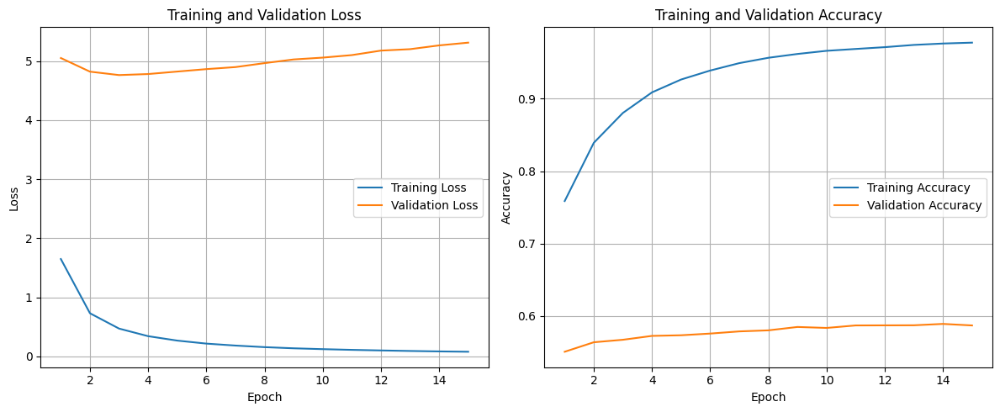

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5805 - f1_score: 0.5791 - loss: 5.2498 - precision: 0.6401
Test Accuracy: 58.83%
Test Loss: 511.20%
Test Precision: 64.54%
Test F1 Scores (Per Class): [84.26965  69.82249  42.156857 42.45809  35.23315  60.439552 54.117645
 57.14285  74.07407  74.69879  51.891888 37.078648 64.13043  53.333324
 58.536575 57.499992 75.268814 67.85713  40.191383 49.032253 79.09604
 72.92817  74.28571  70.05649  75.58139  53.551907 50.810806 38.54166
 80.681816 56.497173 57.80347  58.749992 35.15151  54.54545  67.6923
 31.632647 60.24096  47.368412 45.61403  87.29281  62.06896  79.55801
 59.893044 63.473045 44.06779  39.57219  46.590904 48.554905 79.775276
 78.453026 29.729725 64.40677  59.340656 85.86956  64.94845  29.864246
 71.604935 70.65217  74.84662  45.901634 72.31638  70.37037  54.545456
 60.465115 36.90476  37.714283 64.36781  49.46236  79.53216  77.77777
 63.09523  68.449196 26.13065  52.747242 30.769222 78.68852  75.39267
 55.43478  60.57142

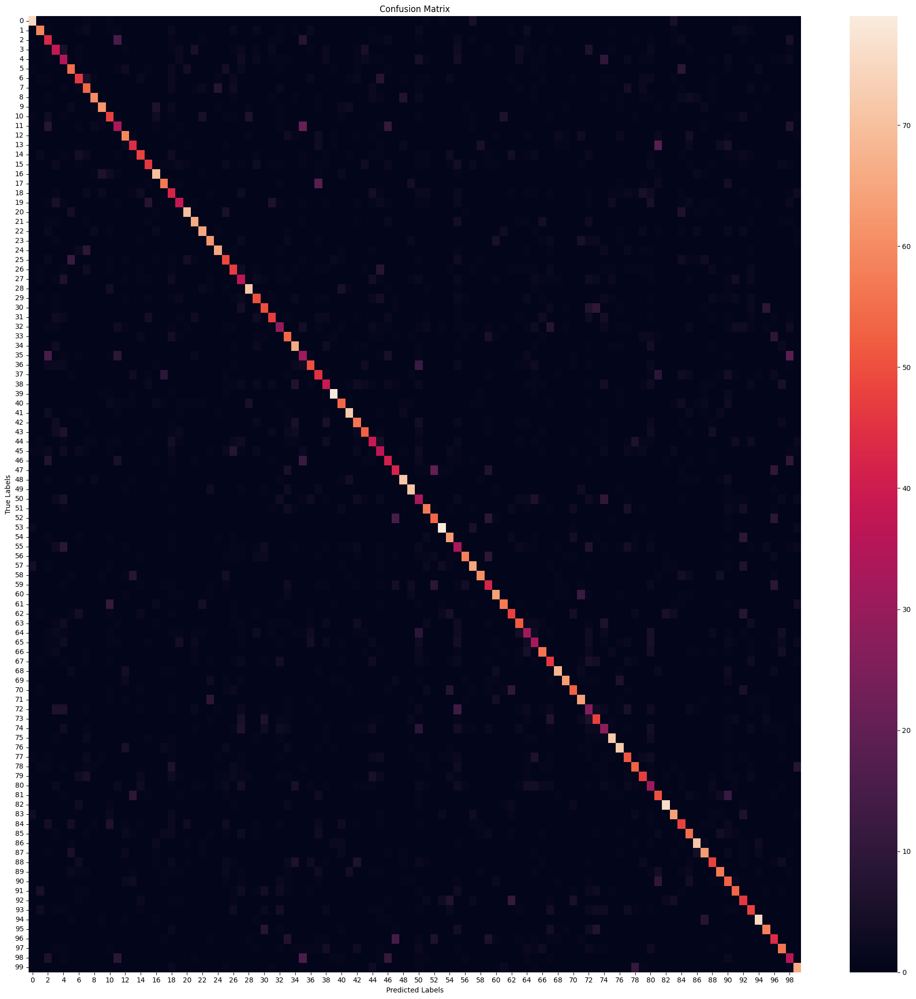

                   precision    recall  f1-score   support

           beaver       0.85      0.83      0.84        90
          dolphin       0.75      0.66      0.70        90
            otter       0.38      0.48      0.42        90
             seal       0.43      0.42      0.42        90
            whale       0.33      0.38      0.35        90
    aquarium fish       0.60      0.61      0.60        90
         flatfish       0.57      0.51      0.54        90
              ray       0.55      0.60      0.57        90
            shark       0.83      0.67      0.74        90
            trout       0.82      0.69      0.75        90
          orchids       0.51      0.53      0.52        90
          poppies       0.38      0.37      0.37        90
            roses       0.63      0.66      0.64        90
       sunflowers       0.59      0.49      0.53        90
           tulips       0.65      0.53      0.59        90
          bottles       0.66      0.51      0.57       

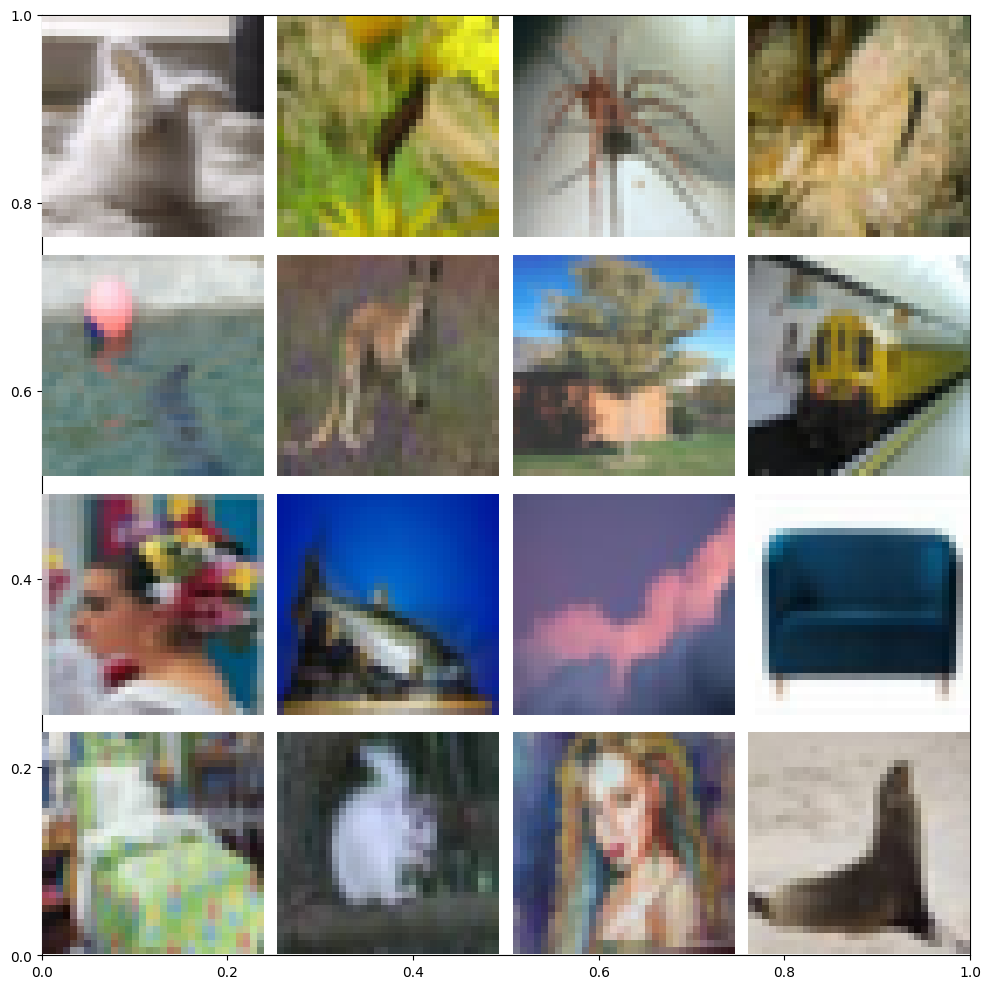

labels[31226].shape: (1,)
imgs[31226].shape: (32, 32, 3)


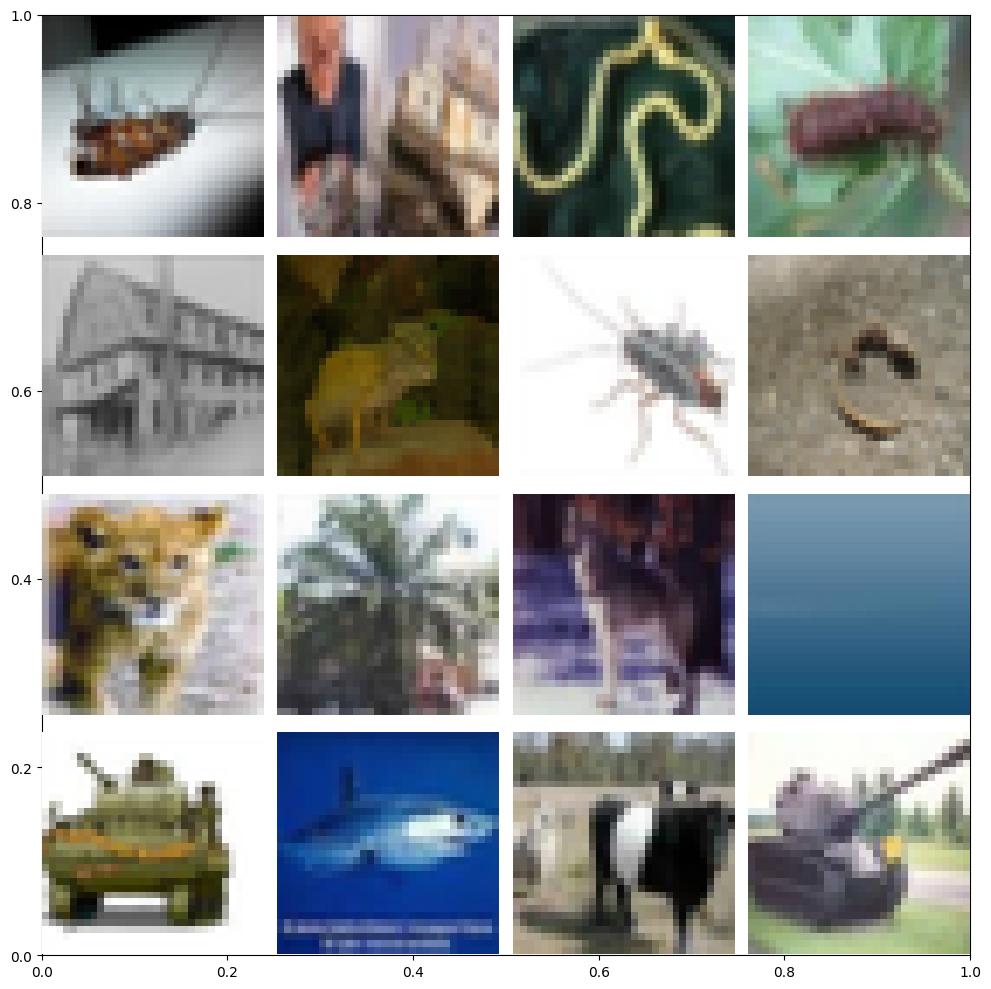

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


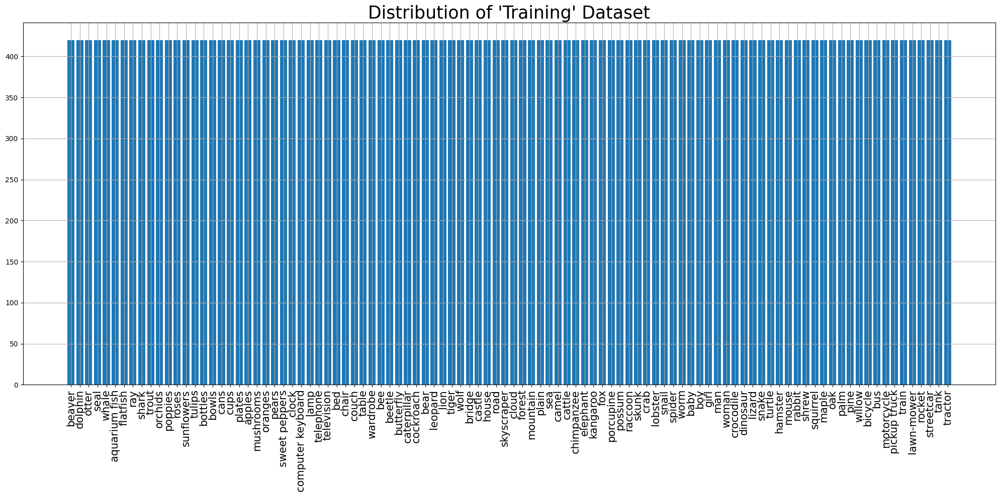

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


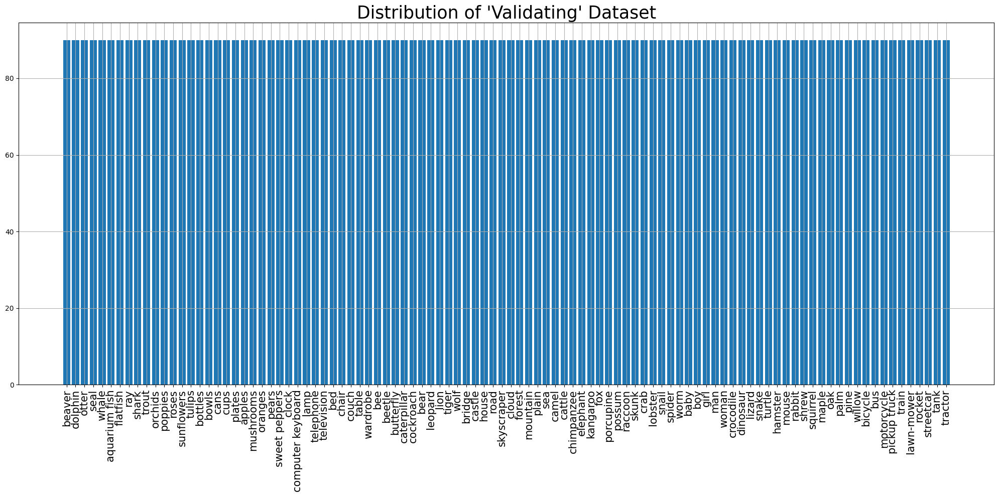

<ipython-input-13-fba5e819bf5b>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


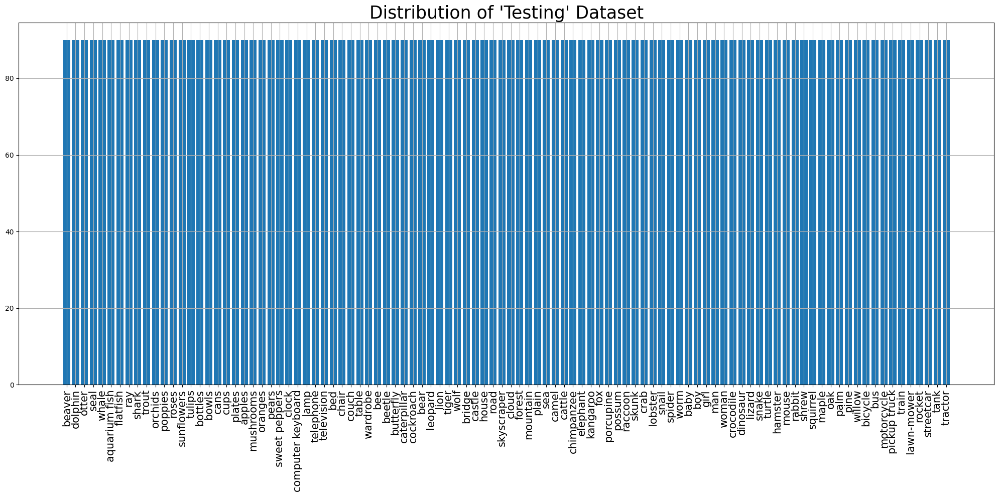

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_12          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_29 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 26,501,732 (101.10 MB)

 Trainable params: 2,936,932 (11.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.3462 - f1_score: 0.3406 - loss: 2.6037 - precision: 0.6461 - val_accuracy: 0.5249 - val_f1_score: 0.5168 - val_loss: 1.7689 - val_precision: 0.7597
Epoch 2/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5548 - f1_score: 0.5511 - loss: 1.6067 - precision: 0.7589 - val_accuracy: 0.5528 - val_f1_score: 0.5455 - val_loss: 1.7714 - val_precision: 0.7310
Epoch 3/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6113 - f1_score: 0.6084 - loss: 1.3785 - precision: 0.7836 - val_accuracy: 0.5518 - val_f1_score: 0.5469 - val_loss: 1.8539 - val_precision: 0.7044
Epoch 4/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6540 - f1_score: 0.6517 - loss: 1.2141 - precision: 0.8059 - val_accuracy: 0.5558 - val_f1_score: 0.5520 - val_loss: 1.9055 - val_precision: 0.7126
Epoch 5/40
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6790 - f1_score: 0.6762 - loss: 1.1140 - precision: 0.8209 - val_acc

KeyboardInterrupt: 

In [13]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(1024, activation='relu'),  # Increase the number of units
        layers.Dense(512, activation='relu'),  # Another hidden layer
        layers.Dense(512, activation='relu'),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=optimizers.Adam(learning_rate=0.003),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=40,
                        batch_size=batch_size, verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (224, 224))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist

# Different optimiser

X_temp.shape: (8000, 32, 32, 3)

X_temp_val.shape: (4000, 32, 32, 3)
y_temp_val.shape: (4000, 1)
X_temp_test.shape: (4000, 32, 32, 3)
y_temp_test.shape: (4000, 1)

X_train.shape: (42000, 32, 32, 3)
y_train.shape: (42000, 1)
X_val.shape: (9000, 32, 32, 3)
y_val.shape: (9000, 1)
X_test.shape: (9000, 32, 32, 3)
y_test.shape: (9000, 1)

labels[9147].shape: (1,)
imgs[9147].shape: (32, 32, 3)


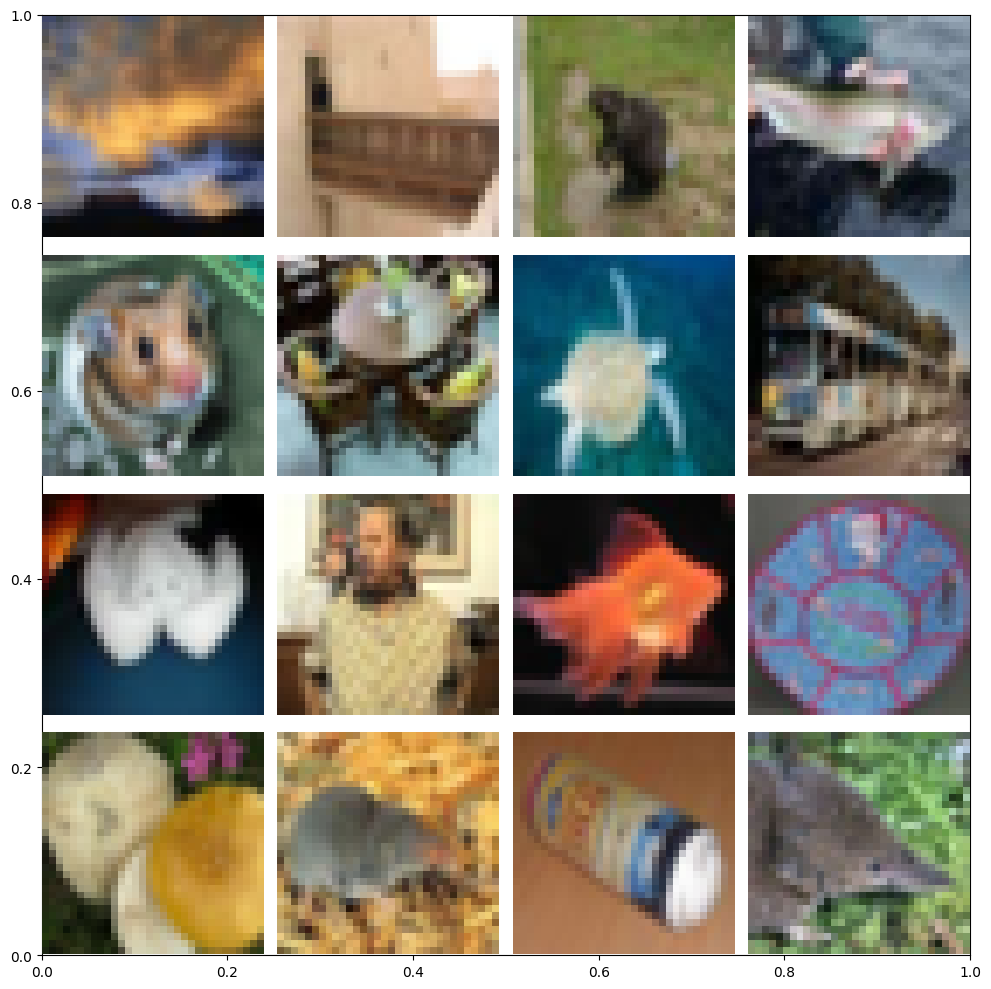

labels[19845].shape: (1,)
imgs[19845].shape: (32, 32, 3)


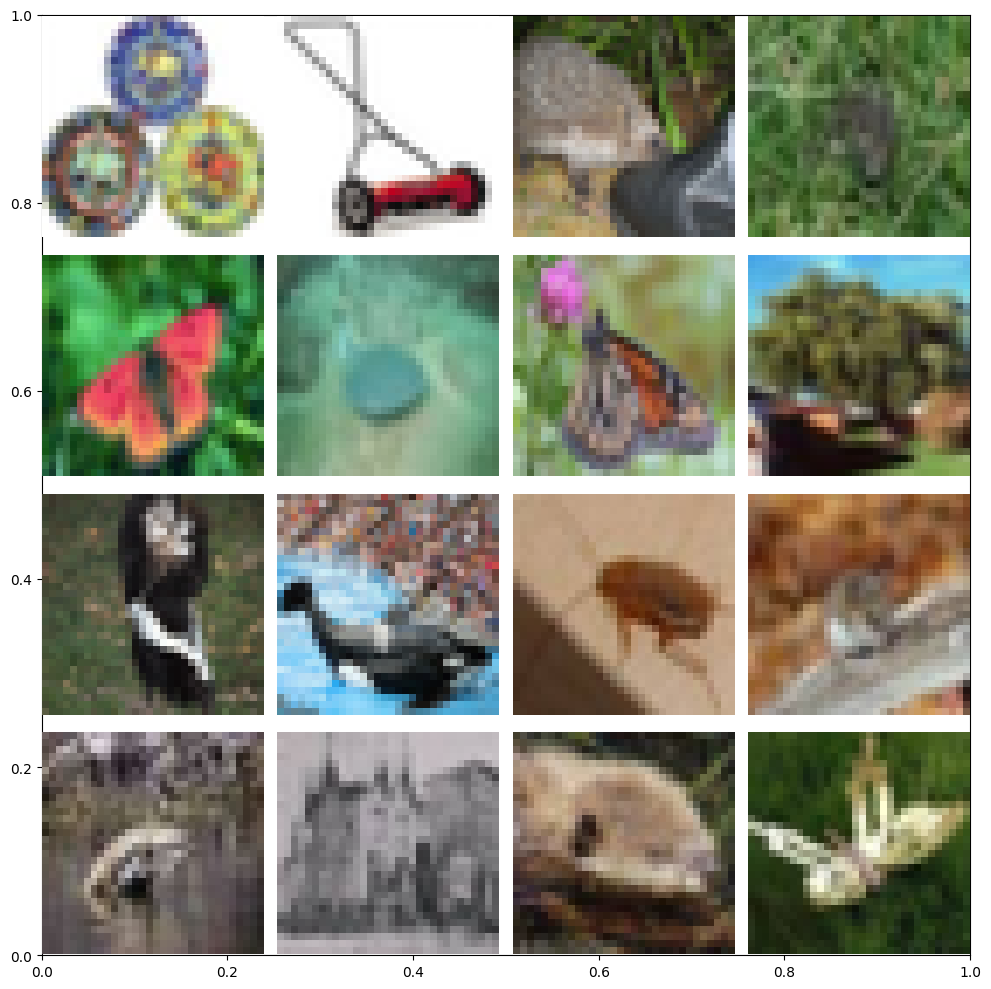

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


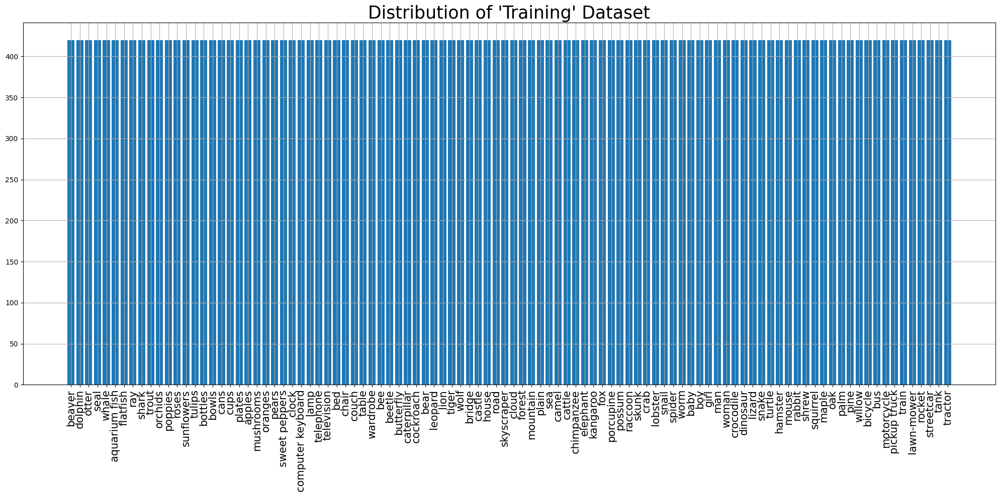

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


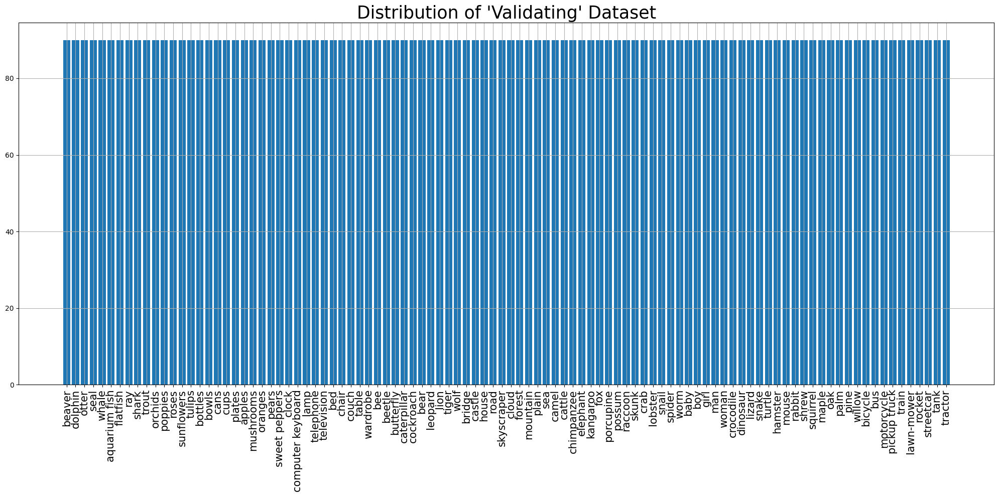

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


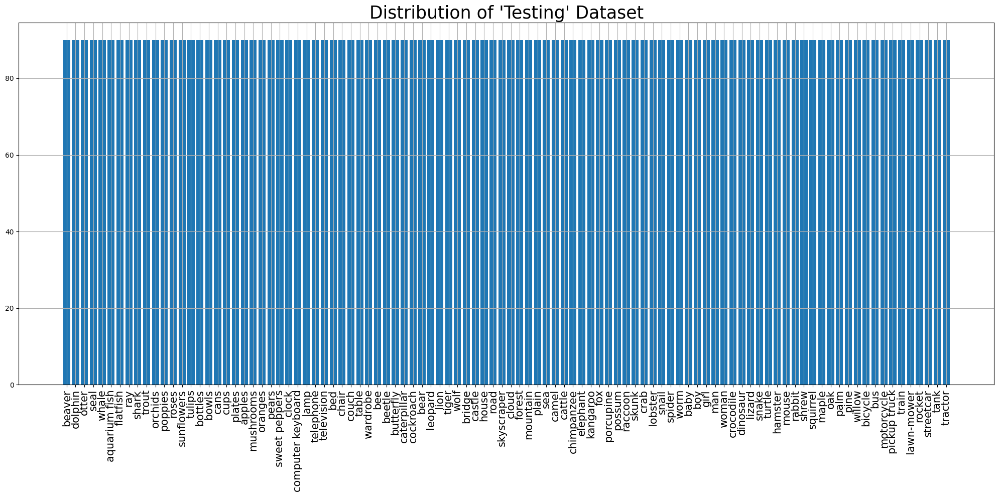

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_17          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_39 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 40s 43ms/step - accuracy: 0.3912 - f1_score: 0.3859 - loss: 2.4845 - precision: 0.6723 - val_accuracy: 0.5853 - val_f1_score: 0.5840 - val_loss: 1.4869 - val_precision: 0.7712
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5868 - f1_score: 0.5829 - loss: 1.5020 - precision: 0.7460 - val_accuracy: 0.6161 - val_f1_score: 0.6130 - val_loss: 1.4212 - val_precision: 0.7652
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6321 - f1_score: 0.6292 - loss: 1.3249 - precision: 0.7677 - val_accuracy: 0.6232 - val_f1_score: 0.6196 - val_loss: 1.4274 - val_precision: 0.7593
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6677 - f1_score: 0.6652 - loss: 1.1963 - precision: 0.7818 - val_accuracy: 0.6282 - val_f1_score: 0.6271 - val_loss: 1.4735 - val_precision: 0.7449
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.6918 - f1_score: 0.6895 - loss: 1.1023 - precision: 0.7953 - val_acc

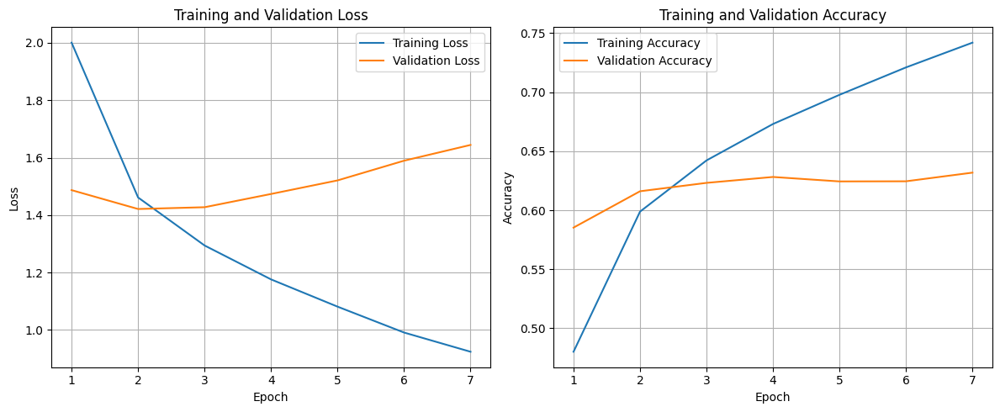

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6055 - f1_score: 0.5957 - loss: 1.4362 - precision: 0.7627
Test Accuracy: 61.42%
Test Loss: 141.92%
Test Precision: 76.62%
Test F1 Scores (Per Class): [79.761894 69.85645  49.450542 36.764698 34.482754 58.447487 53.403137
 67.878784 76.83616  81.60919  55.621304 39.999996 66.666664 54.726364
 62.41134  55.999992 74.64115  58.1132   56.818176 50.505043 75.28088
 70.65217  76.646706 75.86206  80.22598  56.80473  47.74774  44.919785
 74.111664 61.53846  53.012043 66.28571  43.636356 55.865913 58.333324
 26.50602  65.60846  46.341457 51.764698 85.71427  73.493965 81.14285
 54.79452  67.49999  51.65562  43.243237 46.078426 54.14847  74.5098
 82.285706 36.363632 70.15707  59.067356 83.168304 64.62881  39.47368
 77.10842  71.84466  72.10884  48.648647 78.313255 70.83333  54.54545
 60.919537 45.637577 50.66666  56.603767 53.65853  82.653046 77.09496
 65.62499  70.37036  38.277508 57.591618 36.781605 78.723404 80.22598
 50.53763  64.670654

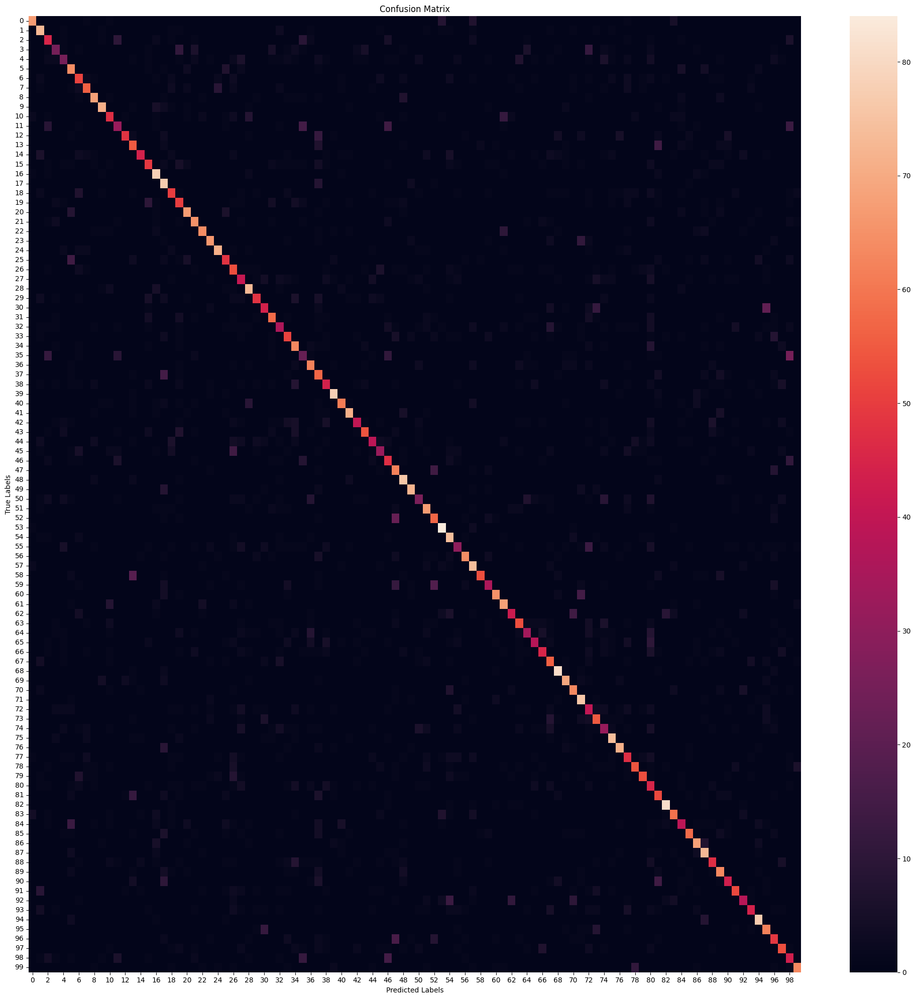

                   precision    recall  f1-score   support

           beaver       0.86      0.74      0.80        90
          dolphin       0.61      0.81      0.70        90
            otter       0.49      0.50      0.49        90
             seal       0.54      0.28      0.37        90
            whale       0.45      0.28      0.34        90
    aquarium fish       0.50      0.71      0.58        90
         flatfish       0.50      0.57      0.53        90
              ray       0.75      0.62      0.68        90
            shark       0.78      0.76      0.77        90
            trout       0.85      0.79      0.82        90
          orchids       0.59      0.52      0.56        90
          poppies       0.46      0.36      0.40        90
            roses       0.89      0.53      0.67        90
       sunflowers       0.50      0.61      0.55        90
           tulips       0.86      0.49      0.62        90
          bottles       0.58      0.54      0.56       

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_17          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_39 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 42s 47ms/step - accuracy: 0.6210 - f1_score: 0.6161 - loss: 1.3713 - precision: 0.7772 - val_accuracy: 0.6336 - val_f1_score: 0.6313 - val_loss: 1.3360 - val_precision: 0.7817
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6716 - f1_score: 0.6680 - loss: 1.1466 - precision: 0.8239 - val_accuracy: 0.6441 - val_f1_score: 0.6420 - val_loss: 1.3062 - val_precision: 0.7797
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6957 - f1_score: 0.6921 - loss: 1.0529 - precision: 0.8304 - val_accuracy: 0.6491 - val_f1_score: 0.6472 - val_loss: 1.2845 - val_precision: 0.7815
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7135 - f1_score: 0.7106 - loss: 0.9890 - precision: 0.8431 - val_accuracy: 0.6538 - val_f1_score: 0.6522 - val_loss: 1.2714 - val_precision: 0.7807
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7305 - f1_score: 0.7278 - loss: 0.9162 - precision: 0.8593 - val_acc

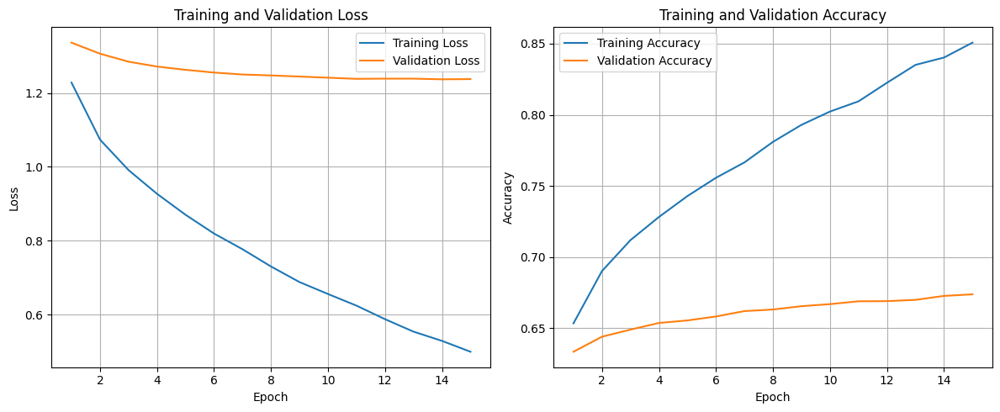

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6659 - f1_score: 0.6577 - loss: 1.2403 - precision: 0.7746
Test Accuracy: 67.42%
Test Loss: 123.04%
Test Precision: 77.88%
Test F1 Scores (Per Class): [87.15083  79.569885 59.016384 50.28571  39.080452 68.23529  63.21243
 70.39106  79.12087  82.02247  65.19337  49.411755 72.41379  61.714287
 67.44185  64.36781  81.24999  78.75647  57.142853 61.87845  79.166664
 76.24309  81.05263  76.24309  81.52173  60.869556 55.91397  48.2412
 76.50272  69.31818  63.387978 71.50838  54.761906 60.396034 70.15707
 32.530113 72.13114  61.452507 53.84615  88.888885 72.63157  79.99999
 66.666664 74.4186   51.6129   48.351646 48.587563 58.682625 83.422455
 79.55801  42.28571  74.117645 67.72487  88.52458  72.53885  44.943817
 79.31035  73.11827  81.21211  57.142853 78.61271  75.55555  64.80447
 67.04545  52.12121  59.66851  66.29213  62.76595  86.516846 82.608696
 69.005844 74.03315  44.692734 64.40677  39.30635  81.52173  88.64864
 62.195118 69.36415

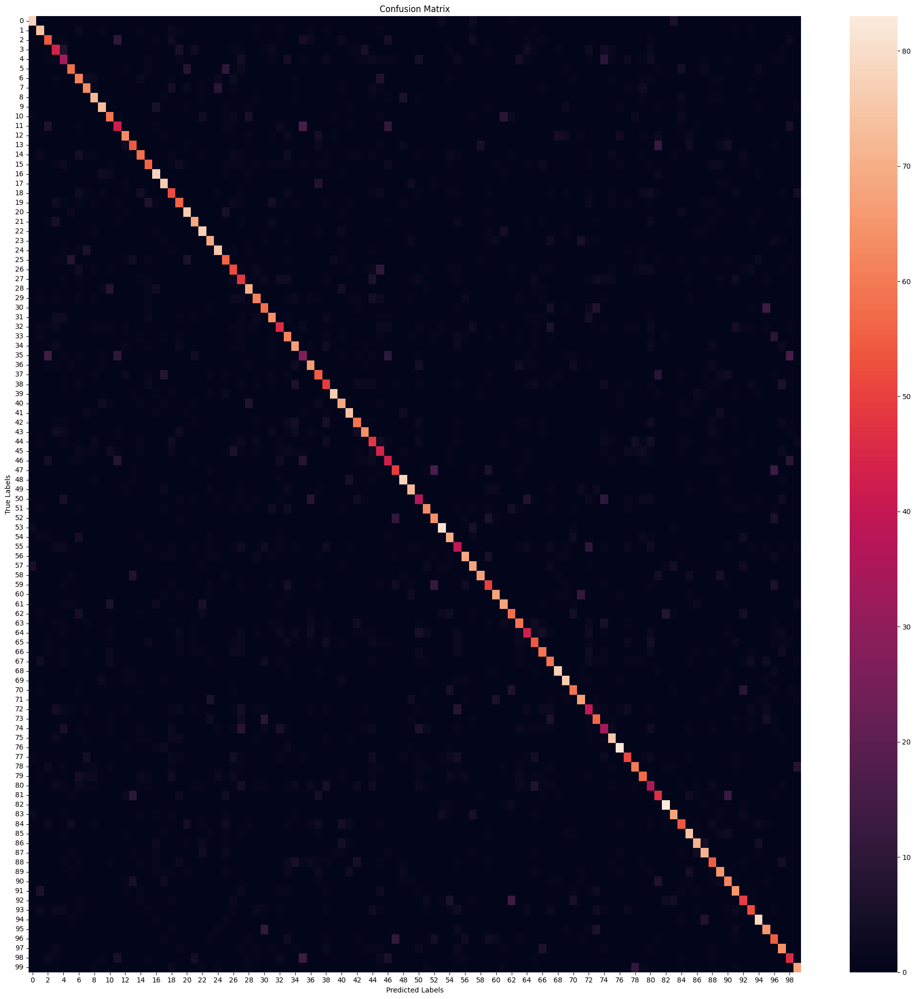

                   precision    recall  f1-score   support

           beaver       0.88      0.87      0.87        90
          dolphin       0.77      0.82      0.80        90
            otter       0.58      0.60      0.59        90
             seal       0.52      0.49      0.50        90
            whale       0.40      0.38      0.39        90
    aquarium fish       0.72      0.64      0.68        90
         flatfish       0.59      0.68      0.63        90
              ray       0.71      0.70      0.70        90
            shark       0.78      0.80      0.79        90
            trout       0.83      0.81      0.82        90
          orchids       0.65      0.66      0.65        90
          poppies       0.53      0.47      0.49        90
            roses       0.75      0.70      0.72        90
       sunflowers       0.64      0.60      0.62        90
           tulips       0.71      0.64      0.67        90
          bottles       0.67      0.62      0.64       

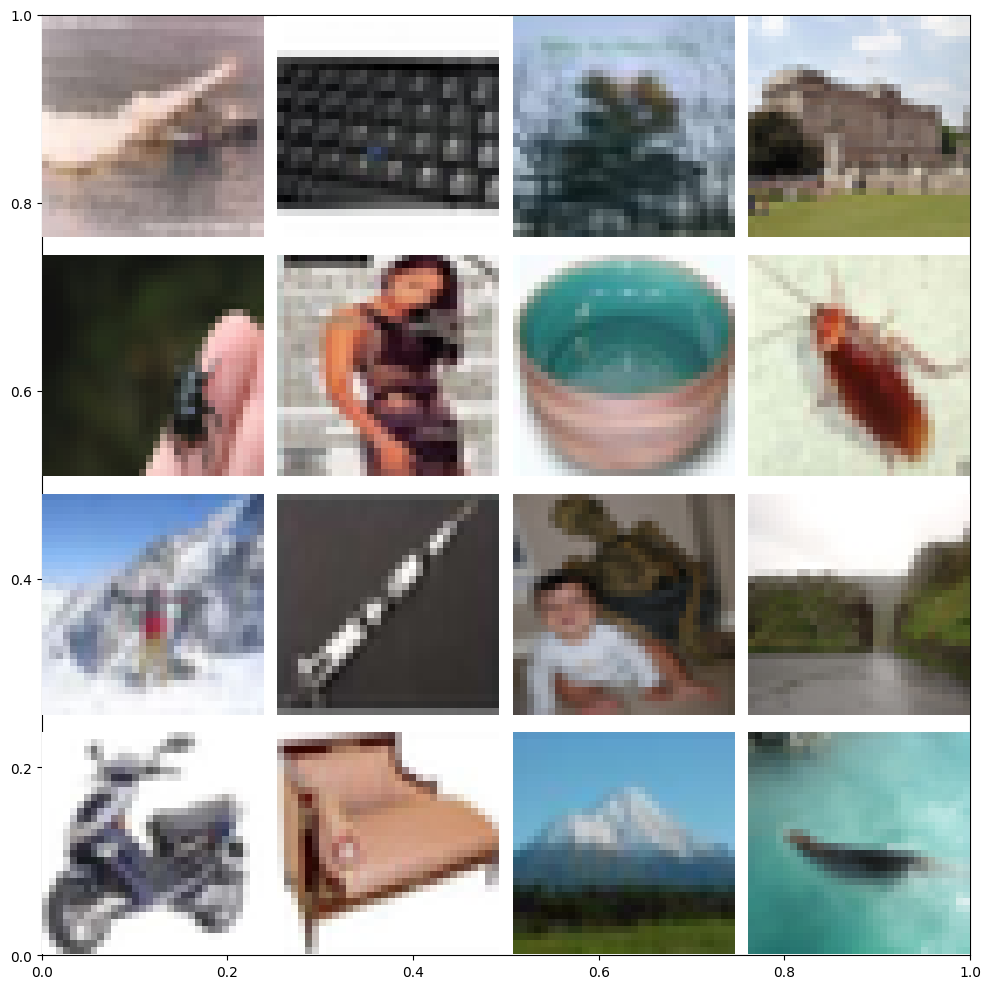

labels[28857].shape: (1,)
imgs[28857].shape: (32, 32, 3)


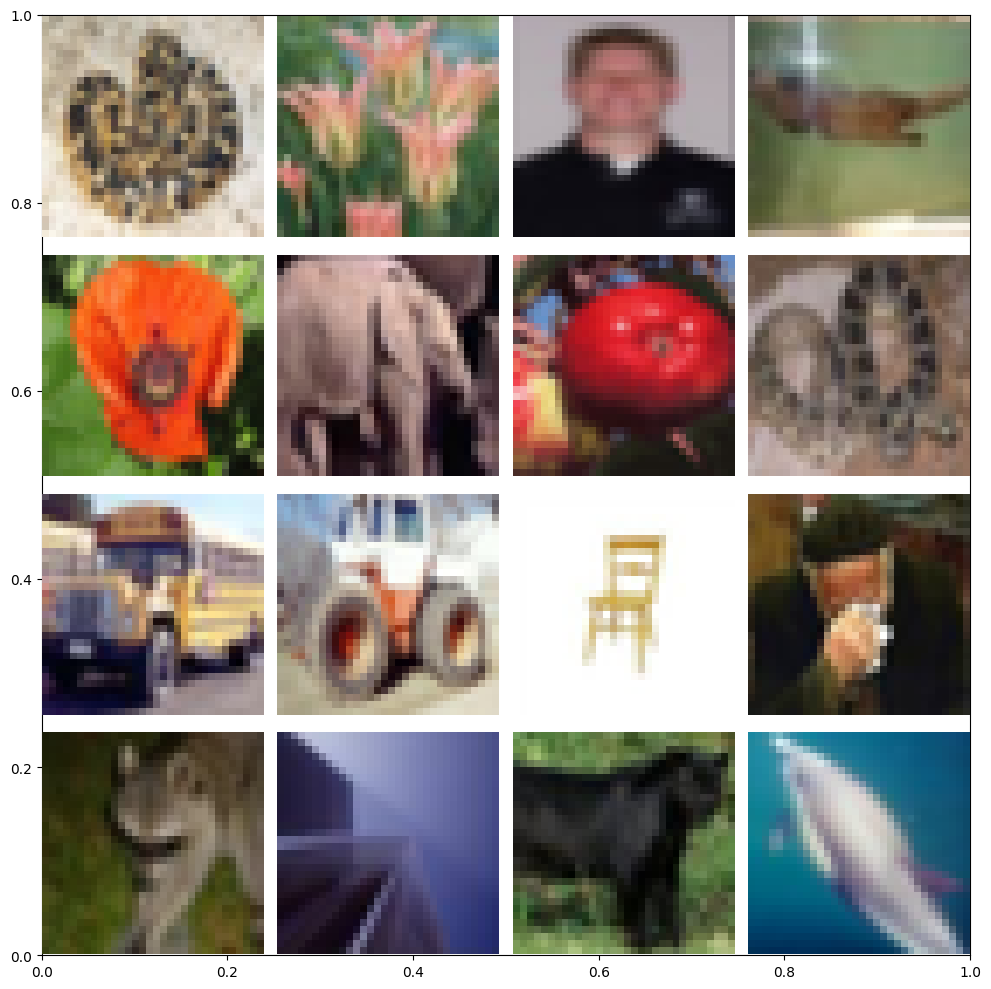

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


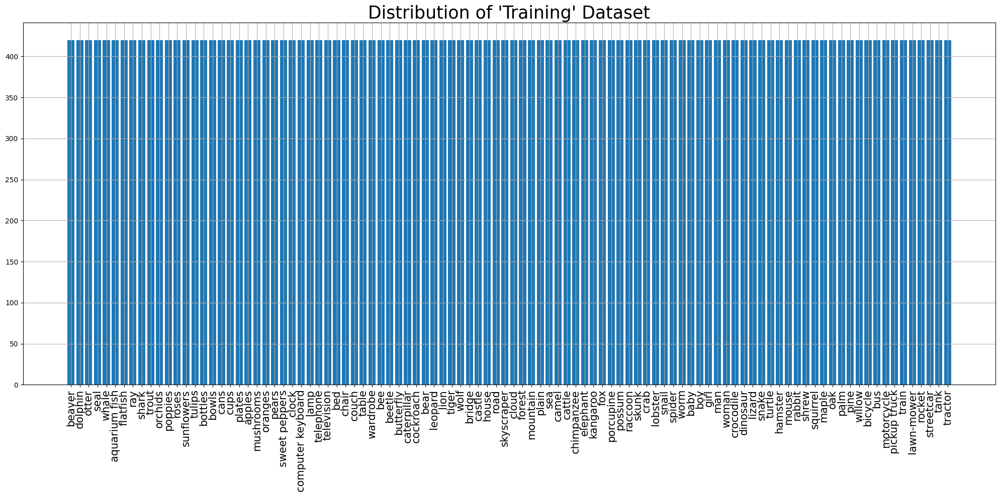

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


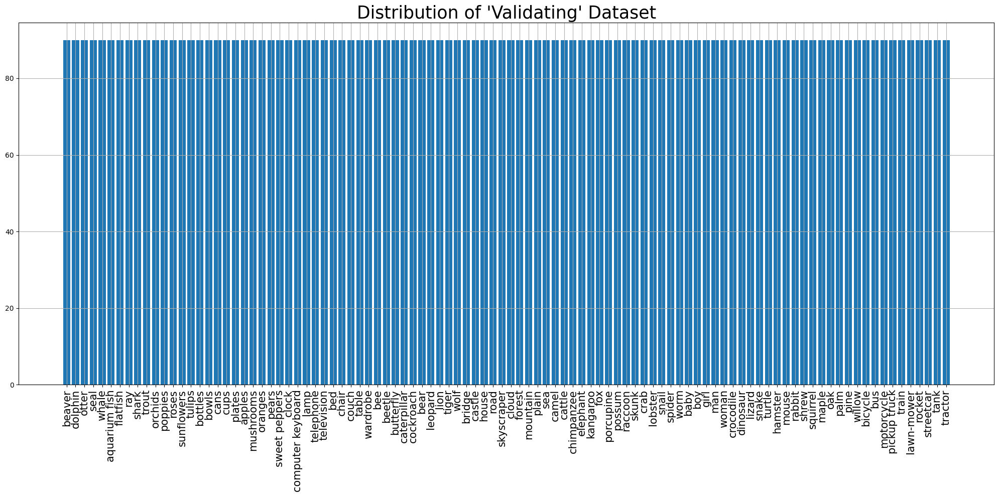

<ipython-input-18-da7612e895bf>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_names, rotation=90, fontsize=15)


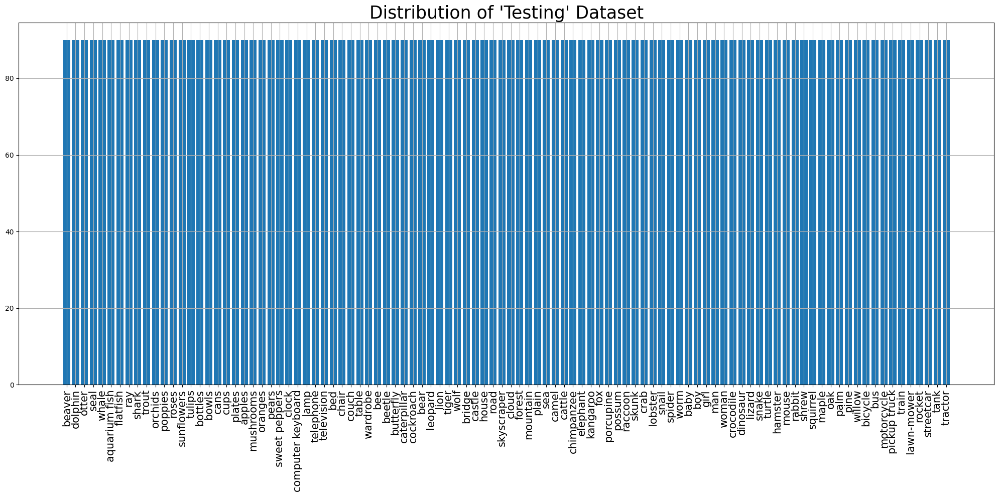

Training dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Validation dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)

Testing dataset:
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 100), dtype=tf.float32, name=None))>
Image shape: (64, 224, 224, 3)
Label shape: (64, 100)
<class 'tuple'>
2
<class 'tensorflow.python.framework.ops.EagerTensor'> <class 'tensorflow.python.framework.ops.EagerTensor'>
(64, 224, 224, 3)
(64, 100)
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 100)
2
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(64, 224, 224, 3) (6

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_18          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_40 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_41 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 1,100,388 (4.20 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 38s 42ms/step - accuracy: 0.3978 - f1_score: 0.3919 - loss: 2.4711 - precision: 0.6923 - val_accuracy: 0.5922 - val_f1_score: 0.5886 - val_loss: 1.4642 - val_precision: 0.7730
Epoch 2/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.5866 - f1_score: 0.5834 - loss: 1.5068 - precision: 0.7474 - val_accuracy: 0.6143 - val_f1_score: 0.6147 - val_loss: 1.4156 - val_precision: 0.7628
Epoch 3/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.6315 - f1_score: 0.6290 - loss: 1.3280 - precision: 0.7635 - val_accuracy: 0.6190 - val_f1_score: 0.6158 - val_loss: 1.4550 - val_precision: 0.7405
Epoch 4/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.6700 - f1_score: 0.6672 - loss: 1.1859 - precision: 0.7878 - val_accuracy: 0.6260 - val_f1_score: 0.6246 - val_loss: 1.5111 - val_precision: 0.7358
Epoch 5/25
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.6930 - f1_score: 0.6906 - loss: 1.1024 - precision: 0.7949 - val_acc

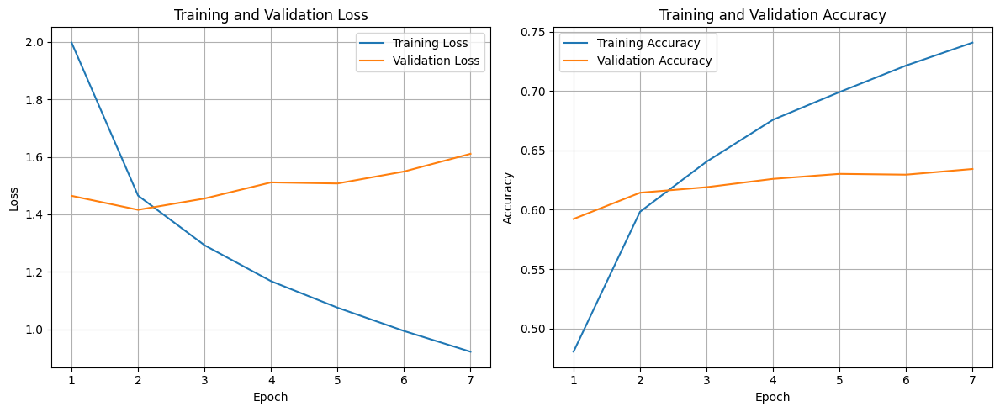

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6078 - f1_score: 0.6016 - loss: 1.4435 - precision: 0.7528
Test Accuracy: 61.81%
Test Loss: 142.10%
Test Precision: 75.83%
Test F1 Scores (Per Class): [82.92682  72.82608  57.281548 43.055553 34.246574 61.224483 58.63874
 67.48465  76.543205 79.768776 58.285706 47.252743 64.33566  57.309933
 65.384605 51.14155  78.918915 58.571426 56.842102 54.92227  77.52808
 73.95833  78.048775 73.95833  78.88888  61.458332 49.48453  33.070858
 72.98578  65.03067  55.072464 66.27907  45.20548  53.982292 64.039406
 35.294117 68.29269  51.54639  47.45762  85.71428  64.86485  73.17072
 52.8      64.83515  46.073296 43.589737 47.999996 53.225796 76.92307
 81.17647  40.975605 69.51219  55.75757  88.52458  62.222214 36.734688
 74.6114   67.32672  74.666664 48.920856 74.390236 71.00591  58.97436
 67.42856  35.89743  48.36601  64.2857   53.551907 81.63265  79.365074
 65.38461  69.47368  38.596485 58.163254 34.25414  78.16091  81.56424
 57.297295 68.0851

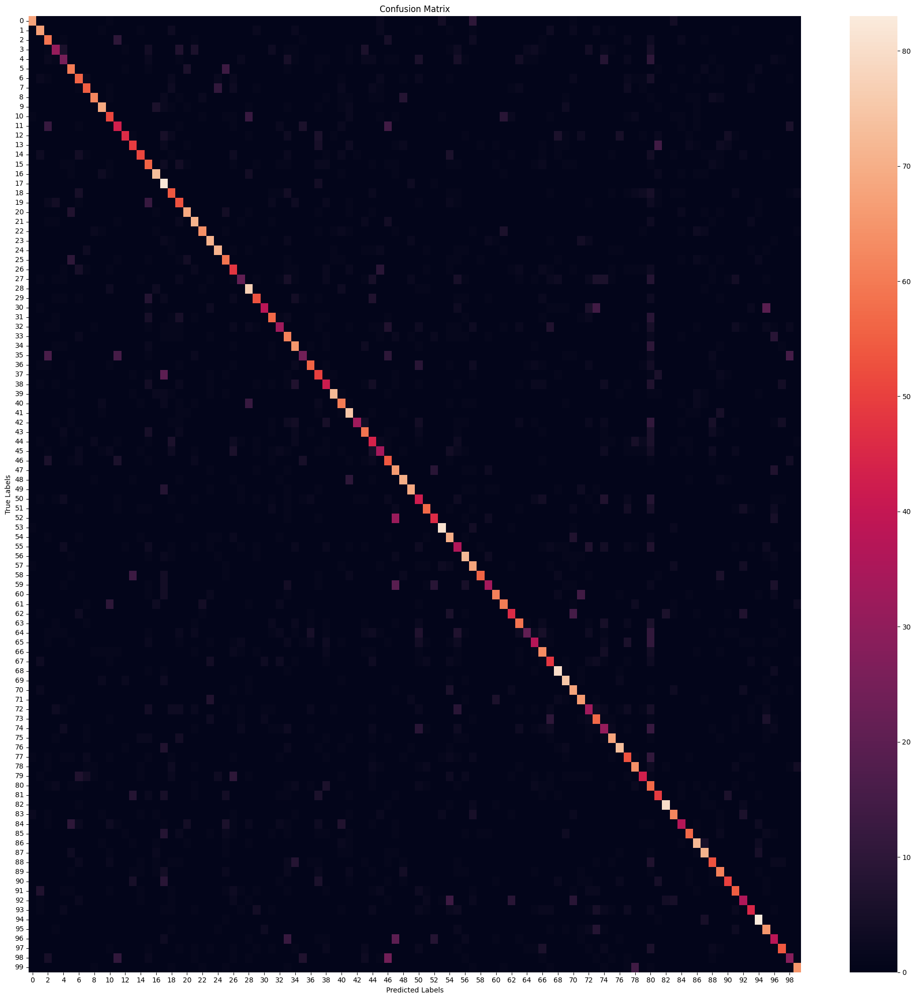

                   precision    recall  f1-score   support

           beaver       0.92      0.76      0.83        90
          dolphin       0.71      0.74      0.73        90
            otter       0.51      0.66      0.57        90
             seal       0.57      0.34      0.43        90
            whale       0.45      0.28      0.34        90
    aquarium fish       0.57      0.67      0.61        90
         flatfish       0.55      0.62      0.59        90
              ray       0.75      0.61      0.67        90
            shark       0.86      0.69      0.77        90
            trout       0.83      0.77      0.80        90
          orchids       0.59      0.57      0.58        90
          poppies       0.47      0.48      0.47        90
            roses       0.87      0.51      0.64        90
       sunflowers       0.60      0.54      0.57        90
           tulips       0.77      0.57      0.65        90
          bottles       0.43      0.62      0.51       

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)              │ (None, 7, 7, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_18          │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_40 (Dense)                     │ (None, 512)                 │       1,049,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_41 (Dense)                     │ (None, 100)                 │          51,300 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,665,188 (94.09 MB)

 Trainable params: 4,516,452 (17.23 MB)

 Non-trainable params: 20,148,736 (76.86 MB)

Epoch 1/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 46s 47ms/step - accuracy: 0.6156 - f1_score: 0.6130 - loss: 1.3864 - precision: 0.7737 - val_accuracy: 0.6382 - val_f1_score: 0.6365 - val_loss: 1.3361 - val_precision: 0.7803
Epoch 2/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6676 - f1_score: 0.6646 - loss: 1.1636 - precision: 0.8195 - val_accuracy: 0.6453 - val_f1_score: 0.6434 - val_loss: 1.3074 - val_precision: 0.7797
Epoch 3/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.6953 - f1_score: 0.6919 - loss: 1.0701 - precision: 0.8370 - val_accuracy: 0.6509 - val_f1_score: 0.6487 - val_loss: 1.2863 - val_precision: 0.7825
Epoch 4/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7095 - f1_score: 0.7068 - loss: 0.9907 - precision: 0.8449 - val_accuracy: 0.6562 - val_f1_score: 0.6541 - val_loss: 1.2732 - val_precision: 0.7836
Epoch 5/15
657/657 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7288 - f1_score: 0.7263 - loss: 0.9272 - precision: 0.8529 - val_acc

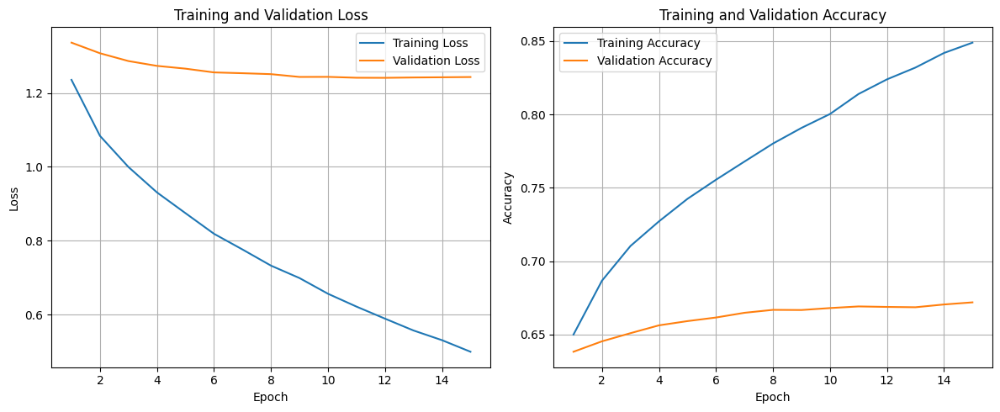

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.6578 - f1_score: 0.6511 - loss: 1.2572 - precision: 0.7712
Test Accuracy: 66.86%
Test Loss: 124.12%
Test Precision: 77.83%
Test F1 Scores (Per Class): [85.55555  80.42328  57.297295 51.396645 39.325836 69.71428  64.94845
 69.84126  84.883705 83.33333  64.36781  43.33333  67.75956  61.452507
 66.27907  62.983418 78.918915 79.166664 62.983418 63.73626  79.79274
 81.31868  79.55801  77.09496  78.68852  66.28571  58.139526 46.999992
 76.83616  71.856285 62.499992 72.51461  55.95237  58.585854 67.70833
 37.209297 68.508286 61.202175 54.23729  88.75739  68.39378  82.16216
 64.70587  71.65774  47.66839  47.05882  47.191006 56.497173 82.16216
 81.767944 41.860455 73.56321  62.365585 88.888885 71.287125 36.363632
 81.14285  74.03315  79.28994  63.855415 77.19298  73.56321  64.04494
 64.088394 49.122803 60.818714 67.42856  57.14285  87.00564  82.7957
 66.666664 75.39267  45.45454  60.540535 40.46242  81.11111  83.422455
 62.650597 67.415726

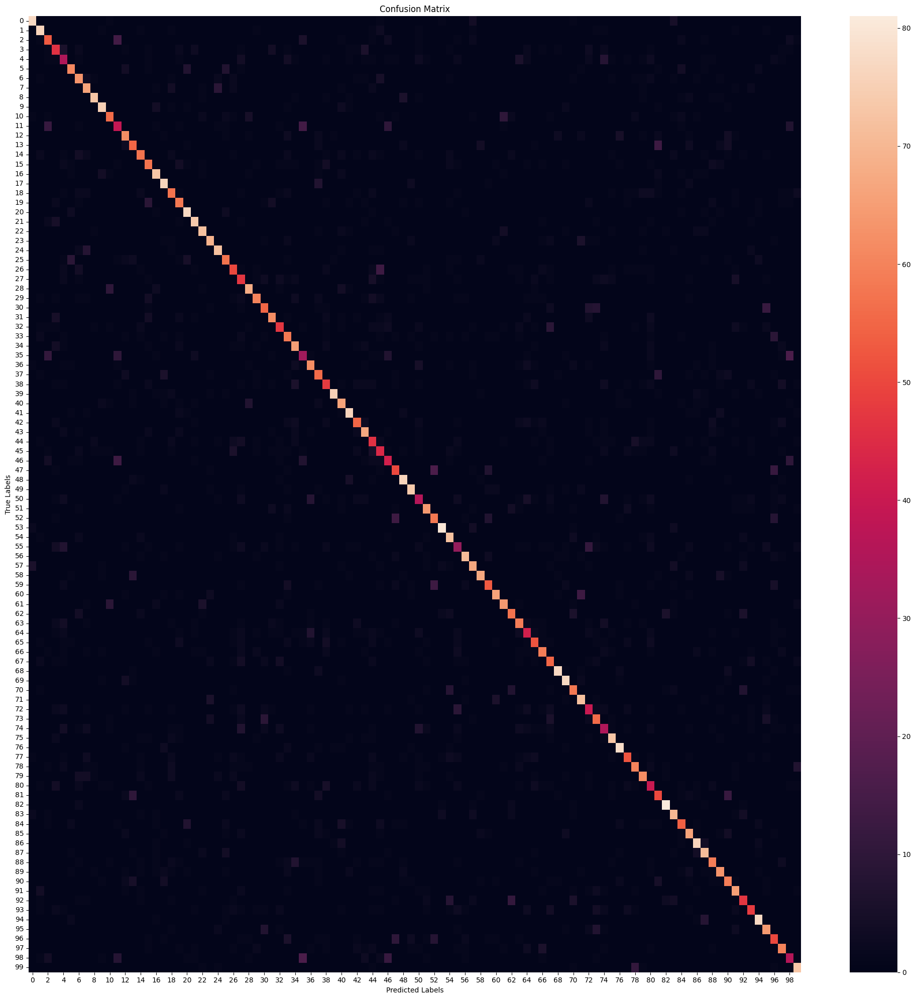

                   precision    recall  f1-score   support

           beaver       0.86      0.86      0.86        90
          dolphin       0.77      0.84      0.80        90
            otter       0.56      0.59      0.57        90
             seal       0.52      0.51      0.51        90
            whale       0.40      0.39      0.39        90
    aquarium fish       0.71      0.68      0.69        90
         flatfish       0.61      0.70      0.65        90
              ray       0.67      0.73      0.70        90
            shark       0.89      0.81      0.85        90
            trout       0.83      0.83      0.83        90
          orchids       0.67      0.62      0.64        90
          poppies       0.43      0.43      0.43        90
            roses       0.67      0.69      0.68        90
       sunflowers       0.62      0.61      0.61        90
           tulips       0.70      0.63      0.66        90
          bottles       0.63      0.63      0.63       

In [18]:
for repeat_2_times in range(2):
    #### <<<<<<<<<<Load and process data>>>>>>>>>>
    # Load CIFAR-100 dataset
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')

    # Split (8000) of training data into temporary set
    X_temp, X_train, y_temp, y_train = train_test_split(X_train, y_train, test_size=0.84, stratify=y_train, random_state=42)
    print(f"X_temp.shape: {X_temp.shape}\n")

    # Split temp data into equal validation (4000) and testing (4000) data
    X_temp_val, X_temp_test, y_temp_val, y_temp_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    print(f"X_temp_val.shape: {X_temp_val.shape}")
    print(f"y_temp_val.shape: {y_temp_val.shape}")
    print(f"X_temp_test.shape: {X_temp_test.shape}")
    print(f"y_temp_test.shape: {y_temp_test.shape}\n")

    # Split test data into validation (5000) and testing (5000)
    X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)

    # Add temp_val to validation (9000) and temp_test to testing (9000) to get a 70/15/15 data split
    X_val = np.concatenate((X_val, X_temp_val), axis=0)
    y_val = np.concatenate((y_val, y_temp_val), axis=0)
    X_test = np.concatenate((X_test, X_temp_test), axis=0)
    y_test = np.concatenate((y_test, y_temp_test), axis=0)

    print(f"X_train.shape: {X_train.shape}")
    print(f"y_train.shape: {y_train.shape}")
    print(f"X_val.shape: {X_val.shape}")
    print(f"y_val.shape: {y_val.shape}")
    print(f"X_test.shape: {X_test.shape}")
    print(f"y_test.shape: {y_test.shape}\n")

    def display_imgs(imgs, labels):
        plt.subplots(figsize=(10,10))
        for i in range(16):
            plt.subplot(4, 4, i+1)
            k = np.random.randint(0, imgs.shape[0])
            if i == 0:
                print(f"labels[{k}].shape: {labels[k].shape}")
                print(f"imgs[{k}].shape: {imgs[k].shape}")
            plt.imshow(imgs[k])
            #plt.title(labels[k])
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    display_imgs(X_train, y_train)

    # Normalise images (scale to range [0, 1]) - Improves convergence speed & accuracy
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    display_imgs(X_train, y_train)

    labels_names = ['beaver','dolphin','otter','seal','whale','aquarium fish','flatfish','ray','shark','trout',
                   'orchids','poppies','roses','sunflowers','tulips','bottles','bowls','cans','cups','plates',
                   'apples','mushrooms','oranges','pears','sweet peppers','clock','computer keyboard','lamp',
                   'telephone','television','bed','chair','couch','table','wardrobe','bee','beetle','butterfly',
                   'caterpillar','cockroach','bear','leopard','lion','tiger','wolf','bridge','castle','house',
                   'road','skyscraper','cloud','forest','mountain','plain','sea','camel','cattle','chimpanzee',
                   'elephant','kangaroo','fox','porcupine','possum','raccoon','skunk','crab','lobster','snail',
                   'spider','worm','baby','boy','girl','man','woman','crocodile','dinosaur','lizard','snake',
                   'turtle','hamster','mouse','rabbit','shrew','squirrel','maple','oak','palm','pine','willow',
                   'bicycle','bus','motorcycle','pickup truck','train','lawn-mower','rocket','streetcar','tank',
                   'tractor']

    def class_distrib(y, labels_names, dataset_name):
        counts = pd.DataFrame(data=y).value_counts().sort_index()
        #print(f"counts:\n{counts}")
        fig, ax = plt.subplots(figsize=(20,10))
        ax.bar(labels_names, counts)
        ax.set_xticklabels(labels_names, rotation=90, fontsize=15)
        plt.title(f"Distribution of '{dataset_name}' Dataset", fontsize=25)
        plt.grid()
        plt.tight_layout()
        plt.show()
    class_distrib(y_train, labels_names, "Training")
    class_distrib(y_val, labels_names, "Validating")
    class_distrib(y_test, labels_names, "Testing")

    # Create TensorFlow datasets

    batch_size = 64
    train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))

    val_dataset = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
                   .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                      tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                   .batch(batch_size)
                   .prefetch(tf.data.experimental.AUTOTUNE))

    test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                     .map(lambda x, y: (tf.image.resize(x, (224, 224)),
                                        tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))))  # Remove extra dimension
                    .batch(batch_size)
                    .prefetch(tf.data.experimental.AUTOTUNE))

    print(f"Training dataset:\n {train_dataset}")
    for img, lbl in train_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nValidation dataset:\n {val_dataset}")
    for img, lbl in val_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl
    print(f"\nTesting dataset:\n {test_dataset}")
    for img, lbl in test_dataset.take(1):
        #if isinstance(batch, tuple) and len(batch) == 2:
        print(f"Image shape: {img.shape}")  # Should be (batch_size, 224, 224, 3)
        print(f"Label shape: {lbl.shape}")  # Should be (batch_size, 10)
        del img,lbl


    #### <<<<<<<<<<Pre-trained model>>>>>>>>>>
    # Load ResNet50 pre-trained on ImageNet (w/out the top classification layer which is designed for ImageNet (diff dataset))
    resnet_50_base = tf.keras.applications.ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    # Freeze the layers of VGG16 so they don't get updated during training - can unfreeze for fine tuning later
    resnet_50_base.trainable = False

    # Add custom classification layers for CIFAR-100 (100 classes) - adapt model to CIFAR-100
    model = models.Sequential([
        resnet_50_base,
        layers.GlobalAveragePooling2D(), # Better for ResNet than Flatten
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(100, activation='softmax')  # CIFAR-100 has 100 classes
    ])

    for sample in test_dataset.take(1):
        print(type(sample))  # Should be <class 'tuple'>
        print(len(sample))  # Should be 2
        print(type(sample[0]), type(sample[1]))  # Both should be <class 'tensorflow.Tensor'>
        print(sample[0].shape)  # Should be (batch_size, 224, 224, 3)
        print(sample[1].shape)  # Should be (batch_size, 100)
    print(f"Model input shape: {model.input_shape}")
    print(f"Model output shape: {model.output_shape}")
    sample = next(iter(test_dataset.as_numpy_iterator()))
    print(len(sample))  # Should be 2
    print(type(sample[0]), type(sample[1]))  # Both should be <class 'numpy.ndarray'>
    print(sample[0].shape, sample[1].shape)  # Should match model input and output
    print("\n")
    #for x, y in test_dataset.take(1):
    #    print(type(x), type(y))  # Both should be <class 'tensorflow.Tensor'>
    #for x_batch, y_batch in test_dataset.take(1):
    #    test_loss, test_acc = model.evaluate(x_batch, y_batch)
    #    print(f"Test Loss: {test_loss}, Test Accuracy: {test_acc}")

    # Compile the model
    #tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs")
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-3, momentum=0.1),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>
    early_stopping = EarlyStopping(monitor='val_loss', # or val_accuracy
                                   patience=5, # Num. epochs with no improvements - help void overfitting
                                   restore_best_weights=True)
    #reduce_lr = ReduceLROnPlateau(monitor='val_loss', # or val_accuracy
    #                              factor=0.1, # Reduce lr by a factor
    #                              patience=3, # Num epochs w/ no improvement
    #                              min_lr=1e-6, # Min lr
    #                              verbose=1)
    #tensorboard = TensorBoard(log_dir='./logs', # Logs directory
    #                         histogram_freq=1, # Logs histograms for weights/activations
    #                         write_graph=True, # Logs graph of model
    #                         write_images=True) # Log images like weight histogram
    #checkpoint = ModelCheckpoint('best_model.h5',
    #                             monitor='val_loss', # or val_accuracy
    #                             save_best_only=True, # Save only best model
    #                             mode='min', # min for loss or max for accuracy
    #                             verbose=1)
    #cvs_logger = CSVLogger('training_log.csv', seperator=',', append=True) # Save train metrics to analyse

    # Train the model
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=25,
                        batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history.history['loss'])+1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    def plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc):
        # Plot Training and Validation Loss
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_loss, label='Training Loss')
        plt.plot(epochs, val_loss, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss')
        plt.legend()
        plt.grid()

        # Plot Training and Validation Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_acc, label='Training Accuracy')
        plt.plot(epochs, val_acc, label='Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))
    #tensorboard --logdir==path_to_your_logs

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    # Finally, display the hist DataFrame.
    hist

    #### <<<<<<<<<<Fine-Tune>>>>>>>>>>
    #### <<<<<<<<<<Adapt Model>>>>>>>>>>
    # Unfreeze last 10 layers
    for layer in resnet_50_base.layers[-10:]:
        layer.trainable = True # Allow layers to be updated

    # Compile again w/ lower learning rate (prevents destroying learned features)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', 'precision', 'f1_score'])

    model.summary()

    #### <<<<<<<<<<Modify Dataset>>>>>>>>>>
    def augment_dataset(x, y):
        x = tf.image.resize(x, (128, 128))  # Resize images
        x = tf.image.random_flip_left_right(x)  # Random horizontal flip
        x = tf.image.random_brightness(x, max_delta=0.2)  # Adjust brightness
        x = tf.image.random_contrast(x, lower=0.8, upper=1.2)  # Adjust contrast
        y = tf.squeeze(tf.one_hot(y, depth=100, dtype=tf.float32))  # One-hot encode labels
        return x, y
    train_dataset_aug = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                     .map(augment_dataset, num_parallel_calls=tf.data.experimental.AUTOTUNE)
                     .batch(batch_size)
                     .prefetch(tf.data.experimental.AUTOTUNE))
    # Not val or test as augment train helps generalise better, but want to provide consistent benchmark for eval perf

    #### <<<<<<<<<<Train Model & Track Training/Validation Error>>>>>>>>>>

    # Train the model
    history_fine_tune = model.fit(train_dataset, validation_data=val_dataset, epochs=15,
                                  batch_size=batch_size, callbacks=[early_stopping], verbose=1)

    #### <<<<<<<<<<Plot Training & Validation Error>>>>>>>>>>

    # Extract loss and accuracy
    epochs = range(1,len(history_fine_tune.history['loss'])+1)
    train_loss = history_fine_tune.history['loss']
    val_loss = history_fine_tune.history['val_loss']
    train_acc = history_fine_tune.history['accuracy']
    val_acc = history_fine_tune.history['val_accuracy']

    plot_evidence(epochs, train_loss, val_loss, train_acc, val_acc)

    #### <<<<<<<<<<Evaluate Model on Test Data>>>>>>>>>>

    # Evaluate on test data
    results = model.evaluate(test_dataset)
    test_loss = results[0]
    test_acc = results[1]
    test_precision = results[2]
    test_f1_scores = results[3]
    print(f"Test Accuracy: {test_acc*100:.2f}%")
    print(f"Test Loss: {test_loss*100:.2f}%")
    print(f"Test Precision: {test_precision*100:.2f}%")
    print(f"Test F1 Scores (Per Class): {test_f1_scores.numpy()*100}")
    print(f"Average Test F1 Scores:{np.average(test_f1_scores.numpy()*100):.2f}\n")

    #### <<<<<<<<<<Generate Confusion Matrix>>>>>>>>>>

    # Get predictions
    X_test_revised = tf.image.resize(X_test, (224, 224))
    y_pred = model.predict(X_test_revised)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = y_test.flatten()

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

    # Plot confusion matrix
    plt.figure(figsize=(20, 20))
    sns.heatmap(conf_matrix) #cmap='Blues', fmt='d'
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true_classes, y_pred_classes, target_names=labels_names))

    # Create a DataFrame from the history of the training and store the epoch values.
    hist = pd.DataFrame(history_fine_tune.history)
    hist['epoch'] = history_fine_tune.epoch

    # Finally, display the hist DataFrame.
    hist